<a href="https://colab.research.google.com/github/pranta2003/Fetal-health-prediction/blob/master/Capstone_fetalDataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Cell 2 — NOW verify your files, using the full path as data
import os

data_path = "/content/drive/MyDrive/fetal-health-project/data/raw"

expected_files = []
for yr in range(2016, 2024):
    expected_files.append(f"{yr}_NATAL.csv")
    expected_files.append(f"{yr}_FETAL_COD.csv")

print(f"Checking {data_path}\n")
missing = []
for fname in expected_files:
    full_path = os.path.join(data_path, fname)
    if os.path.exists(full_path):
        size_mb = os.path.getsize(full_path) / (1024 * 1024)
        print(f"gotcha {fname} — {size_mb:.1f} MB")
    else:
        print(f"not find MISSING: {fname}")
        missing.append(fname)

print(f"\n{'All 16 files found!' if not missing else f'{len(missing)} files still missing.'}")

Checking /content/drive/MyDrive/fetal-health-project/data/raw

gotcha 2016_NATAL.csv — 5972.4 MB
gotcha 2016_FETAL_COD.csv — 15.6 MB
gotcha 2017_NATAL.csv — 5945.1 MB
gotcha 2017_FETAL_COD.csv — 14.9 MB
gotcha 2018_NATAL.csv — 5855.1 MB
gotcha 2018_FETAL_COD.csv — 13.7 MB
gotcha 2019_NATAL.csv — 5787.4 MB
gotcha 2019_FETAL_COD.csv — 13.4 MB
gotcha 2020_NATAL.csv — 5575.2 MB
gotcha 2020_FETAL_COD.csv — 12.2 MB
gotcha 2021_NATAL.csv — 5652.4 MB
gotcha 2021_FETAL_COD.csv — 12.5 MB
gotcha 2022_NATAL.csv — 5661.8 MB
gotcha 2022_FETAL_COD.csv — 11.9 MB
gotcha 2023_NATAL.csv — 5552.5 MB
gotcha 2023_FETAL_COD.csv — 11.7 MB

All 16 files found!


In [ ]:
import pandas as pd
import os

# Session crashed, so restart your runtime first (Runtime > Restart session),
# then re-mount Drive before running this cell

os.makedirs("/content/drive/MyDrive/fetal-health-project/data/processed", exist_ok=True)

years = range(2016, 2024)

WANTED_COLS = ['ATTEND', 'BFACIL', 'BFACIL3', 'BMI', 'BMI_R', 'BWTR4', 'CIG_0', 'CIG_1',
    'CIG_2', 'CIG_3', 'CIG_REC', 'COMBGEST', 'DBWT', 'DLMP_MM', 'DLMP_YY', 'DMETH_REC',
    'DPLURAL', 'FAGECOMB', 'FAGEREC11', 'FAGERPT_FLG', 'F_CIGS_0', 'F_CIGS_1', 'F_CIGS_2',
    'F_CIGS_3', 'F_MEDUC', 'F_MM_AICU', 'F_MPCB', 'F_M_HT', 'F_PWGT', 'F_RF_CESAR',
    'F_RF_GDIAB', 'F_RF_GHYPER', 'F_RF_NCESAR', 'F_RF_PDIAB', 'F_RF_PHYPER', 'F_TOBACO',
    'F_WIC', 'ILLB_R', 'ILLB_R11', 'IMP_PLUR', 'IMP_SEX', 'LBO_REC', 'MAGER', 'MAGER14',
    'MAGER9', 'MAGE_IMPFLG', 'MAGE_REPFLG', 'MBSTATE_REC', 'MEDUC', 'ME_PRES', 'ME_ROUT',
    'ME_TRIAL', 'MHISPX', 'MM_AICU', 'MM_RUPT', 'MRACE15', 'MRACE6', 'MRACEHISP',
    'MRACEIMP', 'M_Ht_In', 'OBGEST_FLG', 'OEGest_Comb', 'PRECARE', 'PRIORDEAD',
    'PRIORLIVE', 'PWgt_R', 'RDMETH_REC', 'RESTATUS', 'RF_ARTEC', 'RF_CESAR', 'RF_CESARN',
    'RF_EHYPE', 'RF_FEDRG', 'RF_GDIAB', 'RF_GHYPE', 'RF_INFTR', 'SEX', 'WIC']

CHUNK_SIZE = 200_000
SAMPLE_PER_YEAR = 45_000

def get_available_cols(path, wanted_cols):
    header = pd.read_csv(path, nrows=0).columns.tolist()
    available = [c for c in wanted_cols if c in header]
    missing = [c for c in wanted_cols if c not in header]
    return available, missing

def count_rows_chunked(path, one_col, chunksize=CHUNK_SIZE):
    """Cheap pass — reads only 1 column to count total rows without heavy memory use"""
    total = 0
    for chunk in pd.read_csv(path, usecols=[one_col], chunksize=chunksize, low_memory=False):
        total += len(chunk)
    return total

def sample_csv_chunked(path, available_cols, missing_cols, target_n, chunksize=CHUNK_SIZE):
    """Reads the file in chunks, keeping only a small random slice of each chunk —
    the full file is NEVER held in memory at once, which is what fixes the crash"""
    total_rows = count_rows_chunked(path, available_cols[0], chunksize)
    frac = min(1.0, target_n / total_rows) if total_rows > 0 else 0

    sampled_chunks = []
    for chunk in pd.read_csv(path, usecols=available_cols, chunksize=chunksize, low_memory=False):
        if frac < 1.0:
            chunk = chunk.sample(frac=frac, random_state=42)
        sampled_chunks.append(chunk)

    result = pd.concat(sampled_chunks, ignore_index=True)
    if len(result) > target_n:
        result = result.sample(n=target_n, random_state=42)
    for col in missing_cols:
        result[col] = pd.NA
    return result, total_rows

birth_frames = []
for yr in years:
    path = f"/content/drive/MyDrive/fetal-health-project/data/raw/{yr}_NATAL.csv"
    available, missing = get_available_cols(path, WANTED_COLS)
    if missing:
        print(f"{yr}: missing columns filled as NaN → {missing}")
    df_sample, total_rows = sample_csv_chunked(path, available, missing, SAMPLE_PER_YEAR)
    df_sample["OUTCOME"] = 0
    df_sample["YEAR"] = yr
    birth_frames.append(df_sample)
    print(f"{yr}: sampled {len(df_sample)} rows out of {total_rows:,} total")
    del df_sample

livebirth_data = pd.concat(birth_frames, ignore_index=True)
print(f"\nTotal live birth rows: {len(livebirth_data)}")
livebirth_data.to_csv("/content/drive/MyDrive/fetal-health-project/data/processed/livebirth_sampled_all_years.csv", index=False)
print(" Saved successfully")

2016: missing columns filled as NaN → ['F_RF_CESAR', 'F_RF_NCESAR', 'MHISPX', 'RF_CESAR', 'RF_CESARN']
2016: sampled 45000 rows out of 3,956,112 total
2017: missing columns filled as NaN → ['MHISPX']
2017: sampled 45000 rows out of 3,864,754 total
2018: sampled 44991 rows out of 3,801,534 total
2019: sampled 44997 rows out of 3,757,582 total
2020: sampled 44994 rows out of 3,619,826 total
2021: sampled 44993 rows out of 3,669,928 total
2022: sampled 44995 rows out of 3,676,029 total
2023: sampled 44991 rows out of 3,605,081 total

Total live birth rows: 359961
✅ Saved successfully


 Tabular Dataset : Missing values per column (top 10)

In [ ]:
stillbirth = pd.read_csv("/content/drive/MyDrive/fetal-health-project/data/processed/stillbirth_all_years.csv")
livebirth = pd.read_csv("/content/drive/MyDrive/fetal-health-project/data/processed/livebirth_sampled_all_years.csv")

final = pd.concat([stillbirth, livebirth], ignore_index=True)
final = final.sample(frac=1, random_state=42).reset_index(drop=True)

print("Final shape:", final.shape)
print(final["OUTCOME"].value_counts())
print("\nMissing values per column (top 10):")
print(final.isna().sum().sort_values(ascending=False).head(10))

final.to_csv("/content/drive/MyDrive/fetal-health-project/data/processed/clinical_training_data.csv", index=False)
print("\n Saved clinical_training_data.csv — ready for train_clinical_model.py")

/tmp/ipykernel_738/1881883685.py:2: DtypeWarning: Columns (76) have mixed types. Specify dtype option on import or set low_memory=False.
  livebirth = pd.read_csv("/content/drive/MyDrive/fetal-health-project/data/processed/livebirth_sampled_all_years.csv")


Final shape: (718136, 80)
OUTCOME
0    359961
1    358175
Name: count, dtype: int64

Missing values per column (top 10):
MAGE_IMPFLG    356422
FAGERPT_FLG    356102
IMP_PLUR       355693
MAGE_REPFLG    352380
IMP_SEX        352316
MRACEIMP       302416
OBGEST_FLG     290891
MHISPX          90000
RF_CESAR        52691
RF_CESARN       52691
dtype: int64

 Saved clinical_training_data.csv — ready for train_clinical_model.py


In [ ]:
df = pd.read_csv("/content/drive/MyDrive/fetal-health-project/data/processed/clinical_training_data.csv")
print("Shape:", df.shape)
print("Class balance:\n", df["OUTCOME"].value_counts(normalize=True))
print("\nSample rows:\n", df.sample(5))

Shape: (718136, 80)
Class balance:
 OUTCOME
0    0.501243
1    0.498757
Name: proportion, dtype: float64

Sample rows:
         BFACIL  BFACIL3 MAGE_IMPFLG MAGE_REPFLG  MAGER  MAGER14  MAGER9  \
694147     1.0        1         NaN         NaN     31       10       5   
217633     1.0        1         NaN         NaN     43       12       7   
246335     1.0        1                             30       10       5   
409123     1.0        1                             33       10       5   
576641     1.0        1                             25        9       4   

        MBSTATE_REC  RESTATUS  MRACE6  ...  F_RF_CESAR F_RF_NCESAR  F_MM_AICU  \
694147            1         2     2.0  ...         1.0         1.0        1.0   
217633            1         2     1.0  ...         1.0         1.0        1.0   
246335            1         2     1.0  ...         1.0         1.0        1.0   
409123            1         1     2.0  ...         1.0         1.0        1.0   
576641            1     

In [ ]:
# Paste this whole script into a new Colab cell — it already has the
# correct Drive path built in, ready to run as-is

DATA_PATH = "/content/drive/MyDrive/fetal-health-project/data/processed/clinical_training_data.csv"
MODEL_OUT_PATH = "/content/drive/MyDrive/fetal-health-project/models/stream3_clinical_xgb.json"

# --- paste the rest of the script's contents below this line ---

#Stram - 3 value check and AUC check from tabular dataset

In [ ]:
#Stram - 3 value check and AUC check from tabular dataset

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, roc_auc_score
import xgboost as xgb
import os

RANDOM_SEED = 42
DATA_PATH = "/content/drive/MyDrive/fetal-health-project/data/processed/clinical_training_data.csv"
MODEL_OUT_PATH = "/content/drive/MyDrive/fetal-health-project/models/stream3_clinical_xgb.json"

TARGET_COLUMN = "OUTCOME"

# Retrain WITHOUT COMBGEST to get an honest "floor" performance number
# using only genuine maternal risk factors, no registry-timing artifact

NUMERIC_FEATURES_NO_GA = ["MAGER", "BMI", "PRECARE", "PRIORDEAD", "PRIORLIVE", "MEDUC"]

X_no_ga = df[NUMERIC_FEATURES_NO_GA + CATEGORICAL_FEATURES]
y = df[TARGET_COLUMN]
X_train, X_test, y_train, y_test = train_test_split(X_no_ga, y, test_size=0.2, random_state=42, stratify=y)

# reuse your existing build_pipeline(), just swap which NUMERIC_FEATURES list it references



CATEGORICAL_FEATURES = [
    "RF_GDIAB", "RF_GHYPE", "RF_EHYPE", "RF_CESAR", "RF_ARTEC", "RF_INFTR",
    "RF_FEDRG", "CIG_REC", "WIC", "DPLURAL", "SEX", "MRACE6",
    "MBSTATE_REC",
]

UNKNOWN_CODES = ["U", "9", "99", "Unknown"]
NUMERIC_UNKNOWN_CODES = {"COMBGEST": [99]}

def load_data(path=DATA_PATH):
    if not os.path.exists(path):
        raise FileNotFoundError(f"Could not find {path}.")
    df = pd.read_csv(path)
    print(f"Loaded combined clinical dataset: {df.shape[0]} rows, {df.shape[1]} columns")
    missing_needed = [c for c in NUMERIC_FEATURES + CATEGORICAL_FEATURES + [TARGET_COLUMN]
                       if c not in df.columns]
    if missing_needed:
        raise KeyError(f"Expected column(s) not found: {missing_needed}")
    return df

def clean_unknown_codes(df):
    before_counts = {col: (df[col].isin(UNKNOWN_CODES)).sum() for col in CATEGORICAL_FEATURES}
    for col in CATEGORICAL_FEATURES:
        df[col] = df[col].replace(UNKNOWN_CODES, np.nan)
    print(f"Replaced {sum(before_counts.values())} Unknown-coded categorical values")
    for col, codes in NUMERIC_UNKNOWN_CODES.items():
        before = df[col].isin(codes).sum()
        df[col] = df[col].replace(codes, np.nan)
        print(f"{col}: {before} sentinel values {codes} converted to NaN")
    return df

def build_pipeline():
    preprocessor = ColumnTransformer(transformers=[
        ("numeric", SimpleImputer(strategy="median"), NUMERIC_FEATURES),
        ("categorical", Pipeline(steps=[
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), CATEGORICAL_FEATURES),
    ])
    model = xgb.XGBClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        eval_metric="logloss", random_state=RANDOM_SEED,
    )
    return Pipeline(steps=[("preprocess", preprocessor), ("model", model)])

def train(df):
    X = df[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
    y = df[TARGET_COLUMN]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
    )
    pipeline = build_pipeline()
    pipeline.fit(X_train, y_train)
    preds = pipeline.predict(X_test)
    proba = pipeline.predict_proba(X_test)[:, 1]
    print("\n--- Stream 3 Clinical Risk Model: Evaluation ---")
    print(classification_report(y_test, preds, target_names=["Healthy/Live Birth", "Stillbirth"]))
    print(f"AUC-ROC: {roc_auc_score(y_test, proba):.4f}")
    return pipeline

df = load_data()
df = clean_unknown_codes(df)

print("\nCOMBGEST by outcome, after cleaning:")
print(df.groupby("OUTCOME")["COMBGEST"].describe())

pipeline = train(df)

os.makedirs(os.path.dirname(MODEL_OUT_PATH), exist_ok=True)
pipeline.named_steps["model"].save_model(MODEL_OUT_PATH)
print(f"\nModel saved to {MODEL_OUT_PATH}")

Loaded combined clinical dataset: 718136 rows, 80 columns
Replaced 1039563 Unknown-coded categorical values
COMBGEST: 12188 sentinel values [99] converted to NaN

COMBGEST by outcome, after cleaning:
            count       mean        std   min   25%   50%   75%   max
OUTCOME                                                              
0        359685.0  38.559067   2.475167  17.0  38.0  39.0  40.0  47.0
1        346263.0  19.604070  10.764422   2.0  10.0  20.0  28.0  47.0

--- Stream 3 Clinical Risk Model: Evaluation ---
                    precision    recall  f1-score   support

Healthy/Live Birth       0.90      0.95      0.92     71993
        Stillbirth       0.95      0.89      0.92     71635

          accuracy                           0.92    143628
         macro avg       0.92      0.92      0.92    143628
      weighted avg       0.92      0.92      0.92    143628

AUC-ROC: 0.9684

Model saved to /content/drive/MyDrive/fetal-health-project/models/stream3_clinical_xgb.jso

## AUC-ROC: 0.9684

In [ ]:
feature_names = (NUMERIC_FEATURES +
    list(pipeline.named_steps["preprocess"].transformers_[1][1]
         .named_steps["onehot"].get_feature_names_out(CATEGORICAL_FEATURES)))

importances = pipeline.named_steps["model"].feature_importances_
top_15 = sorted(zip(feature_names, importances), key=lambda x: -x[1])[:15]

for name, score in top_15:
    print(f"{name}: {score:.4f}")

COMBGEST: 0.4336
DMETH_REC_9: 0.1361
PRIORDEAD: 0.0890
PRECARE: 0.0872
MBSTATE_REC_3: 0.0393
DMETH_REC_2: 0.0367
MEDUC: 0.0287
WIC_N: 0.0155
DMETH_REC_1: 0.0119
WIC_Y: 0.0112
DPLURAL_1: 0.0109
CIG_REC_Y: 0.0079
MRACE6_2.0: 0.0075
BMI: 0.0068
CIG_REC_N: 0.0062


In [ ]:
print(df[df["OUTCOME"] == 1]["COMBGEST"].value_counts().sort_index().head(20))

COMBGEST
2.0       962
3.0      1442
4.0      3410
5.0      7115
6.0     14921
7.0     13973
8.0     21057
9.0     20148
10.0    19002
11.0    14487
12.0    11676
13.0     7840
14.0     5939
15.0     5475
16.0     6216
17.0     6211
18.0     6298
19.0     6926
20.0    16564
21.0    15884
Name: count, dtype: int64


#Layer - 3 , Hadlock Formula applying

In [ ]:
#Layer - 3 , Hadlock Formula applying


def calculate_efw(hc_mm, bpd_mm, ac_mm, fl_mm):
    """Hadlock 1985 four-parameter EFW formula.
    Inputs in millimeters (matching your pipeline's standardized units) —
    internally converted to cm, since Hadlock's coefficients are cm-calibrated."""
    hc_cm, bpd_cm, ac_cm, fl_cm = hc_mm/10, bpd_mm/10, ac_mm/10, fl_mm/10
    log10_efw = (
        1.3596
        - 0.00386 * (ac_cm * fl_cm)
        + 0.0064 * hc_cm
        + 0.00061 * (bpd_cm * ac_cm)
        + 0.0424 * ac_cm
        + 0.174 * fl_cm
    )
    return 10 ** log10_efw

efw = calculate_efw(hc_mm=280, bpd_mm=80, ac_mm=250, fl_mm=55)
print(f"Test EFW: {efw:.1f} grams")  # should print ~1403.0

Test EFW: 1403.0 grams


## Test EFW: 1403.0 grams

In [ ]:
import math
from scipy.stats import norm

def calculate_efw(hc_mm, bpd_mm, ac_mm, fl_mm):
    """Hadlock 1985 four-parameter EFW formula. Inputs in mm, converted
    to cm internally since Hadlock's coefficients are cm-calibrated."""
    hc_cm, bpd_cm, ac_cm, fl_cm = hc_mm/10, bpd_mm/10, ac_mm/10, fl_mm/10
    log10_efw = (1.3596 - 0.00386*(ac_cm*fl_cm) + 0.0064*hc_cm
                 + 0.00061*(bpd_cm*ac_cm) + 0.0424*ac_cm + 0.174*fl_cm)
    return 10 ** log10_efw

def hadlock_reference_mean_sd(ga_weeks):
    """Hadlock et al. 1991 fetal weight reference standard.
    Mean EFW from the paper's published regression equation;
    SD as a uniform 12.7% coefficient of variation, per the paper."""
    mean = math.exp(0.578 + 0.332*ga_weeks - 0.00354*(ga_weeks**2))
    sd = 0.127 * mean
    return mean, sd

def growth_percentile(efw_grams, ga_weeks):
    """Converts an EFW at a given gestational age into a percentile
    against the Hadlock 1991 reference standard."""
    mean, sd = hadlock_reference_mean_sd(ga_weeks)
    z = (efw_grams - mean) / sd
    percentile = norm.cdf(z) * 100
    return percentile, z

def flag_growth_restriction(percentile, threshold=10):
    """Standard clinical convention: <10th percentile = growth-restricted."""
    return percentile < threshold

# HC18 dataset

In [ ]:
# HC18 datset check

from torchvision import transforms

# Data augmentation for training (matches your project's original plan)
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# Validation data — NO augmentation, we want to evaluate on clean images
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])


def train_hc_model(train_loader, val_loader, max_epochs=150, lr=1e-4, patience=10):
    model = build_hc_model().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=5)
    criterion = nn.MSELoss()

    best_val_loss = float("inf")
    epochs_no_improve = 0
    best_model_state = None

    for epoch in range(max_epochs):
        model.train()
        train_loss = 0
        for images, targets in train_loader:
            images, targets = images.to(DEVICE), targets.to(DEVICE)
            optimizer.zero_grad()
            preds = model(images)
            loss = criterion(preds, targets)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
        train_loss /= len(train_loader)

        model.eval()
        val_loss = 0
        with torch.no_grad():
            for images, targets in val_loader:
                images, targets = images.to(DEVICE), targets.to(DEVICE)
                preds = model(images)
                val_loss += criterion(preds, targets).item()
        val_loss /= len(val_loader)

        scheduler.step(val_loss)

        print(f"Epoch {epoch+1}/{max_epochs} - train_loss: {train_loss:.4f} - val_loss: {val_loss:.4f} "
              f"- lr: {optimizer.param_groups[0]['lr']:.6f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_state = model.state_dict()
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        if epochs_no_improve >= patience:
            print(f"\nNo improvement for {patience} epochs — stopping early at epoch {epoch+1}.")
            break

    model.load_state_dict(best_model_state)  # restore the BEST version, not the last
    print(f"\nBest val_loss achieved: {best_val_loss:.4f} (RMSE ~ {best_val_loss**0.5:.1f} mm combined)")
    return model

In [ ]:
print(DRIVE_ROOT, DEVICE, HC18Dataset, build_hc_model)

/content/drive/MyDrive/fetal-health-project/data/raw/HC18 cuda <class '__main__.HC18Dataset'> <function build_hc_model at 0x7f08ab434860>


In [ ]:
# ---- Setup ----
base_dataset = HC18Dataset(
    csv_path=f"{DRIVE_ROOT}/training_set_pixel_size_and_HC.csv",
    image_dir=f"{DRIVE_ROOT}/training_set",
    transform=val_transform
)

val_size = int(0.15 * len(base_dataset))
train_size = len(base_dataset) - val_size
train_ds, val_ds = torch.utils.data.random_split(base_dataset, [train_size, val_size])

train_ds.dataset = HC18Dataset(
    csv_path=f"{DRIVE_ROOT}/training_set_pixel_size_and_HC.csv",
    image_dir=f"{DRIVE_ROOT}/training_set",
    transform=train_transform
)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=2)

print(f"Training on {DEVICE} | train: {len(train_ds)}, val: {len(val_ds)}")

model = train_hc_model(train_loader, val_loader, max_epochs=150, patience=10)

os.makedirs("/content/drive/MyDrive/fetal-health-project/models", exist_ok=True)
torch.save(model.state_dict(), "/content/drive/MyDrive/fetal-health-project/models/hc18_convnext_tiny.pt")
print("Model saved.")

Training on cuda | train: 850, val: 149
Epoch 1/150 - train_loss: 12395.3704 - val_loss: 10617.3188 - lr: 0.000100
Epoch 2/150 - train_loss: 10681.6987 - val_loss: 9319.9950 - lr: 0.000100
Epoch 3/150 - train_loss: 9385.2678 - val_loss: 8089.3546 - lr: 0.000100
Epoch 4/150 - train_loss: 8181.9995 - val_loss: 7006.7763 - lr: 0.000100
Epoch 5/150 - train_loss: 7144.4819 - val_loss: 6077.0413 - lr: 0.000100
Epoch 6/150 - train_loss: 6402.2310 - val_loss: 5255.1259 - lr: 0.000100
Epoch 7/150 - train_loss: 5549.2342 - val_loss: 4562.5183 - lr: 0.000100
Epoch 8/150 - train_loss: 4896.5661 - val_loss: 3995.3847 - lr: 0.000100
Epoch 9/150 - train_loss: 4335.9133 - val_loss: 3500.3112 - lr: 0.000100
Epoch 10/150 - train_loss: 3934.0757 - val_loss: 3080.3417 - lr: 0.000100
Epoch 11/150 - train_loss: 3510.8605 - val_loss: 2826.7500 - lr: 0.000100
Epoch 12/150 - train_loss: 3329.9629 - val_loss: 2410.5331 - lr: 0.000100
Epoch 13/150 - train_loss: 2741.9098 - val_loss: 2295.6549 - lr: 0.000100
Epoc

In [ ]:
#checking fetus HC and BPD ratio value where they are perfectly initiallized or not



import pandas as pd

df = pd.read_csv(f"{DRIVE_ROOT}/training_set_pixel_size_and_HC.csv")

ratios = []
for _, row in df.sample(20, random_state=42).iterrows():
    mask_filename = row["filename"].replace(".png", "_Annotation.png")
    mask_path = f"{DRIVE_ROOT}/training_set/{mask_filename}"
    bpd = extract_bpd_from_mask(mask_path, row["pixel size(mm)"])
    hc_given = row["head circumference (mm)"]
    ratio = hc_given / bpd
    ratios.append(ratio)
    print(f"{row['filename']}: HC={hc_given:.1f}mm, BPD={bpd:.1f}mm, ratio={ratio:.2f}")

import numpy as np
print(f"\nAverage HC/BPD ratio across sample: {np.mean(ratios):.2f}")
print("(Expect roughly 2.8-3.5 for a normal head shape — confirms extraction is anatomically correct)")

368_HC.png: HC=166.2mm, BPD=42.6mm, ratio=3.90
643_HC.png: HC=213.6mm, BPD=60.4mm, ratio=3.54
166_HC.png: HC=116.8mm, BPD=34.5mm, ratio=3.39
245_2HC.png: HC=159.5mm, BPD=41.6mm, ratio=3.83
599_HC.png: HC=186.9mm, BPD=52.3mm, ratio=3.57
469_2HC.png: HC=166.7mm, BPD=49.4mm, ratio=3.37
725_HC.png: HC=287.1mm, BPD=81.7mm, ratio=3.51
441_HC.png: HC=176.5mm, BPD=47.5mm, ratio=3.71
355_HC.png: HC=180.6mm, BPD=51.0mm, ratio=3.54
549_HC.png: HC=169.5mm, BPD=47.1mm, ratio=3.60
756_HC.png: HC=283.0mm, BPD=80.6mm, ratio=3.51
513_HC.png: HC=178.5mm, BPD=50.2mm, ratio=3.56
704_HC.png: HC=269.0mm, BPD=74.4mm, ratio=3.62
487_HC.png: HC=176.5mm, BPD=50.9mm, ratio=3.47
583_2HC.png: HC=183.0mm, BPD=50.1mm, ratio=3.65
059_HC.png: HC=76.2mm, BPD=21.9mm, ratio=3.48
671_2HC.png: HC=244.8mm, BPD=70.3mm, ratio=3.48
381_HC.png: HC=170.4mm, BPD=46.0mm, ratio=3.71
308_HC.png: HC=166.9mm, BPD=47.5mm, ratio=3.52
165_HC.png: HC=112.7mm, BPD=33.2mm, ratio=3.39

Average HC/BPD ratio across sample: 3.57
(Expect roughly

In [ ]:
#value check of HC MAE error , if abnormal value are not found here then have to procced next


model.eval()
hc_errors, bpd_errors = [], []

with torch.no_grad():
    for images, targets in val_loader:
        images, targets = images.to(DEVICE), targets.to(DEVICE)
        preds = model(images)
        hc_errors.extend((preds[:, 0] - targets[:, 0]).abs().cpu().tolist())
        bpd_errors.extend((preds[:, 1] - targets[:, 1]).abs().cpu().tolist())

import numpy as np
hc_mae = np.mean(hc_errors)
bpd_mae = np.mean(bpd_errors)
hc_rmse = np.sqrt(np.mean(np.array(hc_errors)**2))
bpd_rmse = np.sqrt(np.mean(np.array(bpd_errors)**2))

print(f"HC  -> MAE: {hc_mae:.2f}mm, RMSE: {hc_rmse:.2f}mm")
print(f"BPD -> MAE: {bpd_mae:.2f}mm, RMSE: {bpd_rmse:.2f}mm")

HC  -> MAE: 10.22mm, RMSE: 16.07mm
BPD -> MAE: 3.03mm, RMSE: 4.75mm


In [ ]:
### HC mainly still came out with the worse relative error.


#dominant on combined error. 10x then BPD cuz When two targets sit on very different scales in the same loss function,
#the optimizer effectively gets pulled around unevenly, which can make training noisier for both targets rather than
#cleanly prioritizing the bigger one.
#putting both HC and BPD on the same scale (mean 0, std 1) before computing the loss,
#so the model receives balanced, comparable error signals for both, then converting back to real millimeters

#Apporach A : Direct Rigression

import numpy as np

# ---- Step 1: compute normalization stats from the TRAINING split only ----
# (never include validation data when computing these — that would leak
# information about val data into training, a subtle but real mistake to avoid)

train_indices = train_ds.indices
train_csv = base_dataset.data.iloc[train_indices]

hc_values = train_csv["head circumference (mm)"].values
hc_mean, hc_std = hc_values.mean(), hc_values.std()

bpd_values = []
for _, row in train_csv.iterrows():
    mask_filename = row["filename"].replace(".png", "_Annotation.png")
    mask_path = f"{DRIVE_ROOT}/training_set/{mask_filename}"
    bpd_values.append(extract_bpd_from_mask(mask_path, row["pixel size(mm)"]))
bpd_values = np.array(bpd_values)
bpd_mean, bpd_std = bpd_values.mean(), bpd_values.std()

print(f"HC  stats -> mean: {hc_mean:.1f}, std: {hc_std:.1f}")
print(f"BPD stats -> mean: {bpd_mean:.1f}, std: {bpd_std:.1f}")

target_mean = torch.tensor([hc_mean, bpd_mean], dtype=torch.float32).to(DEVICE)
target_std = torch.tensor([hc_std, bpd_std], dtype=torch.float32).to(DEVICE)


def train_hc_model_normalized(train_loader, val_loader, target_mean, target_std,
                               max_epochs=150, lr=1e-4, patience=10):
    model = build_hc_model().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=5)
    criterion = nn.MSELoss()

    best_val_loss = float("inf")
    epochs_no_improve = 0
    best_model_state = None

    for epoch in range(max_epochs):
        model.train()
        train_loss = 0
        for images, targets in train_loader:
            images, targets = images.to(DEVICE), targets.to(DEVICE)
            targets_norm = (targets - target_mean) / target_std  # <-- normalize here

            optimizer.zero_grad()
            preds_norm = model(images)
            loss = criterion(preds_norm, targets_norm)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
        train_loss /= len(train_loader)

        model.eval()
        val_loss = 0
        with torch.no_grad():
            for images, targets in val_loader:
                images, targets = images.to(DEVICE), targets.to(DEVICE)
                targets_norm = (targets - target_mean) / target_std
                preds_norm = model(images)
                val_loss += criterion(preds_norm, targets_norm).item()
        val_loss /= len(val_loader)

        scheduler.step(val_loss)
        print(f"Epoch {epoch+1}/{max_epochs} - train_loss: {train_loss:.4f} - val_loss: {val_loss:.4f} "
              f"- lr: {optimizer.param_groups[0]['lr']:.6f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_state = model.state_dict()
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        if epochs_no_improve >= patience:
            print(f"\nNo improvement for {patience} epochs — stopping early at epoch {epoch+1}.")
            break

    model.load_state_dict(best_model_state)
    return model


# ---- Train with normalization ----
model = train_hc_model_normalized(train_loader, val_loader, target_mean, target_std,
                                   max_epochs=150, patience=10)

os.makedirs("/content/drive/MyDrive/fetal-health-project/models", exist_ok=True)
torch.save(model.state_dict(), "/content/drive/MyDrive/fetal-health-project/models/hc18_convnext_tiny_normalized.pt")
print("Model saved.")

# ---- Evaluate in REAL mm — must denormalize predictions first ----
model.eval()
hc_errors, bpd_errors = [], []
with torch.no_grad():
    for images, targets in val_loader:
        images, targets = images.to(DEVICE), targets.to(DEVICE)
        preds_norm = model(images)
        preds = preds_norm * target_std + target_mean  # <-- denormalize back to real mm
        hc_errors.extend((preds[:, 0] - targets[:, 0]).abs().cpu().tolist())
        bpd_errors.extend((preds[:, 1] - targets[:, 1]).abs().cpu().tolist())

hc_mae = np.mean(hc_errors)
bpd_mae = np.mean(bpd_errors)
hc_rmse = np.sqrt(np.mean(np.array(hc_errors)**2))
bpd_rmse = np.sqrt(np.mean(np.array(bpd_errors)**2))

print(f"\nHC  -> MAE: {hc_mae:.2f}mm, RMSE: {hc_rmse:.2f}mm")
print(f"BPD -> MAE: {bpd_mae:.2f}mm, RMSE: {bpd_rmse:.2f}mm")

HC  stats -> mean: 174.3, std: 66.3
BPD stats -> mean: 49.0, std: 18.6
Epoch 1/150 - train_loss: 0.7104 - val_loss: 0.2788 - lr: 0.000100
Epoch 2/150 - train_loss: 0.1620 - val_loss: 0.1989 - lr: 0.000100
Epoch 3/150 - train_loss: 0.0894 - val_loss: 0.1991 - lr: 0.000100
Epoch 4/150 - train_loss: 0.0827 - val_loss: 0.0767 - lr: 0.000100
Epoch 5/150 - train_loss: 0.0499 - val_loss: 0.0762 - lr: 0.000100
Epoch 6/150 - train_loss: 0.0363 - val_loss: 0.1058 - lr: 0.000100
Epoch 7/150 - train_loss: 0.0387 - val_loss: 0.0962 - lr: 0.000100
Epoch 8/150 - train_loss: 0.0381 - val_loss: 0.2326 - lr: 0.000100
Epoch 9/150 - train_loss: 0.0553 - val_loss: 0.0709 - lr: 0.000100
Epoch 10/150 - train_loss: 0.0229 - val_loss: 0.0671 - lr: 0.000100
Epoch 11/150 - train_loss: 0.0238 - val_loss: 0.0693 - lr: 0.000100
Epoch 12/150 - train_loss: 0.0293 - val_loss: 0.0754 - lr: 0.000100
Epoch 13/150 - train_loss: 0.0202 - val_loss: 0.0731 - lr: 0.000100
Epoch 14/150 - train_loss: 0.0174 - val_loss: 0.0610 -

In [ ]:
#Apporach D (MAAAAAAAIIIIIIIIIIIINNNNNNNNNN) : using Huber loss fucntion ;
# which manupulate MAE to MSE base in outliers ot dataset . could be help on loss function gap 10.22 mm to 2-3 mm


import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import timm
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import os

DRIVE_ROOT = "/content/drive/MyDrive/fetal-health-project/data/raw/HC18"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


class LetterboxResize:
    """Resizes to fit inside target_size x target_size WITHOUT distorting
    aspect ratio — pads the leftover space with black instead of stretching."""
    def __init__(self, target_size=224):
        self.target_size = target_size

    def __call__(self, image):
        w, h = image.size
        scale = self.target_size / max(w, h)
        new_w, new_h = int(w * scale), int(h * scale)
        resized = image.resize((new_w, new_h))
        canvas = Image.new("RGB", (self.target_size, self.target_size), (0, 0, 0))
        paste_x = (self.target_size - new_w) // 2
        paste_y = (self.target_size - new_h) // 2
        canvas.paste(resized, (paste_x, paste_y))
        return canvas


def extract_full_ellipse_from_mask(mask_path, pixel_size_mm):
    """Unchanged — this always worked on the ORIGINAL mask, in original
    pixel space, so it was never affected by the resize distortion bug."""
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    largest = max(contours, key=cv2.contourArea)
    (cx, cy), (minor_px, major_px), angle = cv2.fitEllipse(largest)
    semi_major_mm = (major_px / 2) * pixel_size_mm
    semi_minor_mm = (minor_px / 2) * pixel_size_mm
    cx_mm, cy_mm = cx * pixel_size_mm, cy * pixel_size_mm
    return cx_mm, cy_mm, semi_major_mm, semi_minor_mm, angle


def hc_bpd_from_ellipse_params(semi_major_mm, semi_minor_mm):
    a, b = semi_major_mm, semi_minor_mm
    hc = np.pi * (3*(a+b) - np.sqrt((3*a+b)*(a+3*b)))
    bpd = 2 * min(a, b)
    return hc, bpd


class HC18GeometryDataset(Dataset):
    def __init__(self, csv_path, image_dir, transform=None):
        self.data = pd.read_csv(csv_path)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        img_path = os.path.join(self.image_dir, row["filename"])
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)

        pixel_size = row["pixel size(mm)"]
        mask_filename = row["filename"].replace(".png", "_Annotation.png")
        mask_path = os.path.join(self.image_dir, mask_filename)
        cx, cy, semi_major, semi_minor, angle = extract_full_ellipse_from_mask(mask_path, pixel_size)

        targets = torch.tensor([cx, cy, semi_major, semi_minor, angle], dtype=torch.float32)
        return image, targets


def build_geometry_model():
    return timm.create_model("convnext_tiny", pretrained=True, num_classes=5)

def train_geometry_model(train_loader, val_loader, target_mean, target_std,
                          max_epochs=150, lr=1e-4, patience=10):
    model = build_geometry_model().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=5)
    criterion = nn.SmoothL1Loss()  # Huber loss

    best_val_loss = float("inf")
    epochs_no_improve = 0
    best_model_state = None

    for epoch in range(max_epochs):
        model.train()
        train_loss = 0
        for images, targets in train_loader:
            images, targets = images.to(DEVICE), targets.to(DEVICE)
            targets_norm = (targets - target_mean) / target_std
            optimizer.zero_grad()
            preds_norm = model(images)
            loss = criterion(preds_norm, targets_norm)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
        train_loss /= len(train_loader)

        model.eval()
        val_loss = 0
        with torch.no_grad():
            for images, targets in val_loader:
                images, targets = images.to(DEVICE), targets.to(DEVICE)
                targets_norm = (targets - target_mean) / target_std
                preds_norm = model(images)
                val_loss += criterion(preds_norm, targets_norm).item()
        val_loss /= len(val_loader)

        scheduler.step(val_loss)
        print(f"Epoch {epoch+1}/{max_epochs} - train_loss: {train_loss:.4f} - val_loss: {val_loss:.4f} "
              f"- lr: {optimizer.param_groups[0]['lr']:.6f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_state = model.state_dict()
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"\nStopping early at epoch {epoch+1}.")
            break

    model.load_state_dict(best_model_state)
    return model


# ---- Transforms — letterbox first, then augmentation, then tensor ----
train_transform = transforms.Compose([
    LetterboxResize(224),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])


#             -------SETUP----------


val_transform = transforms.Compose([
    LetterboxResize(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

base_geo_dataset = HC18GeometryDataset(
    csv_path=f"{DRIVE_ROOT}/training_set_pixel_size_and_HC.csv",
    image_dir=f"{DRIVE_ROOT}/training_set", transform=val_transform
)
val_size = int(0.15 * len(base_geo_dataset))
train_size = len(base_geo_dataset) - val_size
train_ds_geo, val_ds_geo = torch.utils.data.random_split(base_geo_dataset, [train_size, val_size])
train_ds_geo.dataset = HC18GeometryDataset(
    csv_path=f"{DRIVE_ROOT}/training_set_pixel_size_and_HC.csv",
    image_dir=f"{DRIVE_ROOT}/training_set", transform=train_transform
)

# Compute normalization stats from training split only
train_indices = train_ds_geo.indices
all_targets = torch.stack([base_geo_dataset[i][1] for i in train_indices])
target_mean = all_targets.mean(dim=0).to(DEVICE)
target_std = all_targets.std(dim=0).to(DEVICE)
print("Target mean:", target_mean.cpu().tolist())
print("Target std:", target_std.cpu().tolist())

train_loader_geo = DataLoader(train_ds_geo, batch_size=16, shuffle=True, num_workers=2)
val_loader_geo = DataLoader(val_ds_geo, batch_size=16, shuffle=False, num_workers=2)

print(f"Training geometry model on {DEVICE} | train: {len(train_ds_geo)}, val: {len(val_ds_geo)}")
geo_model = train_geometry_model(train_loader_geo, val_loader_geo, target_mean, target_std, max_epochs=150, patience=10)

# ---- Evaluate in real HC/BPD mm (derived from predicted ellipse) ----
geo_model.eval()
hc_errors, bpd_errors = [], []
with torch.no_grad():
    for images, targets in val_loader_geo:
        images, targets = images.to(DEVICE), targets.to(DEVICE)
        preds_norm = geo_model(images)
        preds = preds_norm * target_std + target_mean
        for i in range(len(preds)):
            pred_hc, pred_bpd = hc_bpd_from_ellipse_params(preds[i, 2].item(), preds[i, 3].item())
            true_hc, true_bpd = hc_bpd_from_ellipse_params(targets[i, 2].item(), targets[i, 3].item())
            hc_errors.append(abs(pred_hc - true_hc))
            bpd_errors.append(abs(pred_bpd - true_bpd))

print(f"\n[GEOMETRY APPROACH] HC  -> MAE: {np.mean(hc_errors):.2f}mm, RMSE: {np.sqrt(np.mean(np.array(hc_errors)**2)):.2f}mm")
print(f"[GEOMETRY APPROACH] BPD -> MAE: {np.mean(bpd_errors):.2f}mm, RMSE: {np.sqrt(np.mean(np.array(bpd_errors)**2)):.2f}mm")

os.makedirs("/content/drive/MyDrive/fetal-health-project/models", exist_ok=True)
torch.save(geo_model.state_dict(), "/content/drive/MyDrive/fetal-health-project/models/hc18_geometry_convnext.pt")
print("Geometry model saved.")

Target mean: [54.8032341003418, 37.663055419921875, 30.827274322509766, 24.33432388305664, 90.0676040649414]
Target std: [21.77358055114746, 14.99159049987793, 11.518061637878418, 9.06714153289795, 23.02798080444336]
Training geometry model on cuda | train: 850, val: 149
Epoch 1/150 - train_loss: 0.3393 - val_loss: 0.3145 - lr: 0.000100
Epoch 2/150 - train_loss: 0.1751 - val_loss: 0.1268 - lr: 0.000100
Epoch 3/150 - train_loss: 0.1253 - val_loss: 0.1369 - lr: 0.000100
Epoch 4/150 - train_loss: 0.1149 - val_loss: 0.1219 - lr: 0.000100
Epoch 5/150 - train_loss: 0.1005 - val_loss: 0.1220 - lr: 0.000100
Epoch 6/150 - train_loss: 0.0935 - val_loss: 0.1451 - lr: 0.000100
Epoch 7/150 - train_loss: 0.1019 - val_loss: 0.1561 - lr: 0.000100
Epoch 8/150 - train_loss: 0.1087 - val_loss: 0.1052 - lr: 0.000100
Epoch 9/150 - train_loss: 0.0894 - val_loss: 0.1072 - lr: 0.000100
Epoch 10/150 - train_loss: 0.0810 - val_loss: 0.1239 - lr: 0.000100
Epoch 11/150 - train_loss: 0.0784 - val_loss: 0.1229 - lr

In [ ]:
!pip install segmentation-models-pytorch -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 4.7 MB/s eta 0:00:00


In [ ]:
#Approach C — Multi-task U-Net (segmentation + ellipse regression, shared encoder)


import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import os

DRIVE_ROOT = "/content/drive/MyDrive/fetal-health-project/data/raw/HC18"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def extract_full_ellipse_from_mask(mask_path, pixel_size_mm):
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    largest = max(contours, key=cv2.contourArea)
    (cx, cy), (minor_px, major_px), angle = cv2.fitEllipse(largest)
    semi_major_mm = (major_px / 2) * pixel_size_mm
    semi_minor_mm = (minor_px / 2) * pixel_size_mm
    return cx * pixel_size_mm, cy * pixel_size_mm, semi_major_mm, semi_minor_mm, angle


def hc_bpd_from_ellipse_params(semi_major_mm, semi_minor_mm):
    a, b = semi_major_mm, semi_minor_mm
    hc = np.pi * (3*(a+b) - np.sqrt((3*a+b)*(a+3*b)))
    bpd = 2 * min(a, b)
    return hc, bpd


class HC18MultiTaskDataset(Dataset):
    """Returns image, binary segmentation mask, AND ellipse geometry — all three,
    since the multi-task model trains on both signals simultaneously."""
    def __init__(self, csv_path, image_dir, transform=None, mask_size=224):
        self.data = pd.read_csv(csv_path)
        self.image_dir = image_dir
        self.transform = transform
        self.mask_size = mask_size

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        img_path = os.path.join(self.image_dir, row["filename"])
        image = Image.open(img_path).convert("RGB")

        pixel_size = row["pixel size(mm)"]
        mask_filename = row["filename"].replace(".png", "_Annotation.png")
        mask_path = os.path.join(self.image_dir, mask_filename)

        # Ellipse geometry target
        cx, cy, semi_major, semi_minor, angle = extract_full_ellipse_from_mask(mask_path, pixel_size)
        geo_target = torch.tensor([cx, cy, semi_major, semi_minor, angle], dtype=torch.float32)

        # Segmentation mask target — filled ellipse (not just the thin outline),
        # since Dice/BCE need a solid region to compare against
        raw_mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        contours, _ = cv2.findContours(raw_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        largest = max(contours, key=cv2.contourArea)
        filled_mask = np.zeros_like(raw_mask)
        cv2.drawContours(filled_mask, [largest], -1, 255, thickness=cv2.FILLED)
        filled_mask = cv2.resize(filled_mask, (self.mask_size, self.mask_size))
        mask_tensor = torch.tensor(filled_mask / 255.0, dtype=torch.float32).unsqueeze(0)

        if self.transform:
            image = self.transform(image)

        return image, mask_tensor, geo_target


def build_multitask_model():
    model = smp.Unet(encoder_name="resnet34", encoder_weights="imagenet", in_channels=3, classes=1)
    regression_head = nn.Linear(512, 5)  # resnet34's deepest feature = 512 channels
    return model, regression_head


def train_multitask_model(train_loader, val_loader, target_mean, target_std,
                           max_epochs=150, lr=1e-4, patience=10, reg_weight=0.5):
    model, regression_head = build_multitask_model()
    model, regression_head = model.to(DEVICE), regression_head.to(DEVICE)

    params = list(model.parameters()) + list(regression_head.parameters())
    optimizer = torch.optim.AdamW(params, lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=5)

    dice_loss_fn = smp.losses.DiceLoss(mode="binary")
    bce_loss_fn = nn.BCEWithLogitsLoss()
    huber_loss_fn = nn.SmoothL1Loss()

    best_val_loss = float("inf")
    epochs_no_improve = 0
    best_states = None

    for epoch in range(max_epochs):
        model.train(); regression_head.train()
        train_loss = 0
        for images, masks, geo_targets in train_loader:
            images, masks, geo_targets = images.to(DEVICE), masks.to(DEVICE), geo_targets.to(DEVICE)
            geo_targets_norm = (geo_targets - target_mean) / target_std

            optimizer.zero_grad()
            seg_pred = model(images)
            features = model.encoder(images)[-1]
            pooled = nn.functional.adaptive_avg_pool2d(features, 1).flatten(1)
            geo_pred = regression_head(pooled)

            seg_loss = dice_loss_fn(seg_pred, masks) + bce_loss_fn(seg_pred, masks)
            reg_loss = huber_loss_fn(geo_pred, geo_targets_norm)
            loss = seg_loss + reg_weight * reg_loss

            loss.backward()
            optimizer.step()
            train_loss += loss.item()
        train_loss /= len(train_loader)

        model.eval(); regression_head.eval()
        val_loss = 0
        with torch.no_grad():
            for images, masks, geo_targets in val_loader:
                images, masks, geo_targets = images.to(DEVICE), masks.to(DEVICE), geo_targets.to(DEVICE)
                geo_targets_norm = (geo_targets - target_mean) / target_std
                seg_pred = model(images)
                features = model.encoder(images)[-1]
                pooled = nn.functional.adaptive_avg_pool2d(features, 1).flatten(1)
                geo_pred = regression_head(pooled)
                seg_loss = dice_loss_fn(seg_pred, masks) + bce_loss_fn(seg_pred, masks)
                reg_loss = huber_loss_fn(geo_pred, geo_targets_norm)
                val_loss += (seg_loss + reg_weight * reg_loss).item()
        val_loss /= len(val_loader)

        scheduler.step(val_loss)
        print(f"Epoch {epoch+1}/{max_epochs} - train_loss: {train_loss:.4f} - val_loss: {val_loss:.4f} "
              f"- lr: {optimizer.param_groups[0]['lr']:.6f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_states = (model.state_dict(), regression_head.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"\nStopping early at epoch {epoch+1}.")
            break

    model.load_state_dict(best_states[0])
    regression_head.load_state_dict(best_states[1])
    return model, regression_head


# ---- Setup ----
transform = transforms.Compose([
    transforms.Resize((224, 224)), transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

base_mt_dataset = HC18MultiTaskDataset(
    csv_path=f"{DRIVE_ROOT}/training_set_pixel_size_and_HC.csv",
    image_dir=f"{DRIVE_ROOT}/training_set", transform=transform
)
val_size = int(0.15 * len(base_mt_dataset))
train_size = len(base_mt_dataset) - val_size
train_ds_mt, val_ds_mt = torch.utils.data.random_split(base_mt_dataset, [train_size, val_size])

train_indices = train_ds_mt.indices
all_geo_targets = torch.stack([base_mt_dataset[i][2] for i in train_indices])
target_mean = all_geo_targets.mean(dim=0).to(DEVICE)
target_std = all_geo_targets.std(dim=0).to(DEVICE)

train_loader_mt = DataLoader(train_ds_mt, batch_size=16, shuffle=True, num_workers=2)
val_loader_mt = DataLoader(val_ds_mt, batch_size=16, shuffle=False, num_workers=2)

print(f"Training multi-task model on {DEVICE} | train: {len(train_ds_mt)}, val: {len(val_ds_mt)}")
mt_model, mt_reg_head = train_multitask_model(train_loader_mt, val_loader_mt, target_mean, target_std,
                                               max_epochs=150, patience=10)

# ---- Evaluate real HC/BPD mm ----
mt_model.eval(); mt_reg_head.eval()
hc_errors, bpd_errors = [], []
with torch.no_grad():
    for images, masks, geo_targets in val_loader_mt:
        images, geo_targets = images.to(DEVICE), geo_targets.to(DEVICE)
        features = mt_model.encoder(images)[-1]
        pooled = nn.functional.adaptive_avg_pool2d(features, 1).flatten(1)
        preds_norm = mt_reg_head(pooled)
        preds = preds_norm * target_std + target_mean
        for i in range(len(preds)):
            pred_hc, pred_bpd = hc_bpd_from_ellipse_params(preds[i, 2].item(), preds[i, 3].item())
            true_hc, true_bpd = hc_bpd_from_ellipse_params(geo_targets[i, 2].item(), geo_targets[i, 3].item())
            hc_errors.append(abs(pred_hc - true_hc))
            bpd_errors.append(abs(pred_bpd - true_bpd))

print(f"\n[MULTI-TASK APPROACH] HC  -> MAE: {np.mean(hc_errors):.2f}mm, RMSE: {np.sqrt(np.mean(np.array(hc_errors)**2)):.2f}mm")
print(f"[MULTI-TASK APPROACH] BPD -> MAE: {np.mean(bpd_errors):.2f}mm, RMSE: {np.sqrt(np.mean(np.array(bpd_errors)**2)):.2f}mm")

os.makedirs("/content/drive/MyDrive/fetal-health-project/models", exist_ok=True)
torch.save({"unet": mt_model.state_dict(), "reg_head": mt_reg_head.state_dict()},
           "/content/drive/MyDrive/fetal-health-project/models/hc18_multitask.pt")
print("Multi-task model saved.")

Training multi-task model on cuda | train: 850, val: 149
Epoch 1/150 - train_loss: 0.8460 - val_loss: 0.5126 - lr: 0.000100
Epoch 2/150 - train_loss: 0.4291 - val_loss: 0.3473 - lr: 0.000100
Epoch 3/150 - train_loss: 0.2985 - val_loss: 0.2731 - lr: 0.000100
Epoch 4/150 - train_loss: 0.2337 - val_loss: 0.2295 - lr: 0.000100
Epoch 5/150 - train_loss: 0.1855 - val_loss: 0.2001 - lr: 0.000100
Epoch 6/150 - train_loss: 0.1639 - val_loss: 0.1781 - lr: 0.000100
Epoch 7/150 - train_loss: 0.1367 - val_loss: 0.1694 - lr: 0.000100
Epoch 8/150 - train_loss: 0.1244 - val_loss: 0.1624 - lr: 0.000100
Epoch 9/150 - train_loss: 0.1169 - val_loss: 0.1533 - lr: 0.000100
Epoch 10/150 - train_loss: 0.1064 - val_loss: 0.1432 - lr: 0.000100
Epoch 11/150 - train_loss: 0.0909 - val_loss: 0.1406 - lr: 0.000100
Epoch 12/150 - train_loss: 0.0819 - val_loss: 0.1336 - lr: 0.000100
Epoch 13/150 - train_loss: 0.0793 - val_loss: 0.1395 - lr: 0.000100
Epoch 14/150 - train_loss: 0.0685 - val_loss: 0.1292 - lr: 0.000100


In [ ]:
# Apporach B : Segmentation technic Unet style


import cv2
import numpy as np
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp
from torch.utils.data import DataLoader
from torchvision import transforms
import os

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def build_segmentation_model():
    return smp.Unet(encoder_name="resnet34", encoder_weights="imagenet", in_channels=3, classes=1)


def train_segmentation_model(train_loader, val_loader, max_epochs=150, lr=1e-4, patience=10):
    model = build_segmentation_model().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=5)
    dice_loss_fn = smp.losses.DiceLoss(mode="binary")
    bce_loss_fn = nn.BCEWithLogitsLoss()

    best_val_loss = float("inf")
    epochs_no_improve = 0
    best_model_state = None

    for epoch in range(max_epochs):
        model.train()
        train_loss = 0
        for images, masks, _ in train_loader:  # ignore geo_target — pure segmentation only
            images, masks = images.to(DEVICE), masks.to(DEVICE)
            optimizer.zero_grad()
            preds = model(images)
            loss = dice_loss_fn(preds, masks) + bce_loss_fn(preds, masks)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
        train_loss /= len(train_loader)

        model.eval()
        val_loss = 0
        with torch.no_grad():
            for images, masks, _ in val_loader:
                images, masks = images.to(DEVICE), masks.to(DEVICE)
                preds = model(images)
                val_loss += (dice_loss_fn(preds, masks) + bce_loss_fn(preds, masks)).item()
        val_loss /= len(val_loader)

        scheduler.step(val_loss)
        print(f"Epoch {epoch+1}/{max_epochs} - train_loss: {train_loss:.4f} - val_loss: {val_loss:.4f} "
              f"- lr: {optimizer.param_groups[0]['lr']:.6f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_state = model.state_dict()
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"\nStopping early at epoch {epoch+1}.")
            break

    model.load_state_dict(best_model_state)
    return model


def mask_to_hc_bpd(prob_mask, pixel_size_mm, orig_size, mask_size=224):
    """Converts a predicted probability mask into HC/BPD via ellipse fitting,
    exactly mirroring what real segmentation-based papers do."""
    binary = (prob_mask > 0.5).astype(np.uint8) * 255
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if not contours:
        return None, None  # degenerate prediction — no fallback value invented
    largest = max(contours, key=cv2.contourArea)
    if len(largest) < 5:
        return None, None

    (cx, cy), (minor_px, major_px), angle = cv2.fitEllipse(largest)
    scale_factor = orig_size / mask_size  # mask was resized to 224; scale back
    semi_major_mm = (major_px / 2) * scale_factor * pixel_size_mm
    semi_minor_mm = (minor_px / 2) * scale_factor * pixel_size_mm
    a, b = semi_major_mm, semi_minor_mm
    hc = np.pi * (3*(a+b) - np.sqrt((3*a+b)*(a+3*b)))
    bpd = 2 * min(a, b)
    return hc, bpd


# ---- Reuse the same HC18MultiTaskDataset and splits already built ----
print(f"Training segmentation-only model on {DEVICE} | train: {len(train_ds_mt)}, val: {len(val_ds_mt)}")
seg_model = train_segmentation_model(train_loader_mt, val_loader_mt, max_epochs=150, patience=10)

# ---- Evaluate: predicted mask -> ellipse fit -> HC/BPD ----
seg_model.eval()
hc_errors, bpd_errors = [], []
skipped = 0
with torch.no_grad():
    for idx in val_ds_mt.indices:
        row = base_mt_dataset.data.iloc[idx]
        pixel_size = row["pixel size(mm)"]
        img_path = f"{DRIVE_ROOT}/training_set/{row['filename']}"

        from PIL import Image
        image = Image.open(img_path).convert("RGB")
        orig_w, orig_h = image.size
        img_tensor = transform(image).unsqueeze(0).to(DEVICE)

        prob = torch.sigmoid(seg_model(img_tensor))[0, 0].cpu().numpy()

        # Ground truth from the real annotation mask, for fair comparison
        true_hc, true_bpd = hc_bpd_from_ellipse_params(
            *extract_full_ellipse_from_mask(
                f"{DRIVE_ROOT}/training_set/{row['filename'].replace('.png','_Annotation.png')}",
                pixel_size)[2:4]
        )

        pred_hc, pred_bpd = mask_to_hc_bpd(prob, pixel_size, orig_w)
        if pred_hc is None:
            skipped += 1
            continue
        hc_errors.append(abs(pred_hc - true_hc))
        bpd_errors.append(abs(pred_bpd - true_bpd))

print(f"\n[SEGMENTATION APPROACH] HC  -> MAE: {np.mean(hc_errors):.2f}mm, RMSE: {np.sqrt(np.mean(np.array(hc_errors)**2)):.2f}mm")
print(f"[SEGMENTATION APPROACH] BPD -> MAE: {np.mean(bpd_errors):.2f}mm, RMSE: {np.sqrt(np.mean(np.array(bpd_errors)**2)):.2f}mm")
print(f"Skipped (degenerate predictions): {skipped}")

os.makedirs("/content/drive/MyDrive/fetal-health-project/models", exist_ok=True)
torch.save(seg_model.state_dict(), "/content/drive/MyDrive/fetal-health-project/models/hc18_segmentation.pt")
print("Segmentation model saved.")

Training segmentation-only model on cuda | train: 850, val: 149
Epoch 1/150 - train_loss: 0.5829 - val_loss: 0.3166 - lr: 0.000100
Epoch 2/150 - train_loss: 0.2563 - val_loss: 0.2118 - lr: 0.000100
Epoch 3/150 - train_loss: 0.1927 - val_loss: 0.1789 - lr: 0.000100
Epoch 4/150 - train_loss: 0.1463 - val_loss: 0.1494 - lr: 0.000100
Epoch 5/150 - train_loss: 0.1249 - val_loss: 0.1394 - lr: 0.000100
Epoch 6/150 - train_loss: 0.1041 - val_loss: 0.1290 - lr: 0.000100
Epoch 7/150 - train_loss: 0.0958 - val_loss: 0.1272 - lr: 0.000100
Epoch 8/150 - train_loss: 0.0857 - val_loss: 0.1129 - lr: 0.000100
Epoch 9/150 - train_loss: 0.0755 - val_loss: 0.1141 - lr: 0.000100
Epoch 10/150 - train_loss: 0.0673 - val_loss: 0.1073 - lr: 0.000100
Epoch 11/150 - train_loss: 0.0687 - val_loss: 0.1470 - lr: 0.000100
Epoch 12/150 - train_loss: 0.0788 - val_loss: 0.1061 - lr: 0.000100
Epoch 13/150 - train_loss: 0.0616 - val_loss: 0.1004 - lr: 0.000100
Epoch 14/150 - train_loss: 0.0531 - val_loss: 0.0997 - lr: 0.

In [ ]:
#Apporch : Geomatry again after Prepocessing

import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import timm
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import os

DRIVE_ROOT = "/content/drive/MyDrive/fetal-health-project/data/raw/HC18"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


class LetterboxResize:
    """Resizes to fit inside target_size x target_size WITHOUT distorting
    aspect ratio — pads the leftover space with black instead of stretching."""
    def __init__(self, target_size=224):
        self.target_size = target_size

    def __call__(self, image):
        w, h = image.size
        scale = self.target_size / max(w, h)
        new_w, new_h = int(w * scale), int(h * scale)
        resized = image.resize((new_w, new_h))
        canvas = Image.new("RGB", (self.target_size, self.target_size), (0, 0, 0))
        paste_x = (self.target_size - new_w) // 2
        paste_y = (self.target_size - new_h) // 2
        canvas.paste(resized, (paste_x, paste_y))
        return canvas


def extract_full_ellipse_from_mask(mask_path, pixel_size_mm):
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    largest = max(contours, key=cv2.contourArea)
    (cx, cy), (minor_px, major_px), angle = cv2.fitEllipse(largest)
    semi_major_mm = (major_px / 2) * pixel_size_mm
    semi_minor_mm = (minor_px / 2) * pixel_size_mm
    cx_mm, cy_mm = cx * pixel_size_mm, cy * pixel_size_mm
    return cx_mm, cy_mm, semi_major_mm, semi_minor_mm, angle


def hc_bpd_from_ellipse_params(semi_major_mm, semi_minor_mm):
    a, b = semi_major_mm, semi_minor_mm
    hc = np.pi * (3*(a+b) - np.sqrt((3*a+b)*(a+3*b)))
    bpd = 2 * min(a, b)
    return hc, bpd


class HC18GeometryDataset(Dataset):
    def __init__(self, csv_path, image_dir, transform=None):
        self.data = pd.read_csv(csv_path)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        img_path = os.path.join(self.image_dir, row["filename"])
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)

        pixel_size = row["pixel size(mm)"]
        mask_filename = row["filename"].replace(".png", "_Annotation.png")
        mask_path = os.path.join(self.image_dir, mask_filename)
        cx, cy, semi_major, semi_minor, angle = extract_full_ellipse_from_mask(mask_path, pixel_size)

        targets = torch.tensor([cx, cy, semi_major, semi_minor, angle], dtype=torch.float32)
        return image, targets


def build_geometry_model():
    """Full fine-tuning (NOT frozen) — freezing early layers was tested and
    made results worse on this domain-shifted (ultrasound vs. ImageNet) task,
    so every layer trains here. Only a mild dropout (0.2) remains."""
    model = timm.create_model("convnext_tiny", pretrained=True, num_classes=5)
    model.head.fc = nn.Sequential(
        nn.Dropout(p=0.2),
        nn.Linear(model.head.fc.in_features, 5)
    )
    return model


def train_geometry_model(train_loader, val_loader, target_mean, target_std,
                          max_epochs=150, lr=1e-4, patience=10):
    model = build_geometry_model().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=5)
    criterion = nn.SmoothL1Loss()

    best_val_loss = float("inf")
    epochs_no_improve = 0
    best_model_state = None

    for epoch in range(max_epochs):
        model.train()
        train_loss = 0
        for images, targets in train_loader:
            images, targets = images.to(DEVICE), targets.to(DEVICE)
            targets_norm = (targets - target_mean) / target_std
            optimizer.zero_grad()
            preds_norm = model(images)
            loss = criterion(preds_norm, targets_norm)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
        train_loss /= len(train_loader)

        model.eval()
        val_loss = 0
        with torch.no_grad():
            for images, targets in val_loader:
                images, targets = images.to(DEVICE), targets.to(DEVICE)
                targets_norm = (targets - target_mean) / target_std
                preds_norm = model(images)
                val_loss += criterion(preds_norm, targets_norm).item()
        val_loss /= len(val_loader)

        scheduler.step(val_loss)
        print(f"Epoch {epoch+1}/{max_epochs} - train_loss: {train_loss:.4f} - val_loss: {val_loss:.4f} "
              f"- lr: {optimizer.param_groups[0]['lr']:.6f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_state = model.state_dict()
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"\nStopping early at epoch {epoch+1}.")
            break

    model.load_state_dict(best_model_state)
    return model


train_transform = transforms.Compose([
    LetterboxResize(224),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

val_transform = transforms.Compose([
    LetterboxResize(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])


base_geo_dataset = HC18GeometryDataset(
    csv_path=f"{DRIVE_ROOT}/training_set_pixel_size_and_HC.csv",
    image_dir=f"{DRIVE_ROOT}/training_set", transform=val_transform
)
val_size = int(0.15 * len(base_geo_dataset))
train_size = len(base_geo_dataset) - val_size

generator = torch.Generator().manual_seed(42)
train_ds_geo, val_ds_geo = torch.utils.data.random_split(
    base_geo_dataset, [train_size, val_size], generator=generator
)

train_ds_geo.dataset = HC18GeometryDataset(
    csv_path=f"{DRIVE_ROOT}/training_set_pixel_size_and_HC.csv",
    image_dir=f"{DRIVE_ROOT}/training_set", transform=train_transform
)

train_indices = train_ds_geo.indices
all_targets = torch.stack([base_geo_dataset[i][1] for i in train_indices])
target_mean = all_targets.mean(dim=0).to(DEVICE)
target_std = all_targets.std(dim=0).to(DEVICE)
print("Target mean:", target_mean.cpu().tolist())
print("Target std:", target_std.cpu().tolist())

train_loader_geo = DataLoader(train_ds_geo, batch_size=16, shuffle=True, num_workers=2)
val_loader_geo = DataLoader(val_ds_geo, batch_size=16, shuffle=False, num_workers=2)

print(f"Training geometry model (v3: full fine-tune + mild dropout) on {DEVICE} | train: {len(train_ds_geo)}, val: {len(val_ds_geo)}")
geo_model = train_geometry_model(train_loader_geo, val_loader_geo, target_mean, target_std,
                                  max_epochs=150, patience=10)

geo_model.eval()
hc_errors, bpd_errors = [], []
with torch.no_grad():
    for images, targets in val_loader_geo:
        images, targets = images.to(DEVICE), targets.to(DEVICE)
        preds_norm = geo_model(images)
        preds = preds_norm * target_std + target_mean
        for i in range(len(preds)):
            pred_hc, pred_bpd = hc_bpd_from_ellipse_params(preds[i, 2].item(), preds[i, 3].item())
            true_hc, true_bpd = hc_bpd_from_ellipse_params(targets[i, 2].item(), targets[i, 3].item())
            hc_errors.append(abs(pred_hc - true_hc))
            bpd_errors.append(abs(pred_bpd - true_bpd))

print(f"\n[GEOMETRY APPROACH v3] HC  -> MAE: {np.mean(hc_errors):.2f}mm, RMSE: {np.sqrt(np.mean(np.array(hc_errors)**2)):.2f}mm")
print(f"[GEOMETRY APPROACH v3] BPD -> MAE: {np.mean(bpd_errors):.2f}mm, RMSE: {np.sqrt(np.mean(np.array(bpd_errors)**2)):.2f}mm")

os.makedirs("/content/drive/MyDrive/fetal-health-project/models", exist_ok=True)
torch.save(geo_model.state_dict(), "/content/drive/MyDrive/fetal-health-project/models/hc18_geometry_v3.pt")
print("Model saved.")

Target mean: [55.146461486816406, 37.91736602783203, 31.065753936767578, 24.5555362701416, 90.57875061035156]
Target std: [21.67084312438965, 15.170502662658691, 11.777127265930176, 9.253087043762207, 23.586149215698242]
Training geometry model (v3: full fine-tune + mild dropout) on cuda | train: 850, val: 149
Epoch 1/150 - train_loss: 0.4202 - val_loss: 0.4044 - lr: 0.000100
Epoch 2/150 - train_loss: 0.2780 - val_loss: 0.1586 - lr: 0.000100
Epoch 3/150 - train_loss: 0.1485 - val_loss: 0.1324 - lr: 0.000100
Epoch 4/150 - train_loss: 0.1254 - val_loss: 0.1413 - lr: 0.000100
Epoch 5/150 - train_loss: 0.1230 - val_loss: 0.1126 - lr: 0.000100
Epoch 6/150 - train_loss: 0.1127 - val_loss: 0.1489 - lr: 0.000100
Epoch 7/150 - train_loss: 0.1158 - val_loss: 0.1138 - lr: 0.000100
Epoch 8/150 - train_loss: 0.0980 - val_loss: 0.1149 - lr: 0.000100
Epoch 9/150 - train_loss: 0.0947 - val_loss: 0.1142 - lr: 0.000100
Epoch 10/150 - train_loss: 0.0986 - val_loss: 0.1135 - lr: 0.000100
Epoch 11/150 - tr

In [ ]:
!pip install segmentation-models-pytorch -q

In [ ]:
#Apporach B : after post processing final.

import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import os

DRIVE_ROOT = "/content/drive/MyDrive/fetal-health-project/data/raw/HC18"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


class LetterboxResize:
    def __init__(self, target_size=224):
        self.target_size = target_size

    def __call__(self, image):
        w, h = image.size
        scale = self.target_size / max(w, h)
        new_w, new_h = int(w * scale), int(h * scale)
        resized = image.resize((new_w, new_h))
        canvas = Image.new("RGB", (self.target_size, self.target_size), (0, 0, 0))
        paste_x = (self.target_size - new_w) // 2
        paste_y = (self.target_size - new_h) // 2
        canvas.paste(resized, (paste_x, paste_y))
        return canvas, scale, paste_x, paste_y  # now returns scale + offset too


def extract_full_ellipse_from_mask(mask_path, pixel_size_mm):
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    largest = max(contours, key=cv2.contourArea)
    (cx, cy), (minor_px, major_px), angle = cv2.fitEllipse(largest)
    semi_major_mm = (major_px / 2) * pixel_size_mm
    semi_minor_mm = (minor_px / 2) * pixel_size_mm
    return cx * pixel_size_mm, cy * pixel_size_mm, semi_major_mm, semi_minor_mm, angle


def hc_bpd_from_ellipse_params(semi_major_mm, semi_minor_mm):
    a, b = semi_major_mm, semi_minor_mm
    hc = np.pi * (3*(a+b) - np.sqrt((3*a+b)*(a+3*b)))
    bpd = 2 * min(a, b)
    return hc, bpd


class HC18SegDataset(Dataset):
    """Builds the letterboxed mask target the SAME way the image is
    letterboxed — so the mask and image always stay perfectly aligned."""
    def __init__(self, csv_path, image_dir, augment=False, mask_size=224):
        self.data = pd.read_csv(csv_path)
        self.image_dir = image_dir
        self.augment = augment
        self.mask_size = mask_size
        self.letterbox = LetterboxResize(mask_size)
        self.normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        img_path = os.path.join(self.image_dir, row["filename"])
        image = Image.open(img_path).convert("RGB")

        mask_filename = row["filename"].replace(".png", "_Annotation.png")
        mask_path = os.path.join(self.image_dir, mask_filename)
        raw_mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        contours, _ = cv2.findContours(raw_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        largest = max(contours, key=cv2.contourArea)
        filled_mask = np.zeros_like(raw_mask)
        cv2.drawContours(filled_mask, [largest], -1, 255, thickness=cv2.FILLED)
        mask_pil = Image.fromarray(filled_mask).convert("RGB")

        img_letterboxed, scale, pad_x, pad_y = self.letterbox(image)
        mask_letterboxed, _, _, _ = self.letterbox(mask_pil)

        if self.augment and np.random.rand() > 0.5:
            img_letterboxed = img_letterboxed.transpose(Image.FLIP_LEFT_RIGHT)
            mask_letterboxed = mask_letterboxed.transpose(Image.FLIP_LEFT_RIGHT)

        img_tensor = self.normalize(transforms.ToTensor()(img_letterboxed))
        mask_tensor = transforms.ToTensor()(mask_letterboxed)[0:1]  # single channel

        pixel_size = row["pixel size(mm)"]
        return img_tensor, mask_tensor, pixel_size, scale


def build_segmentation_model():
    return smp.Unet(encoder_name="resnet34", encoder_weights="imagenet", in_channels=3, classes=1)


def train_segmentation_model(train_loader, val_loader, max_epochs=150, lr=1e-4, patience=10):
    model = build_segmentation_model().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=5)
    dice_loss_fn = smp.losses.DiceLoss(mode="binary")
    bce_loss_fn = nn.BCEWithLogitsLoss()

    best_val_loss = float("inf")
    epochs_no_improve = 0
    best_model_state = None

    for epoch in range(max_epochs):
        model.train()
        train_loss = 0
        for images, masks, _, _ in train_loader:
            images, masks = images.to(DEVICE), masks.to(DEVICE)
            optimizer.zero_grad()
            preds = model(images)
            loss = dice_loss_fn(preds, masks) + bce_loss_fn(preds, masks)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
        train_loss /= len(train_loader)

        model.eval()
        val_loss = 0
        with torch.no_grad():
            for images, masks, _, _ in val_loader:
                images, masks = images.to(DEVICE), masks.to(DEVICE)
                preds = model(images)
                val_loss += (dice_loss_fn(preds, masks) + bce_loss_fn(preds, masks)).item()
        val_loss /= len(val_loader)

        scheduler.step(val_loss)
        print(f"Epoch {epoch+1}/{max_epochs} - train_loss: {train_loss:.4f} - val_loss: {val_loss:.4f} "
              f"- lr: {optimizer.param_groups[0]['lr']:.6f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_state = model.state_dict()
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"\nStopping early at epoch {epoch+1}.")
            break

    model.load_state_dict(best_model_state)
    return model


# ---- Setup ----
full_seg_dataset = HC18SegDataset(
    csv_path=f"{DRIVE_ROOT}/training_set_pixel_size_and_HC.csv",
    image_dir=f"{DRIVE_ROOT}/training_set", augment=False
)
val_size = int(0.15 * len(full_seg_dataset))
train_size = len(full_seg_dataset) - val_size
generator = torch.Generator().manual_seed(42)
train_ds_seg, val_ds_seg = torch.utils.data.random_split(full_seg_dataset, [train_size, val_size], generator=generator)

train_ds_seg.dataset = HC18SegDataset(
    csv_path=f"{DRIVE_ROOT}/training_set_pixel_size_and_HC.csv",
    image_dir=f"{DRIVE_ROOT}/training_set", augment=True
)

train_loader_seg = DataLoader(train_ds_seg, batch_size=16, shuffle=True, num_workers=2)
val_loader_seg = DataLoader(val_ds_seg, batch_size=16, shuffle=False, num_workers=2)

print(f"Training segmentation (letterbox-fixed) on {DEVICE} | train: {len(train_ds_seg)}, val: {len(val_ds_seg)}")
seg_model = train_segmentation_model(train_loader_seg, val_loader_seg, max_epochs=150, patience=10)

# ---- Evaluate: predicted mask -> ellipse fit -> HC/BPD, using CORRECT single scale factor ----
seg_model.eval()
hc_errors, bpd_errors = [], []
skipped = 0
with torch.no_grad():
    for images, masks, pixel_sizes, scales in val_loader_seg:
        images = images.to(DEVICE)
        probs = torch.sigmoid(seg_model(images)).cpu().numpy()
        for i in range(len(probs)):
            binary = (probs[i, 0] > 0.5).astype(np.uint8) * 255
            contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
            if not contours:
                skipped += 1
                continue
            largest = max(contours, key=cv2.contourArea)
            if len(largest) < 5:
                skipped += 1
                continue
            (cx, cy), (minor_px, major_px), angle = cv2.fitEllipse(largest)
            scale = scales[i].item()
            pixel_size = pixel_sizes[i].item()

            semi_major_mm = (major_px / 2) / scale * pixel_size
            semi_minor_mm = (minor_px / 2) / scale * pixel_size
            pred_hc, pred_bpd = hc_bpd_from_ellipse_params(semi_major_mm, semi_minor_mm)

            true_mask = masks[i, 0].numpy().astype(np.uint8) * 255
            true_contours, _ = cv2.findContours(true_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
            true_largest = max(true_contours, key=cv2.contourArea)
            (_, _), (t_minor_px, t_major_px), _ = cv2.fitEllipse(true_largest)
            true_hc, true_bpd = hc_bpd_from_ellipse_params(
                (t_major_px/2)/scale*pixel_size, (t_minor_px/2)/scale*pixel_size
            )

            hc_errors.append(abs(pred_hc - true_hc))
            bpd_errors.append(abs(pred_bpd - true_bpd))

print(f"\n[SEGMENTATION v2 - letterbox fixed] HC  -> MAE: {np.mean(hc_errors):.2f}mm, RMSE: {np.sqrt(np.mean(np.array(hc_errors)**2)):.2f}mm")
print(f"[SEGMENTATION v2 - letterbox fixed] BPD -> MAE: {np.mean(bpd_errors):.2f}mm, RMSE: {np.sqrt(np.mean(np.array(bpd_errors)**2)):.2f}mm")
print(f"Skipped: {skipped}")

os.makedirs("/content/drive/MyDrive/fetal-health-project/models", exist_ok=True)
torch.save(seg_model.state_dict(), "/content/drive/MyDrive/fetal-health-project/models/hc18_segmentation_v2.pt")
print("Model saved.")

ModuleNotFoundError: No module named 'segmentation_models_pytorch'

In [ ]:
!pip install segmentation-models-pytorch -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 7.7 MB/s eta 0:00:00


In [ ]:
# Using K-Fold(5) validation on HC18

import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from sklearn.model_selection import KFold
from PIL import Image
import os
import time

DRIVE_ROOT = "/content/drive/MyDrive/fetal-health-project/data/raw/HC18"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N_FOLDS = 5

print(f"Using device: {DEVICE}")
if DEVICE == "cpu":
    print("WARNING: No GPU detected. Go to Runtime > Change runtime type > GPU, "
          "then reconnect and rerun this cell, or this will be extremely slow.")


class LetterboxResize:
    def __init__(self, target_size=224):
        self.target_size = target_size

    def __call__(self, image):
        w, h = image.size
        scale = self.target_size / max(w, h)
        new_w, new_h = int(w * scale), int(h * scale)
        resized = image.resize((new_w, new_h))
        canvas = Image.new("RGB", (self.target_size, self.target_size), (0, 0, 0))
        paste_x = (self.target_size - new_w) // 2
        paste_y = (self.target_size - new_h) // 2
        canvas.paste(resized, (paste_x, paste_y))
        return canvas, scale, paste_x, paste_y


def hc_bpd_from_ellipse_params(semi_major_mm, semi_minor_mm):
    a, b = semi_major_mm, semi_minor_mm
    hc = np.pi * (3*(a+b) - np.sqrt((3*a+b)*(a+3*b)))
    bpd = 2 * min(a, b)
    return hc, bpd


class HC18SegDataset(Dataset):
    def __init__(self, csv_path, image_dir, augment=False, mask_size=224):
        self.data = pd.read_csv(csv_path)
        self.image_dir = image_dir
        self.augment = augment
        self.letterbox = LetterboxResize(mask_size)
        self.normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        img_path = os.path.join(self.image_dir, row["filename"])
        image = Image.open(img_path).convert("RGB")

        mask_filename = row["filename"].replace(".png", "_Annotation.png")
        mask_path = os.path.join(self.image_dir, mask_filename)
        raw_mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        contours, _ = cv2.findContours(raw_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        largest = max(contours, key=cv2.contourArea)
        filled_mask = np.zeros_like(raw_mask)
        cv2.drawContours(filled_mask, [largest], -1, 255, thickness=cv2.FILLED)
        mask_pil = Image.fromarray(filled_mask).convert("RGB")

        img_letterboxed, scale, pad_x, pad_y = self.letterbox(image)
        mask_letterboxed, _, _, _ = self.letterbox(mask_pil)

        if self.augment and np.random.rand() > 0.5:
            img_letterboxed = img_letterboxed.transpose(Image.FLIP_LEFT_RIGHT)
            mask_letterboxed = mask_letterboxed.transpose(Image.FLIP_LEFT_RIGHT)

        img_tensor = self.normalize(transforms.ToTensor()(img_letterboxed))
        mask_tensor = transforms.ToTensor()(mask_letterboxed)[0:1]

        return img_tensor, mask_tensor, row["pixel size(mm)"], scale


def build_segmentation_model():
    return smp.Unet(encoder_name="resnet34", encoder_weights="imagenet", in_channels=3, classes=1)


def train_one_fold(train_loader, val_loader, fold_num, max_epochs=100, lr=1e-4, patience=8):
    model = build_segmentation_model().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=4)
    dice_loss_fn = smp.losses.DiceLoss(mode="binary")
    bce_loss_fn = nn.BCEWithLogitsLoss()

    best_val_loss = float("inf")
    epochs_no_improve = 0
    best_state = None

    for epoch in range(max_epochs):
        epoch_start = time.time()

        model.train()
        train_loss_sum = 0.0
        for images, masks, _, _ in train_loader:
            images, masks = images.to(DEVICE), masks.to(DEVICE)
            optimizer.zero_grad()
            preds = model(images)  # single forward pass now, reused for both losses
            loss = dice_loss_fn(preds, masks) + bce_loss_fn(preds, masks)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item()
        train_loss_avg = train_loss_sum / len(train_loader)

        model.eval()
        val_loss = 0
        with torch.no_grad():
            for images, masks, _, _ in val_loader:
                images, masks = images.to(DEVICE), masks.to(DEVICE)
                preds = model(images)
                val_loss += (dice_loss_fn(preds, masks) + bce_loss_fn(preds, masks)).item()
        val_loss /= len(val_loader)
        scheduler.step(val_loss)

        epoch_time = time.time() - epoch_start
        print(f"  Fold {fold_num} | Epoch {epoch+1:3d}/{max_epochs} | "
              f"train_loss={train_loss_avg:.4f} val_loss={val_loss:.4f} | "
              f"{epoch_time:.1f}s | no_improve={epochs_no_improve}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = model.state_dict()
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"  Early stopping fold {fold_num} at epoch {epoch+1}")
            break

    print(f"Fold {fold_num}: best val_loss = {best_val_loss:.4f} (stopped at epoch {epoch+1})")
    model.load_state_dict(best_state)
    return model


def evaluate_ensemble(models, dataset, indices):
    """Averages ALL fold models' predictions together for each validation image."""
    hc_errors, bpd_errors = [], []
    for idx in indices:
        img_tensor, mask_tensor, pixel_size, scale = dataset[idx]
        img_batch = img_tensor.unsqueeze(0).to(DEVICE)

        probs_stack = []
        with torch.no_grad():
            for model in models:
                model.eval()
                probs_stack.append(torch.sigmoid(model(img_batch)).cpu().numpy())
        avg_prob = np.mean(probs_stack, axis=0)[0, 0]

        binary = (avg_prob > 0.5).astype(np.uint8) * 255
        contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        if not contours:
            continue
        largest = max(contours, key=cv2.contourArea)
        if len(largest) < 5:
            continue
        (_, _), (minor_px, major_px), _ = cv2.fitEllipse(largest)
        pred_hc, pred_bpd = hc_bpd_from_ellipse_params(
            (major_px/2)/scale*pixel_size, (minor_px/2)/scale*pixel_size
        )

        true_mask = (mask_tensor[0].numpy() * 255).astype(np.uint8)
        true_contours, _ = cv2.findContours(true_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        true_largest = max(true_contours, key=cv2.contourArea)
        (_, _), (t_minor, t_major), _ = cv2.fitEllipse(true_largest)
        true_hc, true_bpd = hc_bpd_from_ellipse_params(
            (t_major/2)/scale*pixel_size, (t_minor/2)/scale*pixel_size
        )

        hc_errors.append(abs(pred_hc - true_hc))
        bpd_errors.append(abs(pred_bpd - true_bpd))

    return hc_errors, bpd_errors


# ---- Setup: 5-fold cross-validation ----
val_dataset_ref = HC18SegDataset(
    csv_path=f"{DRIVE_ROOT}/training_set_pixel_size_and_HC.csv",
    image_dir=f"{DRIVE_ROOT}/training_set", augment=False
)
train_dataset_ref = HC18SegDataset(
    csv_path=f"{DRIVE_ROOT}/training_set_pixel_size_and_HC.csv",
    image_dir=f"{DRIVE_ROOT}/training_set", augment=True
)

kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=42)
all_indices = np.arange(len(val_dataset_ref))

fold_models = []
all_hc_errors_per_fold = []

for fold, (train_idx, val_idx) in enumerate(kf.split(all_indices)):
    print(f"\n===== Fold {fold+1}/{N_FOLDS} =====")
    train_subset = Subset(train_dataset_ref, train_idx)
    val_subset = Subset(val_dataset_ref, val_idx)

    train_loader = DataLoader(train_subset, batch_size=16, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_subset, batch_size=16, shuffle=False, num_workers=2)

    model = train_one_fold(train_loader, val_loader, fold+1)
    fold_models.append(model)

    hc_err, bpd_err = evaluate_ensemble([model], val_dataset_ref, val_idx)
    print(f"Fold {fold+1} solo -> HC MAE: {np.mean(hc_err):.2f}mm, BPD MAE: {np.mean(bpd_err):.2f}mm")
    all_hc_errors_per_fold.append(np.mean(hc_err))

    torch.save(model.state_dict(),
               f"/content/drive/MyDrive/fetal-health-project/models/hc18_seg_fold{fold+1}.pt")

print(f"\n===== Cross-validation summary =====")
print(f"Per-fold HC MAE: {[f'{x:.2f}' for x in all_hc_errors_per_fold]}")
print(f"Mean across folds: {np.mean(all_hc_errors_per_fold):.2f}mm ± {np.std(all_hc_errors_per_fold):.2f}mm")
print("(This std tells your supervisor how STABLE the result is across different data splits)")

# ---- Final ensemble evaluation across ALL 5 folds combined ----
print("\n===== Full ensemble (all 5 models averaged) evaluated on ALL data =====")
hc_errors_ensemble, bpd_errors_ensemble = evaluate_ensemble(fold_models, val_dataset_ref, all_indices)
print(f"[5-FOLD ENSEMBLE] HC  -> MAE: {np.mean(hc_errors_ensemble):.2f}mm, RMSE: {np.sqrt(np.mean(np.array(hc_errors_ensemble)**2)):.2f}mm")
print(f"[5-FOLD ENSEMBLE] BPD -> MAE: {np.mean(bpd_errors_ensemble):.2f}mm, RMSE: {np.sqrt(np.mean(np.array(bpd_errors_ensemble)**2)):.2f}mm")

Using device: cuda

===== Fold 1/5 =====
  Fold 1 | Epoch   1/100 | train_loss=0.9011 val_loss=0.6773 | 44.5s | no_improve=0
  Fold 1 | Epoch   2/100 | train_loss=0.5918 val_loss=0.5456 | 26.4s | no_improve=0
  Fold 1 | Epoch   3/100 | train_loss=0.5052 val_loss=0.4841 | 26.1s | no_improve=0
  Fold 1 | Epoch   4/100 | train_loss=0.4441 val_loss=0.4298 | 25.5s | no_improve=0
  Fold 1 | Epoch   5/100 | train_loss=0.3950 val_loss=0.3910 | 27.8s | no_improve=0
  Fold 1 | Epoch   6/100 | train_loss=0.3561 val_loss=0.3485 | 26.7s | no_improve=0
  Fold 1 | Epoch   7/100 | train_loss=0.3177 val_loss=0.3189 | 26.6s | no_improve=0
  Fold 1 | Epoch   8/100 | train_loss=0.2861 val_loss=0.2890 | 26.9s | no_improve=0
  Fold 1 | Epoch   9/100 | train_loss=0.2562 val_loss=0.2635 | 27.7s | no_improve=0
  Fold 1 | Epoch  10/100 | train_loss=0.2312 val_loss=0.2386 | 25.6s | no_improve=0
  Fold 1 | Epoch  11/100 | train_loss=0.2077 val_loss=0.2198 | 26.7s | no_improve=0
  Fold 1 | Epoch  12/100 | train_lo

In [ ]:
#Folding with Gaint!!!

#k-fold structure, but resolution 384, efficientnet-b4 encoder, TTA + fitEllipseAMS at eval time,
#and correct OOF scoring (per-image, using only that image's held-out fold model).



# Using K-Fold(5) validation on HC18 — upgraded: higher res, efficientnet-b4, AMP, TTA, fitEllipseAMS, true OOF scoring

import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from sklearn.model_selection import KFold
from PIL import Image
import os
import time

DRIVE_ROOT = "/content/drive/MyDrive/fetal-health-project/data/raw/HC18"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N_FOLDS = 5
IMG_SIZE = 384          # up from 224 — more spatial precision for HC/BPD measurement
BATCH_SIZE = 8          # lower than before because of bigger image + bigger encoder; drop to 4 if you hit OOM
ENCODER_NAME = "efficientnet-b4"

print(f"Using device: {DEVICE}")
if DEVICE == "cpu":
    print("WARNING: No GPU detected. Go to Runtime > Change runtime type > GPU, "
          "then reconnect and rerun this cell, or this will be extremely slow.")


class LetterboxResize:
    def __init__(self, target_size=IMG_SIZE):
        self.target_size = target_size

    def __call__(self, image):
        w, h = image.size
        scale = self.target_size / max(w, h)
        new_w, new_h = int(w * scale), int(h * scale)
        resized = image.resize((new_w, new_h))
        canvas = Image.new("RGB", (self.target_size, self.target_size), (0, 0, 0))
        paste_x = (self.target_size - new_w) // 2
        paste_y = (self.target_size - new_h) // 2
        canvas.paste(resized, (paste_x, paste_y))
        return canvas, scale, paste_x, paste_y


def hc_bpd_from_ellipse_params(semi_major_mm, semi_minor_mm):
    a, b = semi_major_mm, semi_minor_mm
    hc = np.pi * (3*(a+b) - np.sqrt((3*a+b)*(a+3*b)))
    bpd = 2 * min(a, b)
    return hc, bpd


def fit_ellipse_robust(contour):
    """Prefer fitEllipseAMS (more robust to noisy mask boundaries); fall back to fitEllipse."""
    try:
        return cv2.fitEllipseAMS(contour)
    except cv2.error:
        return cv2.fitEllipse(contour)


class HC18SegDataset(Dataset):
    def __init__(self, csv_path, image_dir, augment=False, mask_size=IMG_SIZE):
        self.data = pd.read_csv(csv_path)
        self.image_dir = image_dir
        self.augment = augment
        self.letterbox = LetterboxResize(mask_size)
        self.normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        img_path = os.path.join(self.image_dir, row["filename"])
        image = Image.open(img_path).convert("RGB")

        mask_filename = row["filename"].replace(".png", "_Annotation.png")
        mask_path = os.path.join(self.image_dir, mask_filename)
        raw_mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        contours, _ = cv2.findContours(raw_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        largest = max(contours, key=cv2.contourArea)
        filled_mask = np.zeros_like(raw_mask)
        cv2.drawContours(filled_mask, [largest], -1, 255, thickness=cv2.FILLED)
        mask_pil = Image.fromarray(filled_mask).convert("RGB")

        img_letterboxed, scale, pad_x, pad_y = self.letterbox(image)
        mask_letterboxed, _, _, _ = self.letterbox(mask_pil)

        if self.augment and np.random.rand() > 0.5:
            img_letterboxed = img_letterboxed.transpose(Image.FLIP_LEFT_RIGHT)
            mask_letterboxed = mask_letterboxed.transpose(Image.FLIP_LEFT_RIGHT)

        img_tensor = self.normalize(transforms.ToTensor()(img_letterboxed))
        mask_tensor = transforms.ToTensor()(mask_letterboxed)[0:1]

        return img_tensor, mask_tensor, row["pixel size(mm)"], scale


def build_segmentation_model():
    return smp.Unet(encoder_name=ENCODER_NAME, encoder_weights="imagenet", in_channels=3, classes=1)


def train_one_fold(train_loader, val_loader, fold_num, max_epochs=100, lr=1e-4, patience=8):
    model = build_segmentation_model().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=4)
    dice_loss_fn = smp.losses.DiceLoss(mode="binary")
    bce_loss_fn = nn.BCEWithLogitsLoss()
    scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE == "cuda"))

    best_val_loss = float("inf")
    epochs_no_improve = 0
    best_state = None

    for epoch in range(max_epochs):
        epoch_start = time.time()

        model.train()
        train_loss_sum = 0.0
        for images, masks, _, _ in train_loader:
            images, masks = images.to(DEVICE), masks.to(DEVICE)
            optimizer.zero_grad()
            with torch.cuda.amp.autocast(enabled=(DEVICE == "cuda")):
                preds = model(images)
                loss = dice_loss_fn(preds, masks) + bce_loss_fn(preds, masks)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            train_loss_sum += loss.item()
        train_loss_avg = train_loss_sum / len(train_loader)

        model.eval()
        val_loss = 0
        with torch.no_grad():
            for images, masks, _, _ in val_loader:
                images, masks = images.to(DEVICE), masks.to(DEVICE)
                with torch.cuda.amp.autocast(enabled=(DEVICE == "cuda")):
                    preds = model(images)
                    val_loss += (dice_loss_fn(preds, masks) + bce_loss_fn(preds, masks)).item()
        val_loss /= len(val_loader)
        scheduler.step(val_loss)

        epoch_time = time.time() - epoch_start
        print(f"  Fold {fold_num} | Epoch {epoch+1:3d}/{max_epochs} | "
              f"train_loss={train_loss_avg:.4f} val_loss={val_loss:.4f} | "
              f"{epoch_time:.1f}s | no_improve={epochs_no_improve}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = model.state_dict()
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"  Early stopping fold {fold_num} at epoch {epoch+1}")
            break

    print(f"Fold {fold_num}: best val_loss = {best_val_loss:.4f} (stopped at epoch {epoch+1})")
    model.load_state_dict(best_state)
    return model


def predict_prob_with_tta(model, img_tensor):
    """Average prediction on the original image and its horizontal flip (flipped back before averaging)."""
    img_batch = img_tensor.unsqueeze(0).to(DEVICE)
    flipped_batch = torch.flip(img_batch, dims=[3])  # flip width axis

    with torch.no_grad():
        with torch.cuda.amp.autocast(enabled=(DEVICE == "cuda")):
            prob_orig = torch.sigmoid(model(img_batch)).float().cpu().numpy()[0, 0]
            prob_flipped = torch.sigmoid(model(flipped_batch)).float().cpu().numpy()[0, 0]
    prob_flipped_back = np.flip(prob_flipped, axis=1)  # undo the flip on the prediction
    return (prob_orig + prob_flipped_back) / 2.0


def measure_from_prob(prob_map, mask_tensor, pixel_size, scale):
    binary = (prob_map > 0.5).astype(np.uint8) * 255
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if not contours:
        return None
    largest = max(contours, key=cv2.contourArea)
    if len(largest) < 5:
        return None
    (_, _), (minor_px, major_px), _ = fit_ellipse_robust(largest)
    pred_hc, pred_bpd = hc_bpd_from_ellipse_params(
        (major_px/2)/scale*pixel_size, (minor_px/2)/scale*pixel_size
    )

    true_mask = (mask_tensor[0].numpy() * 255).astype(np.uint8)
    true_contours, _ = cv2.findContours(true_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    true_largest = max(true_contours, key=cv2.contourArea)
    (_, _), (t_minor, t_major), _ = fit_ellipse_robust(true_largest)
    true_hc, true_bpd = hc_bpd_from_ellipse_params(
        (t_major/2)/scale*pixel_size, (t_minor/2)/scale*pixel_size
    )
    return abs(pred_hc - true_hc), abs(pred_bpd - true_bpd)


def evaluate_solo_with_tta(model, dataset, indices):
    """Single model, TTA-averaged, evaluated on given indices (used for each fold's own held-out set)."""
    model.eval()
    hc_errors, bpd_errors = [], []
    for idx in indices:
        img_tensor, mask_tensor, pixel_size, scale = dataset[idx]
        prob_map = predict_prob_with_tta(model, img_tensor)
        result = measure_from_prob(prob_map, mask_tensor, pixel_size, scale)
        if result is None:
            continue
        hc_err, bpd_err = result
        hc_errors.append(hc_err)
        bpd_errors.append(bpd_err)
    return hc_errors, bpd_errors


def evaluate_true_oof(fold_models, fold_val_indices, dataset):
    """
    The ONLY leak-free 'full dataset' number: for every image, score it using
    ONLY the fold model that held it out during training (never averaging in
    models that trained on that image). This is what you report as your final MAE.
    """
    hc_errors, bpd_errors = [], []
    for fold_idx, val_idx in enumerate(fold_val_indices):
        model = fold_models[fold_idx]
        model.eval()
        for idx in val_idx:
            img_tensor, mask_tensor, pixel_size, scale = dataset[idx]
            prob_map = predict_prob_with_tta(model, img_tensor)
            result = measure_from_prob(prob_map, mask_tensor, pixel_size, scale)
            if result is None:
                continue
            hc_err, bpd_err = result
            hc_errors.append(hc_err)
            bpd_errors.append(bpd_err)
    return hc_errors, bpd_errors


# ---- Setup: 5-fold cross-validation ----
val_dataset_ref = HC18SegDataset(
    csv_path=f"{DRIVE_ROOT}/training_set_pixel_size_and_HC.csv",
    image_dir=f"{DRIVE_ROOT}/training_set", augment=False
)
train_dataset_ref = HC18SegDataset(
    csv_path=f"{DRIVE_ROOT}/training_set_pixel_size_and_HC.csv",
    image_dir=f"{DRIVE_ROOT}/training_set", augment=True
)

kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=42)
all_indices = np.arange(len(val_dataset_ref))

fold_models = []
fold_val_indices = []
all_hc_errors_per_fold = []

for fold, (train_idx, val_idx) in enumerate(kf.split(all_indices)):
    print(f"\n===== Fold {fold+1}/{N_FOLDS} =====")
    train_subset = Subset(train_dataset_ref, train_idx)
    val_subset = Subset(val_dataset_ref, val_idx)

    train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

    model = train_one_fold(train_loader, val_loader, fold+1)
    fold_models.append(model)
    fold_val_indices.append(val_idx)

    # Solo fold performance, now with TTA
    hc_err, bpd_err = evaluate_solo_with_tta(model, val_dataset_ref, val_idx)
    print(f"Fold {fold+1} solo (TTA) -> HC MAE: {np.mean(hc_err):.2f}mm, BPD MAE: {np.mean(bpd_err):.2f}mm")
    all_hc_errors_per_fold.append(np.mean(hc_err))

    torch.save(model.state_dict(),
               f"/content/drive/MyDrive/fetal-health-project/models/hc18_seg_fold{fold+1}_eff_b4_384.pt")

print(f"\n===== Cross-validation summary =====")
print(f"Per-fold HC MAE: {[f'{x:.2f}' for x in all_hc_errors_per_fold]}")
print(f"Mean across folds: {np.mean(all_hc_errors_per_fold):.2f}mm ± {np.std(all_hc_errors_per_fold):.2f}mm")

# ---- The number to actually report: true out-of-fold MAE over the whole dataset ----
print("\n===== TRUE out-of-fold evaluation (no leakage, whole dataset, TTA) =====")
hc_errors_oof, bpd_errors_oof = evaluate_true_oof(fold_models, fold_val_indices, val_dataset_ref)
print(f"[OOF] HC  -> MAE: {np.mean(hc_errors_oof):.2f}mm, RMSE: {np.sqrt(np.mean(np.array(hc_errors_oof)**2)):.2f}mm")
print(f"[OOF] BPD -> MAE: {np.mean(bpd_errors_oof):.2f}mm, RMSE: {np.sqrt(np.mean(np.array(bpd_errors_oof)**2)):.2f}mm")

Using device: cuda

===== Fold 1/5 =====


config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 77.9MB            

model.safetensors: downloading bytes:           |  0.00B            

/tmp/ipykernel_3983/710586158.py:115: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE == "cuda"))
/tmp/ipykernel_3983/710586158.py:129: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(DEVICE == "cuda")):
/tmp/ipykernel_3983/710586158.py:143: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(DEVICE == "cuda")):


  Fold 1 | Epoch   1/100 | train_loss=0.8442 val_loss=0.5702 | 462.2s | no_improve=0
  Fold 1 | Epoch   2/100 | train_loss=0.3000 val_loss=0.3191 | 39.5s | no_improve=0
  Fold 1 | Epoch   3/100 | train_loss=0.1867 val_loss=0.2233 | 40.7s | no_improve=0
  Fold 1 | Epoch   4/100 | train_loss=0.1388 val_loss=0.1731 | 41.1s | no_improve=0
  Fold 1 | Epoch   5/100 | train_loss=0.1128 val_loss=0.1376 | 39.0s | no_improve=0
  Fold 1 | Epoch   6/100 | train_loss=0.0896 val_loss=0.1200 | 40.0s | no_improve=0
  Fold 1 | Epoch   7/100 | train_loss=0.0738 val_loss=0.1011 | 40.9s | no_improve=0
  Fold 1 | Epoch   8/100 | train_loss=0.0645 val_loss=0.0900 | 40.7s | no_improve=0
  Fold 1 | Epoch   9/100 | train_loss=0.0580 val_loss=0.0836 | 39.0s | no_improve=0
  Fold 1 | Epoch  10/100 | train_loss=0.0522 val_loss=0.0798 | 40.0s | no_improve=0
  Fold 1 | Epoch  11/100 | train_loss=0.0466 val_loss=0.0745 | 40.6s | no_improve=0
  Fold 1 | Epoch  12/100 | train_loss=0.0434 val_loss=0.0748 | 39.5s | no_i

/tmp/ipykernel_3983/710586158.py:175: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(DEVICE == "cuda")):


Fold 1 solo (TTA) -> HC MAE: 2.16mm, BPD MAE: 0.75mm

===== Fold 2/5 =====
  Fold 2 | Epoch   1/100 | train_loss=0.9255 val_loss=0.6112 | 41.7s | no_improve=0
  Fold 2 | Epoch   2/100 | train_loss=0.4768 val_loss=0.4131 | 38.5s | no_improve=0
  Fold 2 | Epoch   3/100 | train_loss=0.3236 val_loss=0.2994 | 40.2s | no_improve=0
  Fold 2 | Epoch   4/100 | train_loss=0.2360 val_loss=0.2182 | 40.2s | no_improve=0
  Fold 2 | Epoch   5/100 | train_loss=0.1784 val_loss=0.1775 | 38.9s | no_improve=0
  Fold 2 | Epoch   6/100 | train_loss=0.1397 val_loss=0.1444 | 41.4s | no_improve=0
  Fold 2 | Epoch   7/100 | train_loss=0.1171 val_loss=0.1216 | 41.2s | no_improve=0
  Fold 2 | Epoch   8/100 | train_loss=0.0978 val_loss=0.1065 | 39.5s | no_improve=0
  Fold 2 | Epoch   9/100 | train_loss=0.0871 val_loss=0.1076 | 38.7s | no_improve=0
  Fold 2 | Epoch  10/100 | train_loss=0.0735 val_loss=0.0855 | 39.8s | no_improve=1
  Fold 2 | Epoch  11/100 | train_loss=0.0670 val_loss=0.0839 | 39.8s | no_improve=0
 

In [ ]:
!pip install segmentation-models-pytorch -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.1 MB/s eta 0:00:00


In [ ]:
# Corrected evaluation: loads your 5 saved fold checkpoints, no retraining needed.
# Fixes: (1) ground-truth HC comes straight from the CSV, not a refit ellipse on a resized mask.
#        (2) prediction is upsampled back to native resolution BEFORE ellipse fitting.
#        (3) BPD ground truth still needs a mask-based fit (CSV has no BPD column) but now
#            uses the RAW, native-resolution annotation mask — never touches the letterbox step.

import cv2
import numpy as np
import pandas as pd
import torch
import segmentation_models_pytorch as smp
from PIL import Image
from sklearn.model_selection import KFold
import os

DRIVE_ROOT = "/content/drive/MyDrive/fetal-health-project/data/raw/HC18"
MODEL_DIR = "/content/drive/MyDrive/fetal-health-project/models"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N_FOLDS = 5
IMG_SIZE = 384
ENCODER_NAME = "efficientnet-b4"

csv_path = f"{DRIVE_ROOT}/training_set_pixel_size_and_HC.csv"
image_dir = f"{DRIVE_ROOT}/training_set"
data = pd.read_csv(csv_path)

print("CSV columns:", list(data.columns))
HC_COL = "head circumference (mm)"   # confirmed exact match — space before (mm)


def fit_ellipse_robust(contour):
    try:
        return cv2.fitEllipseAMS(contour)
    except cv2.error:
        return cv2.fitEllipse(contour)


def hc_bpd_from_ellipse_params(semi_major_mm, semi_minor_mm):
    a, b = semi_major_mm, semi_minor_mm
    hc = np.pi * (3*(a+b) - np.sqrt((3*a+b)*(a+3*b)))
    bpd = 2 * min(a, b)
    return hc, bpd


def load_raw_filled_mask(row):
    mask_filename = row["filename"].replace(".png", "_Annotation.png")
    mask_path = os.path.join(image_dir, mask_filename)
    raw_mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    contours, _ = cv2.findContours(raw_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    largest = max(contours, key=cv2.contourArea)
    filled = np.zeros_like(raw_mask)
    cv2.drawContours(filled, [largest], -1, 255, thickness=cv2.FILLED)
    return filled  # native resolution, uint8, 0/255


def predict_native_prob(model, image_pil, target_size=IMG_SIZE):
    """Letterbox to target_size for the model, run TTA, then upsample the prediction
    back to the image's ORIGINAL resolution before any thresholding/fitting."""
    orig_w, orig_h = image_pil.size
    scale = target_size / max(orig_w, orig_h)
    new_w, new_h = int(orig_w * scale), int(orig_h * scale)
    resized = image_pil.resize((new_w, new_h))
    canvas = Image.new("RGB", (target_size, target_size), (0, 0, 0))
    pad_x, pad_y = (target_size - new_w) // 2, (target_size - new_h) // 2
    canvas.paste(resized, (pad_x, pad_y))

    from torchvision import transforms
    norm = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    img_tensor = norm(transforms.ToTensor()(canvas)).unsqueeze(0).to(DEVICE)
    flipped_tensor = torch.flip(img_tensor, dims=[3])

    model.eval()
    with torch.no_grad():
        with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
            prob_orig = torch.sigmoid(model(img_tensor)).float().cpu().numpy()[0, 0]
            prob_flip = torch.sigmoid(model(flipped_tensor)).float().cpu().numpy()[0, 0]
    prob_flip_back = np.flip(prob_flip, axis=1)
    prob_avg = (prob_orig + prob_flip_back) / 2.0  # still at target_size x target_size

    # Undo the letterbox: crop the real content region, then resize UP to native resolution
    cropped = prob_avg[pad_y:pad_y + new_h, pad_x:pad_x + new_w]
    native_prob = cv2.resize(cropped, (orig_w, orig_h), interpolation=cv2.INTER_LINEAR)
    return native_prob


def build_segmentation_model():
    return smp.Unet(encoder_name=ENCODER_NAME, encoder_weights=None, in_channels=3, classes=1)


# ---- Load all 5 fold models ----
fold_models = []
for fold in range(1, N_FOLDS + 1):
    m = build_segmentation_model().to(DEVICE)
    state = torch.load(f"{MODEL_DIR}/hc18_seg_fold{fold}_eff_b4_384.pt", map_location=DEVICE)
    m.load_state_dict(state)
    m.eval()
    fold_models.append(m)

# ---- Rebuild the SAME fold split used at train time (identical seed) so each image
#      is scored ONLY by the fold model that held it out ----
kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=42)
all_indices = np.arange(len(data))
idx_to_fold = {}
for fold, (_, val_idx) in enumerate(kf.split(all_indices)):
    for idx in val_idx:
        idx_to_fold[idx] = fold

hc_errors, bpd_errors = [], []
for idx in range(len(data)):
    row = data.iloc[idx]
    model = fold_models[idx_to_fold[idx]]

    img_path = os.path.join(image_dir, row["filename"])
    image_pil = Image.open(img_path).convert("RGB")
    pixel_size = row["pixel size(mm)"]

    native_prob = predict_native_prob(model, image_pil)
    binary = (native_prob > 0.5).astype(np.uint8) * 255
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if not contours:
        continue
    largest = max(contours, key=cv2.contourArea)
    if len(largest) < 5:
        continue
    (_, _), (minor_px, major_px), _ = fit_ellipse_robust(largest)
    # Native resolution now — multiply straight by pixel_size, no scale correction needed
    pred_hc, pred_bpd = hc_bpd_from_ellipse_params((major_px/2) * pixel_size, (minor_px/2) * pixel_size)

    true_hc = row[HC_COL]  # exact CSV ground truth — no re-derivation

    raw_filled_mask = load_raw_filled_mask(row)  # native resolution, never letterboxed
    true_contours, _ = cv2.findContours(raw_filled_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    true_largest = max(true_contours, key=cv2.contourArea)
    (_, _), (t_minor, t_major), _ = fit_ellipse_robust(true_largest)
    _, true_bpd = hc_bpd_from_ellipse_params((t_major/2) * pixel_size, (t_minor/2) * pixel_size)

    hc_errors.append(abs(pred_hc - true_hc))
    bpd_errors.append(abs(pred_bpd - true_bpd))

print(f"\n===== CORRECTED evaluation (CSV ground truth + native-resolution fitting) =====")
print(f"n = {len(hc_errors)} images scored")
print(f"HC  -> MAE: {np.mean(hc_errors):.2f}mm, RMSE: {np.sqrt(np.mean(np.array(hc_errors)**2)):.2f}mm")
print(f"BPD -> MAE: {np.mean(bpd_errors):.2f}mm, RMSE: {np.sqrt(np.mean(np.array(bpd_errors)**2)):.2f}mm")

CSV columns: ['filename', 'pixel size(mm)', 'head circumference (mm)']

===== CORRECTED evaluation (CSV ground truth + native-resolution fitting) =====
n = 999 images scored
HC  -> MAE: 2.06mm, RMSE: 2.82mm
BPD -> MAE: 0.66mm, RMSE: 0.91mm


HC  -> MAE: 2.06mm, RMSE: 2.82mm
BPD -> MAE: 0.66mm, RMSE: 0.91mm

# Ending of HC18

#From this part , work start on Stream 2 , FASSD and FP , UCL Dataset . All the best to me !

In [ ]:
#Check Array image system
import numpy as np

arr = np.load("/content/drive/MyDrive/fetal-health-project/data/P01_IMG1.npy", allow_pickle=True)

print("Type:", type(arr))
print("Shape/size:", getattr(arr, "shape", "no shape attr"))

# If it unwraps to a 0-d object array wrapping a dict, this pulls the real object out
if isinstance(arr, np.ndarray) and arr.dtype == object and arr.shape == ():
    obj = arr.item()
    print("Unwrapped object type:", type(obj))
    if isinstance(obj, dict):
        print("Dict keys:", list(obj.keys()))
        for k, v in obj.items():
            if isinstance(v, np.ndarray):
                print(f"  '{k}': ndarray, shape={v.shape}, dtype={v.dtype}, min={v.min()}, max={v.max()}")
            else:
                print(f"  '{k}': {type(v)} -> {v if not hasattr(v, '__len__') or len(str(v)) < 200 else '(long)'}")
    else:
        print("Value:", obj)
elif isinstance(arr, np.ndarray):
    print("dtype:", arr.dtype)
    print("min/max:", arr.min(), arr.max())
    print("unique count:", len(np.unique(arr)))

Type: <class 'numpy.ndarray'>
Shape/size: ()
Unwrapped object type: <class 'dict'>
Dict keys: ['image', 'structures']
  'image': ndarray, shape=(768, 1024), dtype=uint8, min=0, max=255
  'structures': <class 'dict'> -> (long)


In [ ]:
# Knowing the format of images

import numpy as np

arr = np.load("/content/drive/MyDrive/fetal-health-project/data/P01_IMG1.npy", allow_pickle=True)
obj = arr.item()
structures = obj["structures"]

print("Structures keys:", list(structures.keys()))
print()

for name, val in structures.items():
    print(f"--- '{name}' ---")
    print("  type:", type(val))
    if isinstance(val, dict):
        print("  nested keys:", list(val.keys()))
        for k, v in val.items():
            if isinstance(v, np.ndarray):
                print(f"    '{k}': ndarray, shape={v.shape}, dtype={v.dtype}, min={v.min()}, max={v.max()}, unique_count={len(np.unique(v))}")
            else:
                print(f"    '{k}': {type(v)} -> {v if not hasattr(v, '__len__') or len(str(v)) < 200 else '(long, len=' + str(len(v)) + ')'}")
    elif isinstance(val, np.ndarray):
        print(f"  ndarray, shape={val.shape}, dtype={val.dtype}, min={val.min()}, max={val.max()}, unique_count={len(np.unique(val))}")
    else:
        print("  value:", val if not hasattr(val, "__len__") or len(str(val)) < 200 else f"(long, len={len(val)})")
    print()

Structures keys: ['artery', 'liver', 'stomach', 'vein']

--- 'artery' ---
  type: <class 'numpy.ndarray'>
  ndarray, shape=(768, 1024), dtype=uint8, min=0, max=1, unique_count=2

--- 'liver' ---
  type: <class 'numpy.ndarray'>
  ndarray, shape=(768, 1024), dtype=uint8, min=0, max=1, unique_count=2

--- 'stomach' ---
  type: <class 'numpy.ndarray'>
  ndarray, shape=(768, 1024), dtype=uint8, min=0, max=1, unique_count=2

--- 'vein' ---
  type: <class 'numpy.ndarray'>
  ndarray, shape=(768, 1024), dtype=uint8, min=0, max=1, unique_count=2



In [ ]:
# Working on  FP and UCL dataset

In [ ]:
#checking FP and UCL pm to mm folder

import pandas as pd

fp_abdomen = pd.read_csv("/content/drive/MyDrive/fetal-health-project/data/raw/FETAL_BIOMETRY_ABDOMEN/FP/annotations/Abdomen.csv")
ucl_abdomen = pd.read_csv("/content/drive/MyDrive/fetal-health-project/data/raw/FETAL_BIOMETRY_ABDOMEN/UCL/annotations/Abdomen.csv")

for name, df in [("FP", fp_abdomen), ("UCL", ucl_abdomen)]:
    print(f"--- {name} Abdomen.csv ---")
    print("Total rows:", len(df))
    print("Columns:", list(df.columns))
    valid_calibration = df["px_to_mm_rate"].notna().sum()
    print("Rows with valid px_to_mm_rate:", valid_calibration)
    print("Rows MISSING calibration (unusable for mm):", len(df) - valid_calibration)
    print("Sample image_name values:", df["image_name"].head(3).tolist())
    print()

--- FP Abdomen.csv ---
Total rows: 693
Columns: ['image_name', 'scale', 'center_w', 'center_h', 'tad_1_x', 'tad_1_y', 'tad_2_x', 'tad_2_y', 'apad_1_x', 'apad_1_y', 'apad_2_x', 'apad_2_y', 'px_to_mm_rate', 'mm_dist', 'Algo', 'SubjectID', 'Split']
Rows with valid px_to_mm_rate: 693
Rows MISSING calibration (unusable for mm): 0
Sample image_name values: ['Patient00168_Plane2_1_of_2.png', 'Patient00168_Plane2_2_of_2.png', 'Patient00188_Plane2_1_of_1.png']

--- UCL Abdomen.csv ---
Total rows: 130
Columns: ['image_name', 'scale', 'center_w', 'center_h', 'tad_1_x', 'tad_1_y', 'tad_2_x', 'tad_2_y', 'apad_1_x', 'apad_1_y', 'apad_2_x', 'apad_2_y', 'px_to_mm_rate', 'mm_dist', 'Algo', 'SubjectID', 'Split']
Rows with valid px_to_mm_rate: 99
Rows MISSING calibration (unusable for mm): 31
Sample image_name values: ['001_AC.jpg', '001_2AC.jpg', '002_AC.jpg']



In [ ]:
#checking px to mm folder

px_to_mm_abdomen = pd.read_csv("/content/drive/MyDrive/fetal-health-project/data/raw/FETAL_BIOMETRY_ABDOMEN/UCL/annotations/px_to_mm/Abdomen.csv")
print(len(px_to_mm_abdomen))  # if this prints 99, it's the pre-filtered version — use this file instead of filtering yourself

99


In [ ]:
import os

fp_root = "/content/drive/MyDrive/fetal-health-project/data/raw/FETAL_BIOMETRY_ABDOMEN/FP"

print("Contents of FP root:")
print(os.listdir(fp_root))
print()

# Walk a couple levels deep so we can see the real structure
for root, dirs, files in os.walk(fp_root):
    depth = root.replace(fp_root, "").count(os.sep)
    if depth > 2:
        dirs[:] = []  # don't go deeper than 2 levels, just to keep output short
        continue
    indent = "  " * depth
    print(f"{indent}{os.path.basename(root)}/")
    for f in files[:5]:
        print(f"{indent}  {f}")
    if len(files) > 5:
        print(f"{indent}  ... ({len(files)} files total)")

Contents of FP root:
['annotations', 'images']

FP/
  annotations/
    Abdomen.csv
    Abdomen_Train.csv
    Abdomen_Test.csv
  images/
    Patient00868_Plane2_1_of_2.png
    Patient01175_Plane2_2_of_2.png
    Patient01165_Plane2_1_of_1.png
    Patient01196_Plane2_1_of_1.png
    Patient01202_Plane2_1_of_1.png
    ... (693 files total)



==================== FP ====================
Rows in CSV: 693
Images found on disk: 693 / 693

TAD (mm)  min/median/max: 21.9 / 50.2 / 122.5
APAD (mm) min/median/max: 20.5 / 52.3 / 124.6
AC (mm)   min/median/max: 68.6 / 161.1 / 378.1

Suspicious rows (need a look before training): 0


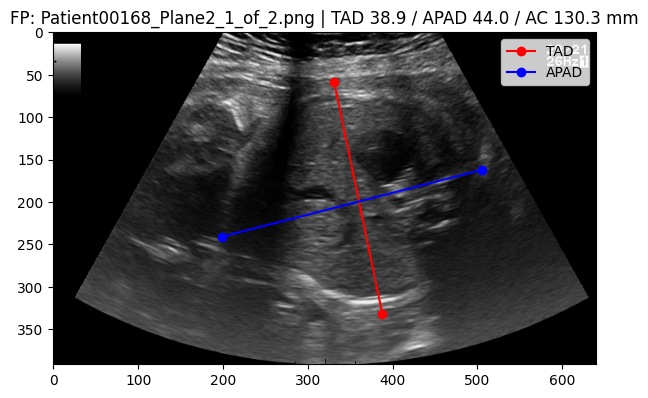


==================== UCL ====================
Rows in CSV: 99
Images found on disk: 99 / 99

TAD (mm)  min/median/max: 5.4 / 53.5 / 119.6
APAD (mm) min/median/max: 5.3 / 55.4 / 129.2
AC (mm)   min/median/max: 16.9 / 169.6 / 391.1

Suspicious rows (need a look before training): 3
  image_name  px_to_mm_rate  tad_mm  apad_mm  ac_mm
125_3AC.jpeg           0.02    5.40     5.34  16.86
125_4AC.jpeg           0.02    5.55     5.30  17.05
125_5AC.jpeg           0.02    7.08     6.64  21.56


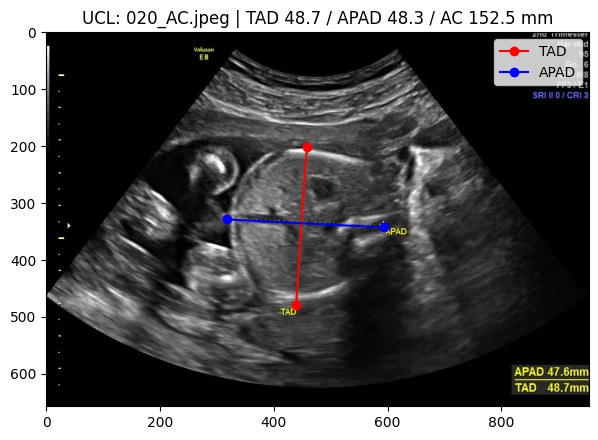

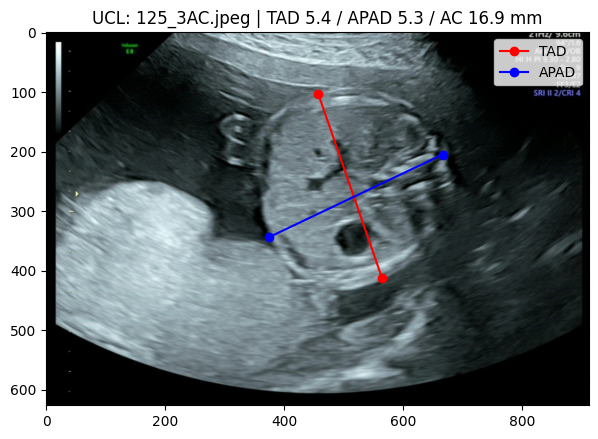

In [ ]:
#Checking images fetus abdomen lying system and image numbers and all checking

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = "/content/drive/MyDrive/fetal-health-project/data/raw/FETAL_BIOMETRY_ABDOMEN"

SOURCES = {
    "FP": {
        "csv": f"{BASE}/FP/annotations/Abdomen.csv",
        "img_dir": f"{BASE}/FP/images/Abdomen",
    },
    "UCL": {
        "csv": f"{BASE}/UCL/annotations/px_to_mm/Abdomen.csv",
        "img_dir": f"{BASE}/UCL/images/Abdomen",
    },
}


def hc_style_circumference(semi_a, semi_b):
    """Same function as the HC18 pipeline: takes SEMI-axes."""
    return np.pi * (3 * (semi_a + semi_b) - np.sqrt((3 * semi_a + semi_b) * (semi_a + 3 * semi_b)))


def ac_from_diameters(tad_mm, apad_mm):
    return hc_style_circumference(tad_mm / 2, apad_mm / 2)   # halve: diameters -> semi-axes


def compute_row_measurements(row):
    tad_px = np.hypot(row["tad_2_x"] - row["tad_1_x"], row["tad_2_y"] - row["tad_1_y"])
    apad_px = np.hypot(row["apad_2_x"] - row["apad_1_x"], row["apad_2_y"] - row["apad_1_y"])
    tad_mm = tad_px * row["px_to_mm_rate"]
    apad_mm = apad_px * row["px_to_mm_rate"]
    return tad_mm, apad_mm, ac_from_diameters(tad_mm, apad_mm)


def summarize(label, series):
    print(f"{label} min/median/max: "
          f"{np.round(series.min(), 1)} / {np.round(series.median(), 1)} / {np.round(series.max(), 1)}")


for name, cfg in SOURCES.items():
    print(f"\n==================== {name} ====================")
    df = pd.read_csv(cfg["csv"])
    print("Rows in CSV:", len(df))

    on_disk = set(os.listdir(cfg["img_dir"]))
    exists = df["image_name"].isin(on_disk)
    print(f"Images found on disk: {exists.sum()} / {len(df)}")

    # --- explain WHY files are missing ---
    if not exists.all():
        loose_dir = os.path.dirname(cfg["img_dir"])           # .../images
        loose_files = set(f for f in os.listdir(loose_dir)
                          if os.path.isfile(os.path.join(loose_dir, f)))
        stems_on_disk = {os.path.splitext(f)[0]: f for f in on_disk}
        print(f"\nMissing rows: {(~exists).sum()}")
        for csv_name in df.loc[~exists, "image_name"]:
            stem = os.path.splitext(csv_name)[0]
            if stem in stems_on_disk:
                reason = f"EXTENSION MISMATCH -> on disk as '{stems_on_disk[stem]}'"
            elif csv_name in loose_files:
                reason = "NOT MOVED -> still loose in images/ (not inside Abdomen/)"
            else:
                reason = "NOT FOUND anywhere -> needs re-upload"
            print(f"  {csv_name:28s} {reason}")

    usable = df[exists].reset_index(drop=True)
    measures = usable.apply(compute_row_measurements, axis=1, result_type="expand")
    measures.columns = ["tad_mm", "apad_mm", "ac_mm"]
    usable = pd.concat([usable, measures], axis=1)

    print()
    summarize("TAD (mm) ", usable["tad_mm"])
    summarize("APAD (mm)", usable["apad_mm"])
    summarize("AC (mm)  ", usable["ac_mm"])

    # --- flag implausible rows (diameter < 15mm or > 130mm, or AC outside 50-420mm) ---
    bad = usable[(usable["tad_mm"] < 15) | (usable["apad_mm"] < 15) |
                 (usable["tad_mm"] > 130) | (usable["apad_mm"] > 130) |
                 (usable["ac_mm"] < 50) | (usable["ac_mm"] > 420)]
    print(f"\nSuspicious rows (need a look before training): {len(bad)}")
    if len(bad):
        print(bad[["image_name", "px_to_mm_rate", "tad_mm", "apad_mm", "ac_mm"]].round(2).to_string(index=False))

    # --- plot the first image, plus the most suspicious one if any ---
    to_plot = [usable.iloc[0]]
    if len(bad):
        to_plot.append(bad.iloc[0])
    for row in to_plot:
        img = cv2.cvtColor(cv2.imread(os.path.join(cfg["img_dir"], row["image_name"])), cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(7, 5))
        plt.imshow(img)
        plt.plot([row["tad_1_x"], row["tad_2_x"]], [row["tad_1_y"], row["tad_2_y"]], "r-o", label="TAD")
        plt.plot([row["apad_1_x"], row["apad_2_x"]], [row["apad_1_y"], row["apad_2_y"]], "b-o", label="APAD")
        plt.legend()
        plt.title(f"{name}: {row['image_name']} | TAD {row['tad_mm']:.1f} / APAD {row['apad_mm']:.1f} / AC {row['ac_mm']:.1f} mm")
        plt.show()

In [ ]:
#checking the px_to_mm_rate

import pandas as pd

ucl_df = pd.read_csv(f"{BASE}/UCL/annotations/px_to_mm/Abdomen.csv")

# Compare subject 125's rate against the overall distribution
print("Overall px_to_mm_rate stats:")
print(ucl_df["px_to_mm_rate"].describe())
print()
print("Subject 125 rows:")
print(ucl_df[ucl_df["image_name"].str.startswith("125_")][["image_name", "px_to_mm_rate"]])

Overall px_to_mm_rate stats:
count    99.000000
mean      0.162233
std       0.061665
min       0.016502
25%       0.122435
50%       0.146580
75%       0.211268
max       0.312500
Name: px_to_mm_rate, dtype: float64

Subject 125 rows:
      image_name  px_to_mm_rate
64  125_3AC.jpeg       0.016502
65  125_4AC.jpeg       0.016502
66  125_5AC.jpeg       0.021231


In [ ]:
ucl_df_clean = ucl_df[~ucl_df["image_name"].str.startswith("125_")].reset_index(drop=True)
print(f"UCL usable rows after dropping subject 125 (implausible AC, cause unconfirmed): {len(ucl_df_clean)}")

UCL usable rows after dropping subject 125 (implausible AC, cause unconfirmed): 96


In [ ]:
# leaving 3 rows for abnormal AC


# 99 images from UCL and 690 images from FP are perfectly verified

In [ ]:
!pip install segmentation-models-pytorch -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 5.5 MB/s eta 0:00:00


In [ ]:
print(ucl_df["SubjectID"].unique()[:10], ucl_df["SubjectID"].isna().sum(), "/", len(ucl_df))
print(fp_df["SubjectID"].nunique())

[nan] 96 / 96
586


In [ ]:
import glob, os

MODEL_DIR = "/content/drive/MyDrive/fetal-health-project/models"
CKPT_DIR = f"{MODEL_DIR}/checkpoints"

for f in glob.glob(f"{MODEL_DIR}/ac_landmark_fold*_eff_b4_384.pt") + glob.glob(f"{CKPT_DIR}/*.pt"):
    os.remove(f)
    print("removed", f)

removed /content/drive/MyDrive/fetal-health-project/models/ac_landmark_fold3_eff_b4_384.pt
removed /content/drive/MyDrive/fetal-health-project/models/ac_landmark_fold4_eff_b4_384.pt
removed /content/drive/MyDrive/fetal-health-project/models/ac_landmark_fold5_eff_b4_384.pt
removed /content/drive/MyDrive/fetal-health-project/models/ac_landmark_fold1_eff_b4_384.pt
removed /content/drive/MyDrive/fetal-health-project/models/ac_landmark_fold2_eff_b4_384.pt


In [ ]:
# AC sub-model: heatmap-regression landmark detection for TAD/APAD (FP + UCL pooled)
# Resumable across Colab sessions — safe to stop and restart without losing progress.

import os
import re
import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from sklearn.model_selection import GroupKFold
from PIL import Image
import time

BASE = "/content/drive/MyDrive/fetal-health-project/data/raw/FETAL_BIOMETRY_ABDOMEN"
MODEL_DIR = "/content/drive/MyDrive/fetal-health-project/models"
CKPT_DIR = f"{MODEL_DIR}/checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
IMG_SIZE = 384
BATCH_SIZE = 8
ENCODER_NAME = "efficientnet-b4"
N_FOLDS = 5
LANDMARK_NAMES = ["tad_1", "tad_2", "apad_1", "apad_2"]

print(f"Using device: {DEVICE}")


# ---------------------------------------------------------------------------
# Step 1: pooled dataframe — subject_id now derived from the IMAGE FILENAME,
# not the SubjectID column (UCL's SubjectID column was unreliable/NaN).
# ---------------------------------------------------------------------------

fp_df = pd.read_csv(f"{BASE}/FP/annotations/Abdomen.csv")
fp_df["image_path"] = fp_df["image_name"].apply(lambda f: f"{BASE}/FP/images/Abdomen/{f}")
fp_df["subject_id"] = "FP_" + fp_df["image_name"].str.extract(r"(Patient\d+)")[0]

ucl_df = pd.read_csv(f"{BASE}/UCL/annotations/px_to_mm/Abdomen.csv")
ucl_df = ucl_df[~ucl_df["image_name"].str.startswith("125_")].reset_index(drop=True)
ucl_df["image_path"] = ucl_df["image_name"].apply(lambda f: f"{BASE}/UCL/images/Abdomen/{f}")
ucl_df["subject_id"] = "UCL_" + ucl_df["image_name"].str.extract(r"^(\d+)_")[0]

# Verify the extraction actually worked before trusting it
assert fp_df["subject_id"].notna().all(), "FP subject_id extraction failed on some rows — check filename pattern."
assert ucl_df["subject_id"].notna().all(), "UCL subject_id extraction failed on some rows — check filename pattern."

KEEP_COLS = ["image_path", "subject_id", "tad_1_x", "tad_1_y", "tad_2_x", "tad_2_y",
             "apad_1_x", "apad_1_y", "apad_2_x", "apad_2_y", "px_to_mm_rate"]
data = pd.concat([fp_df[KEEP_COLS], ucl_df[KEEP_COLS]], ignore_index=True)

assert data["image_path"].apply(os.path.isfile).all(), "Some image paths don't exist — stop and check."
assert data["px_to_mm_rate"].notna().all(), "Some rows have no calibration — stop and check."

fp_patients = fp_df["subject_id"].nunique()
ucl_patients = ucl_df["subject_id"].nunique()
print(f"Pooled dataset: {len(data)} images from {data['subject_id'].nunique()} unique patients "
      f"({fp_patients} FP + {ucl_patients} UCL)")

# Sanity check — stop here if this doesn't look right, don't proceed to training
assert fp_patients > 100, f"FP patient count looks wrong ({fp_patients}) — check the regex."
assert ucl_patients > 10, f"UCL patient count looks wrong ({ucl_patients}) — check the regex."
print("Patient counts look sane — safe to proceed.")

# IMPORTANT: this exact concat order determines which patient lands in which
# fold via GroupKFold. Don't reorder/reload the CSVs differently between
# sessions, or resuming a fold would validate on the wrong patients.


# ---------------------------------------------------------------------------
# Step 2: letterbox + FAST local-patch Gaussian heatmap (same math, less compute)
# ---------------------------------------------------------------------------

def letterbox_transform(image_pil, target_size=IMG_SIZE):
    w, h = image_pil.size
    scale = target_size / max(w, h)
    new_w, new_h = int(w * scale), int(h * scale)
    resized = image_pil.resize((new_w, new_h))
    canvas = Image.new("RGB", (target_size, target_size), (0, 0, 0))
    pad_x, pad_y = (target_size - new_w) // 2, (target_size - new_h) // 2
    canvas.paste(resized, (pad_x, pad_y))
    return canvas, scale, pad_x, pad_y


def make_gaussian_heatmap_fast(x, y, size=IMG_SIZE, sigma=4.0, radius_sigmas=4):
    heatmap = np.zeros((size, size), dtype=np.float32)
    r = int(np.ceil(radius_sigmas * sigma))
    x0, x1 = max(0, int(x) - r), min(size, int(x) + r + 1)
    y0, y1 = max(0, int(y) - r), min(size, int(y) + r + 1)
    if x0 >= x1 or y0 >= y1:
        return heatmap
    xs = np.arange(x0, x1)
    ys = np.arange(y0, y1)[:, None]
    patch = np.exp(-((xs - x) ** 2 + (ys - y) ** 2) / (2 * sigma ** 2))
    heatmap[y0:y1, x0:x1] = patch.astype(np.float32)
    return heatmap


class AbdomenLandmarkDataset(Dataset):
    def __init__(self, df, augment=False):
        self.df = df.reset_index(drop=True)
        self.augment = augment
        self.normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image_pil = Image.open(row["image_path"]).convert("RGB")
        letterboxed, scale, pad_x, pad_y = letterbox_transform(image_pil)

        flip = self.augment and np.random.rand() > 0.5
        if flip:
            letterboxed = letterboxed.transpose(Image.FLIP_LEFT_RIGHT)

        img_tensor = self.normalize(transforms.ToTensor()(letterboxed))

        heatmaps = np.zeros((4, IMG_SIZE, IMG_SIZE), dtype=np.float32)
        for ch, name in enumerate(LANDMARK_NAMES):
            x_native, y_native = row[f"{name}_x"], row[f"{name}_y"]
            x_lb = x_native * scale + pad_x
            y_lb = y_native * scale + pad_y
            if flip:
                x_lb = IMG_SIZE - 1 - x_lb
            heatmaps[ch] = make_gaussian_heatmap_fast(x_lb, y_lb)

        return img_tensor, torch.from_numpy(heatmaps), row["px_to_mm_rate"], scale, pad_x, pad_y, idx


def build_landmark_model():
    return smp.Unet(encoder_name=ENCODER_NAME, encoder_weights="imagenet", in_channels=3, classes=4)


# ---------------------------------------------------------------------------
# Step 3: RESUMABLE training — checkpoints after EVERY epoch to Drive
# ---------------------------------------------------------------------------

def train_one_fold(train_loader, val_loader, fold_num, max_epochs=100, lr=1e-4, patience=8):
    ckpt_path = f"{CKPT_DIR}/ac_fold{fold_num}_ckpt.pt"
    model = build_landmark_model().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=4)
    loss_fn = nn.MSELoss()
    scaler = torch.amp.GradScaler('cuda', enabled=(DEVICE == "cuda"))

    start_epoch = 0
    best_val_loss = float("inf")
    epochs_no_improve = 0
    best_state = None

    if os.path.isfile(ckpt_path):
        print(f"  Resuming fold {fold_num} from checkpoint...")
        ckpt = torch.load(ckpt_path, map_location=DEVICE)
        model.load_state_dict(ckpt["model_state"])
        optimizer.load_state_dict(ckpt["optimizer_state"])
        scheduler.load_state_dict(ckpt["scheduler_state"])
        scaler.load_state_dict(ckpt["scaler_state"])
        start_epoch = ckpt["epoch"] + 1
        best_val_loss = ckpt["best_val_loss"]
        epochs_no_improve = ckpt["epochs_no_improve"]
        best_state = ckpt["best_state"]
        print(f"  Resumed at epoch {start_epoch}, best_val_loss so far = {best_val_loss:.6f}")

    for epoch in range(start_epoch, max_epochs):
        epoch_start = time.time()
        model.train()
        train_loss_sum = 0.0
        for images, heatmaps, *_ in train_loader:
            images, heatmaps = images.to(DEVICE), heatmaps.to(DEVICE)
            optimizer.zero_grad()
            with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
                preds = torch.sigmoid(model(images))
                loss = loss_fn(preds, heatmaps)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            train_loss_sum += loss.item()
        train_loss_avg = train_loss_sum / len(train_loader)

        model.eval()
        val_loss = 0
        with torch.no_grad():
            for images, heatmaps, *_ in val_loader:
                images, heatmaps = images.to(DEVICE), heatmaps.to(DEVICE)
                with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
                    preds = torch.sigmoid(model(images))
                    val_loss += loss_fn(preds, heatmaps).item()
        val_loss /= len(val_loader)
        scheduler.step(val_loss)

        epoch_time = time.time() - epoch_start
        print(f"  Fold {fold_num} | Epoch {epoch+1:3d}/{max_epochs} | "
              f"train_loss={train_loss_avg:.6f} val_loss={val_loss:.6f} | "
              f"{epoch_time:.1f}s | no_improve={epochs_no_improve}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = model.state_dict()
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        torch.save({
            "epoch": epoch,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "scheduler_state": scheduler.state_dict(),
            "scaler_state": scaler.state_dict(),
            "best_val_loss": best_val_loss,
            "epochs_no_improve": epochs_no_improve,
            "best_state": best_state,
        }, ckpt_path)

        if epochs_no_improve >= patience:
            print(f"  Early stopping fold {fold_num} at epoch {epoch+1}")
            break

    print(f"Fold {fold_num}: best val_loss = {best_val_loss:.6f}")
    model.load_state_dict(best_state)
    return model


def soft_argmax_2d(heatmap):
    h, w = heatmap.shape
    heatmap = np.clip(heatmap, 0, None)
    total = heatmap.sum()
    if total < 1e-6:
        y, x = np.unravel_index(np.argmax(heatmap), heatmap.shape)
        return float(x), float(y)
    ys, xs = np.mgrid[0:h, 0:w]
    x = (xs * heatmap).sum() / total
    y = (ys * heatmap).sum() / total
    return float(x), float(y)


def predict_landmarks_with_tta(model, image_pil):
    letterboxed, scale, pad_x, pad_y = letterbox_transform(image_pil)
    normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    img_tensor = normalize(transforms.ToTensor()(letterboxed)).unsqueeze(0).to(DEVICE)
    flipped_tensor = torch.flip(img_tensor, dims=[3])

    model.eval()
    with torch.no_grad():
        with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
            heat_orig = torch.sigmoid(model(img_tensor)).float().cpu().numpy()[0]
            heat_flip = torch.sigmoid(model(flipped_tensor)).float().cpu().numpy()[0]
    heat_flip_back = np.flip(heat_flip, axis=2)
    heat_avg = (heat_orig + heat_flip_back) / 2.0

    landmarks_lb = {}
    for ch, name in enumerate(LANDMARK_NAMES):
        x_lb, y_lb = soft_argmax_2d(heat_avg[ch])
        x_native = (x_lb - pad_x) / scale
        y_native = (y_lb - pad_y) / scale
        landmarks_lb[name] = (x_native, y_native)
    return landmarks_lb


def ac_from_diameters(tad_mm, apad_mm):
    return np.pi * (3 * (tad_mm + apad_mm) / 2
                     - np.sqrt((3 * tad_mm + apad_mm) * (tad_mm + 3 * apad_mm)))


def evaluate_true_oof(fold_models, fold_val_indices, df):
    tad_errors, apad_errors, ac_errors = [], [], []
    for fold_idx, val_idx in enumerate(fold_val_indices):
        model = fold_models[fold_idx]
        for idx in val_idx:
            row = df.iloc[idx]
            image_pil = Image.open(row["image_path"]).convert("RGB")
            pred = predict_landmarks_with_tta(model, image_pil)

            pred_tad_px = np.hypot(pred["tad_2"][0]-pred["tad_1"][0], pred["tad_2"][1]-pred["tad_1"][1])
            pred_apad_px = np.hypot(pred["apad_2"][0]-pred["apad_1"][0], pred["apad_2"][1]-pred["apad_1"][1])
            pred_tad_mm = pred_tad_px * row["px_to_mm_rate"]
            pred_apad_mm = pred_apad_px * row["px_to_mm_rate"]
            pred_ac_mm = ac_from_diameters(pred_tad_mm, pred_apad_mm)

            true_tad_px = np.hypot(row["tad_2_x"]-row["tad_1_x"], row["tad_2_y"]-row["tad_1_y"])
            true_apad_px = np.hypot(row["apad_2_x"]-row["apad_1_x"], row["apad_2_y"]-row["apad_1_y"])
            true_tad_mm = true_tad_px * row["px_to_mm_rate"]
            true_apad_mm = true_apad_px * row["px_to_mm_rate"]
            true_ac_mm = ac_from_diameters(true_tad_mm, true_apad_mm)

            tad_errors.append(abs(pred_tad_mm - true_tad_mm))
            apad_errors.append(abs(pred_apad_mm - true_apad_mm))
            ac_errors.append(abs(pred_ac_mm - true_ac_mm))
    return tad_errors, apad_errors, ac_errors


# ---------------------------------------------------------------------------
# Step 4: fold loop — SKIPS folds already finished in a previous session
# ---------------------------------------------------------------------------

gkf = GroupKFold(n_splits=N_FOLDS)
all_indices = np.arange(len(data))
groups = data["subject_id"].values

fold_models = []
fold_val_indices = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(all_indices, groups=groups)):
    fold_num = fold + 1
    final_model_path = f"{MODEL_DIR}/ac_landmark_fold{fold_num}_eff_b4_384.pt"
    fold_val_indices.append(val_idx)

    print(f"\n===== Fold {fold_num}/{N_FOLDS} =====")
    print(f"  train patients: {data.iloc[train_idx]['subject_id'].nunique()}, "
          f"val patients: {data.iloc[val_idx]['subject_id'].nunique()}")

    if os.path.isfile(final_model_path):
        print(f"  Fold {fold_num} already completed in a previous session — loading saved model, skipping training.")
        model = build_landmark_model().to(DEVICE)
        model.load_state_dict(torch.load(final_model_path, map_location=DEVICE))
        model.eval()
        fold_models.append(model)
        continue

    train_subset = Subset(AbdomenLandmarkDataset(data, augment=True), train_idx)
    val_subset = Subset(AbdomenLandmarkDataset(data, augment=False), val_idx)
    train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

    model = train_one_fold(train_loader, val_loader, fold_num)
    fold_models.append(model)
    torch.save(model.state_dict(), final_model_path)

    del train_loader, val_loader, train_subset, val_subset
    gc.collect()
    torch.cuda.empty_cache()

print("\n===== TRUE out-of-fold evaluation (patient-disjoint, TTA, native resolution) =====")
tad_errs, apad_errs, ac_errs = evaluate_true_oof(fold_models, fold_val_indices, data)
print(f"TAD  -> MAE: {np.mean(tad_errs):.2f}mm, RMSE: {np.sqrt(np.mean(np.array(tad_errs)**2)):.2f}mm")
print(f"APAD -> MAE: {np.mean(apad_errs):.2f}mm, RMSE: {np.sqrt(np.mean(np.array(apad_errs)**2)):.2f}mm")
print(f"AC   -> MAE: {np.mean(ac_errs):.2f}mm, RMSE: {np.sqrt(np.mean(np.array(ac_errs)**2)):.2f}mm")

Using device: cuda
Pooled dataset: 789 images from 615 unique patients (586 FP + 29 UCL)
Patient counts look sane — safe to proceed.

===== Fold 1/5 =====
  train patients: 493, val patients: 122
  Fold 1 already completed in a previous session — loading saved model, skipping training.


config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 77.9MB            

model.safetensors: downloading bytes:           |  0.00B            


===== Fold 2/5 =====
  train patients: 492, val patients: 123
  Resuming fold 2 from checkpoint...
  Resumed at epoch 76, best_val_loss so far = 0.000359
  Fold 2 | Epoch  77/100 | train_loss=0.000357 val_loss=0.000357 | 312.8s | no_improve=0
  Fold 2 | Epoch  78/100 | train_loss=0.000354 val_loss=0.000357 | 34.6s | no_improve=0
  Fold 2 | Epoch  79/100 | train_loss=0.000350 val_loss=0.000353 | 35.8s | no_improve=0
  Fold 2 | Epoch  80/100 | train_loss=0.000349 val_loss=0.000351 | 34.6s | no_improve=0
  Fold 2 | Epoch  81/100 | train_loss=0.000345 val_loss=0.000351 | 36.2s | no_improve=0
  Fold 2 | Epoch  82/100 | train_loss=0.000342 val_loss=0.000348 | 34.7s | no_improve=0
  Fold 2 | Epoch  83/100 | train_loss=0.000339 val_loss=0.000347 | 36.5s | no_improve=0
  Fold 2 | Epoch  84/100 | train_loss=0.000334 val_loss=0.000346 | 34.7s | no_improve=0
  Fold 2 | Epoch  85/100 | train_loss=0.000331 val_loss=0.000345 | 36.5s | no_improve=0
  Fold 2 | Epoch  86/100 | train_loss=0.000326 val_l

In [ ]:
!pip install segmentation-models-pytorch -q

In [ ]:
# AC sub-model v2 - DSNT-style landmark regression for TAD/APAD (FP + UCL pooled)
# v1 (sigmoid heatmaps + MSE) collapsed to "predict zeros". v2 decodes coordinates with a
# spatial softmax and trains on the coordinates directly, so that collapse is impossible.

import os, gc, shutil, time
import numpy as np
import pandas as pd
import cv2
import torch
import segmentation_models_pytorch as smp
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.model_selection import GroupKFold
from PIL import Image

SMOKE_TEST = True   # True = few-minute sanity run on a tiny subset. Set False for the real run.

BASE = "/content/drive/MyDrive/fetal-health-project/data/raw/FETAL_BIOMETRY_ABDOMEN"
MODEL_DIR = "/content/drive/MyDrive/fetal-health-project/models"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"
IMG_SIZE = 384
BATCH_SIZE = 8
ENCODER_NAME = "efficientnet-b4"
N_FOLDS = 5
SIGMA = 4.0          # width of the Gaussian the JS regulariser pulls each heatmap toward
JS_WEIGHT = 1.0
LR = 1e-4
MAX_EPOCHS = 5 if SMOKE_TEST else 100
PATIENCE = 10
RUN_TAG = "smoke" if SMOKE_TEST else "full"
CKPT_DIR = f"{MODEL_DIR}/ac_dsnt_{RUN_TAG}"

if SMOKE_TEST and os.path.isdir(CKPT_DIR):
    shutil.rmtree(CKPT_DIR)          # smoke runs always start fresh
os.makedirs(CKPT_DIR, exist_ok=True)
torch.backends.cudnn.benchmark = True
print(f"Using device: {DEVICE} | SMOKE_TEST={SMOKE_TEST} | checkpoints -> {CKPT_DIR}")

# ==== NUMPY HELPERS BEGIN ====
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)
LANDMARK_NAMES = ["tad_1", "tad_2", "apad_1", "apad_2"]
# Allowed re-labelings of the 4 points: swap endpoints inside a pair, and/or swap the two pairs.
PERMS_NP = np.array([[0, 1, 2, 3], [1, 0, 2, 3], [0, 1, 3, 2], [1, 0, 3, 2],
                     [2, 3, 0, 1], [3, 2, 0, 1], [2, 3, 1, 0], [3, 2, 1, 0]])


def letterbox_transform(image_pil, target_size=IMG_SIZE):
    w, h = image_pil.size
    scale = target_size / max(w, h)
    new_w, new_h = int(w * scale), int(h * scale)
    resized = image_pil.resize((new_w, new_h))
    canvas = Image.new("RGB", (target_size, target_size), (0, 0, 0))
    pad_x, pad_y = (target_size - new_w) // 2, (target_size - new_h) // 2
    canvas.paste(resized, (pad_x, pad_y))
    return canvas, scale, pad_x, pad_y


def match_points_np(ref, other):
    """Re-order `other` (4,2) with the allowed permutation that best matches `ref` (4,2)."""
    costs = [np.linalg.norm(ref - other[p], axis=1).sum() for p in PERMS_NP]
    return other[PERMS_NP[int(np.argmin(costs))]]


def augment_sample(arr, pts, rng=None):
    """arr: HxWx3 uint8 (letterboxed). pts: (4,2) pixel coords in the same frame.
    Returns float32 image in [0,1] and the transformed points."""
    rng = rng if rng is not None else np.random.default_rng()
    pts = np.asarray(pts, dtype=np.float32).copy()
    if rng.random() < 0.5:                                   # horizontal flip
        arr = arr[:, ::-1]
        pts[:, 0] = (IMG_SIZE - 1) - pts[:, 0]
    arr = np.ascontiguousarray(arr)
    if rng.random() < 0.7:                                   # rotation / scale / shift
        c = (IMG_SIZE - 1) / 2.0
        for _ in range(5):
            M = cv2.getRotationMatrix2D((c, c), rng.uniform(-20, 20), rng.uniform(0.9, 1.1))
            M[:, 2] += rng.uniform(-0.04, 0.04, 2) * IMG_SIZE
            new = pts @ M[:, :2].T + M[:, 2]
            if (new >= 2).all() and (new <= IMG_SIZE - 3).all():   # keep every landmark inside
                arr = cv2.warpAffine(arr, M, (IMG_SIZE, IMG_SIZE), flags=cv2.INTER_LINEAR,
                                     borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))
                pts = new.astype(np.float32)
                break
    img = arr.astype(np.float32) / 255.0
    if rng.random() < 0.8:                                   # gamma / contrast / brightness
        img = np.clip(img, 0, 1) ** rng.uniform(0.8, 1.25)
        img = np.clip(img * rng.uniform(0.85, 1.15) + rng.uniform(-0.08, 0.08), 0, 1)
    return img, pts


def normalize_chw(img01):
    return np.ascontiguousarray(((img01 - MEAN) / STD).transpose(2, 0, 1), dtype=np.float32)


def ac_from_diameters(d1_mm, d2_mm):
    a, b = d1_mm / 2.0, d2_mm / 2.0      # diameters -> semi-axes (same function as HC18)
    return np.pi * (3 * (a + b) - np.sqrt((3 * a + b) * (a + 3 * b)))


def diameters_mm(pts, rate):
    return (np.linalg.norm(pts[0] - pts[1]) * rate, np.linalg.norm(pts[2] - pts[3]) * rate)
# ==== NUMPY HELPERS END ====


# ---------------------------------------------------------------------------
# Step 1: pooled dataframe (patient ids come from the FILENAME, not the SubjectID column)
# ---------------------------------------------------------------------------
fp_df = pd.read_csv(f"{BASE}/FP/annotations/Abdomen.csv")
fp_df["image_path"] = fp_df["image_name"].apply(lambda f: f"{BASE}/FP/images/Abdomen/{f}")
fp_df["subject_id"] = "FP_" + fp_df["image_name"].str.extract(r"(Patient\d+)")[0]

ucl_df = pd.read_csv(f"{BASE}/UCL/annotations/px_to_mm/Abdomen.csv")
ucl_df = ucl_df[~ucl_df["image_name"].str.startswith("125_")].reset_index(drop=True)
ucl_df["image_path"] = ucl_df["image_name"].apply(lambda f: f"{BASE}/UCL/images/Abdomen/{f}")
ucl_df["subject_id"] = "UCL_" + ucl_df["image_name"].str.extract(r"^(\d+)_")[0]

assert fp_df["subject_id"].notna().all() and ucl_df["subject_id"].notna().all(), "subject_id extraction failed"
KEEP_COLS = ["image_path", "subject_id"] + [f"{n}_{c}" for n in LANDMARK_NAMES for c in "xy"] + ["px_to_mm_rate"]
data = pd.concat([fp_df[KEEP_COLS], ucl_df[KEEP_COLS]], ignore_index=True)
assert data["image_path"].apply(os.path.isfile).all(), "Some image paths don't exist."
assert data["px_to_mm_rate"].notna().all(), "Some rows have no calibration."
print(f"Full pooled dataset: {len(data)} images, {data['subject_id'].nunique()} patients")

if SMOKE_TEST:   # tiny subset, NOT used for the real run
    fp_part = data[data["subject_id"].str.startswith("FP_")].sample(120, random_state=0)
    ucl_part = data[data["subject_id"].str.startswith("UCL_")].sample(40, random_state=0)
    data = pd.concat([fp_part, ucl_part]).reset_index(drop=True)
    print(f"SMOKE subset: {len(data)} images")

# NOTE: row order of `data` decides which patient lands in which fold. Don't change it between sessions.
CONFIG = dict(img_size=IMG_SIZE, encoder=ENCODER_NAME, sigma=SIGMA, js_weight=JS_WEIGHT,
              n_images=len(data), n_folds=N_FOLDS, smoke=SMOKE_TEST)


class AbdomenLandmarkDataset(Dataset):
    def __init__(self, df, augment=False):
        self.df = df.reset_index(drop=True)
        self.augment = augment

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        lb, scale, pad_x, pad_y = letterbox_transform(Image.open(row["image_path"]).convert("RGB"))
        arr = np.asarray(lb)
        pts = np.array([[row[f"{n}_x"] * scale + pad_x, row[f"{n}_y"] * scale + pad_y]
                        for n in LANDMARK_NAMES], dtype=np.float32)
        if self.augment:
            img01, pts = augment_sample(arr, pts)
        else:
            img01 = arr.astype(np.float32) / 255.0
        return torch.from_numpy(normalize_chw(img01)), torch.from_numpy(pts)


# ---------------------------------------------------------------------------
# Step 2: model + DSNT-style decoding and losses (all float32)
# ---------------------------------------------------------------------------
def build_landmark_model():
    return smp.Unet(encoder_name=ENCODER_NAME, encoder_weights="imagenet", in_channels=3, classes=4)


PERMS_T = torch.from_numpy(PERMS_NP).long().to(DEVICE)
XG = torch.arange(IMG_SIZE, dtype=torch.float32, device=DEVICE).repeat(IMG_SIZE)               # x of flat index
YG = torch.arange(IMG_SIZE, dtype=torch.float32, device=DEVICE).repeat_interleave(IMG_SIZE)    # y of flat index


def decode_heatmaps(logits):
    """logits (B,4,H,W) -> spatial-softmax probabilities (B,4,HW) and expected (x,y) in pixels (B,4,2)."""
    B, K, H, W = logits.shape
    p = torch.softmax(logits.float().reshape(B, K, H * W), dim=-1)
    coords = torch.stack([(p * XG).sum(-1), (p * YG).sum(-1)], dim=-1)
    return coords, p


def match_gt(pred, gt):
    """For each sample pick the allowed re-labeling of gt (B,4,2) that best matches pred (B,4,2)."""
    gt_perm = gt[:, PERMS_T]                                              # (B,8,4,2)
    d = torch.sqrt(((pred[:, None] - gt_perm) ** 2).sum(-1) + 1e-8)       # (B,8,4)
    best = d.sum(-1).argmin(dim=1)
    return gt_perm[torch.arange(pred.shape[0], device=pred.device), best]  # (B,4,2)


def gaussian_targets(gt):
    gx, gy = gt[..., 0:1], gt[..., 1:2]                                   # (B,4,1)
    q = torch.exp(-((XG - gx) ** 2 + (YG - gy) ** 2) / (2 * SIGMA ** 2))  # (B,4,HW)
    return q / q.sum(-1, keepdim=True).clamp_min(1e-12)


def js_div(p, q, eps=1e-12):
    m = 0.5 * (p + q)
    kl_pm = (p * (torch.log(p + eps) - torch.log(m + eps))).sum(-1)
    kl_qm = (q * (torch.log(q + eps) - torch.log(m + eps))).sum(-1)
    return 0.5 * (kl_pm + kl_qm)


def compute_losses(logits, gt):
    coords, p = decode_heatmaps(logits)
    matched = match_gt(coords.detach(), gt)
    dist = torch.sqrt(((coords - matched) ** 2).sum(-1) + 1e-8)           # (B,4) pixels
    coord_loss = (dist / ((IMG_SIZE - 1) / 2.0)).mean()
    js = js_div(p, gaussian_targets(matched)).mean()
    return coord_loss + JS_WEIGHT * js, dist.detach().mean().item()


def run_validation(model, loader):
    model.eval()
    tot_loss = tot_px = base_px = n = 0.0
    center = (IMG_SIZE - 1) / 2.0
    with torch.no_grad():
        for images, gts in loader:
            images, gts = images.to(DEVICE, non_blocking=True), gts.to(DEVICE)
            with torch.amp.autocast('cuda', enabled=USE_AMP):
                logits = model(images)
            loss, px = compute_losses(logits, gts)
            b = images.shape[0]
            tot_loss += loss.item() * b
            tot_px += px * b
            base_px += (gts - center).norm(dim=-1).mean().item() * b   # "all points at the centre" baseline
            n += b
    return tot_loss / n, tot_px / n, base_px / n


def atomic_save(obj, path):
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)     # a Colab cutoff mid-write can no longer corrupt the checkpoint


def train_one_fold(train_loader, val_loader, fold_num):
    last_p = f"{CKPT_DIR}/fold{fold_num}_last.pt"
    best_p = f"{CKPT_DIR}/fold{fold_num}_best.pt"
    model = build_landmark_model().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=4)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    start_epoch, best_px, no_improve = 0, float("inf"), 0

    if os.path.isfile(last_p):
        ck = torch.load(last_p, map_location=DEVICE)
        if ck["config"] != CONFIG:
            raise RuntimeError(f"Checkpoint was made with a different config. Delete the files in {CKPT_DIR}.")
        model.load_state_dict(ck["model_state"]); optimizer.load_state_dict(ck["optimizer_state"])
        scheduler.load_state_dict(ck["scheduler_state"]); scaler.load_state_dict(ck["scaler_state"])
        start_epoch, best_px, no_improve = ck["epoch"] + 1, ck["best_px"], ck["no_improve"]
        print(f"  Resumed fold {fold_num} at epoch {start_epoch} (best val landmark error {best_px:.2f}px)")

    for epoch in range(start_epoch, MAX_EPOCHS):
        if no_improve >= PATIENCE:
            break
        t0 = time.time()
        model.train()
        loss_sum = px_sum = n = 0.0
        for images, gts in train_loader:
            images, gts = images.to(DEVICE, non_blocking=True), gts.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda', enabled=USE_AMP):
                logits = model(images)
            loss, px = compute_losses(logits, gts)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            b = images.shape[0]
            loss_sum += loss.item() * b; px_sum += px * b; n += b
        val_loss, val_px, base_px = run_validation(model, val_loader)
        scheduler.step(val_px)
        print(f"  Fold {fold_num} | Ep {epoch+1:3d}/{MAX_EPOCHS} | train_loss={loss_sum/n:.4f} train_px={px_sum/n:6.2f} | "
              f"val_loss={val_loss:.4f} val_px={val_px:6.2f} (centre-baseline {base_px:.1f}) | {time.time()-t0:.0f}s | no_improve={no_improve}")
        if val_px < best_px - 1e-3:
            best_px, no_improve = val_px, 0
            atomic_save({"model_state": model.state_dict(), "val_px": val_px, "epoch": epoch}, best_p)
        else:
            no_improve += 1
        atomic_save({"model_state": model.state_dict(), "optimizer_state": optimizer.state_dict(),
                     "scheduler_state": scheduler.state_dict(), "scaler_state": scaler.state_dict(),
                     "epoch": epoch, "best_px": best_px, "no_improve": no_improve, "config": CONFIG}, last_p)

    model.load_state_dict(torch.load(best_p, map_location=DEVICE)["model_state"])
    return model, best_px


# ---------------------------------------------------------------------------
# Step 3: evaluation - flip-TTA with label matching, native resolution, metrics in mm
# ---------------------------------------------------------------------------
def predict_points_tta(model, image_pil):
    lb, scale, pad_x, pad_y = letterbox_transform(image_pil)
    x = torch.from_numpy(normalize_chw(np.asarray(lb).astype(np.float32) / 255.0)).unsqueeze(0).to(DEVICE)
    batch = torch.cat([x, torch.flip(x, dims=[3])], dim=0)
    model.eval()
    with torch.no_grad():
        with torch.amp.autocast('cuda', enabled=USE_AMP):
            logits = model(batch)
        coords, _ = decode_heatmaps(logits)
    c = coords.cpu().numpy()
    c_orig, c_flip = c[0], c[1].copy()
    c_flip[:, 0] = (IMG_SIZE - 1) - c_flip[:, 0]            # undo the flip
    c_flip = match_points_np(c_orig, c_flip)                # channels may be labelled differently -> match first
    c_avg = 0.5 * (c_orig + c_flip)
    return (c_avg - np.array([pad_x, pad_y], dtype=np.float32)) / scale   # native pixel coordinates


def evaluate_oof(fold_models, fold_val_indices, df):
    rows = []
    for model, val_idx in zip(fold_models, fold_val_indices):
        for idx in val_idx:
            row = df.iloc[idx]
            pred = predict_points_tta(model, Image.open(row["image_path"]).convert("RGB"))
            gt = np.array([[row[f"{n}_x"], row[f"{n}_y"]] for n in LANDMARK_NAMES], dtype=np.float32)
            rate = row["px_to_mm_rate"]
            pd1, pd2 = diameters_mm(pred, rate)
            gd1, gd2 = diameters_mm(gt, rate)
            p_sorted, g_sorted = np.sort([pd1, pd2]), np.sort([gd1, gd2])
            rows.append(dict(source=row["subject_id"].split("_")[0],
                             ac_true=ac_from_diameters(gd1, gd2), ac_pred=ac_from_diameters(pd1, pd2),
                             major_err=abs(p_sorted[1] - g_sorted[1]), minor_err=abs(p_sorted[0] - g_sorted[0]),
                             lm_err_mm=np.linalg.norm(gt - match_points_np(gt, pred), axis=1).mean() * rate))
    res = pd.DataFrame(rows)
    err = (res["ac_pred"] - res["ac_true"]).abs()
    base = (res["ac_true"] - res["ac_true"].mean()).abs().mean()
    print(f"n = {len(res)} images")
    print(f"AC  -> MAE {err.mean():.2f} mm | RMSE {np.sqrt((err**2).mean()):.2f} mm | mean abs % error {(err/res['ac_true']*100).mean():.2f}%")
    print(f"       (reference: always predicting the mean AC gives MAE {base:.2f} mm)")
    print(f"Larger diameter MAE {res['major_err'].mean():.2f} mm | smaller diameter MAE {res['minor_err'].mean():.2f} mm")
    print(f"Mean landmark error {res['lm_err_mm'].mean():.2f} mm")
    for src in sorted(res["source"].unique()):
        m = res["source"] == src
        print(f"  {src}: n={m.sum()}, AC MAE {err[m].mean():.2f} mm")
    return res


# ---------------------------------------------------------------------------
# Step 4: fold loop (resumable; skips folds that finished in an earlier session)
# ---------------------------------------------------------------------------
gkf = GroupKFold(n_splits=N_FOLDS)
folds_to_run = [0] if SMOKE_TEST else list(range(N_FOLDS))
fold_models, fold_val_indices = [], []

for fold, (train_idx, val_idx) in enumerate(gkf.split(np.arange(len(data)), groups=data["subject_id"].values)):
    if fold not in folds_to_run:
        continue
    fold_num = fold + 1
    final_p = f"{CKPT_DIR}/fold{fold_num}_final.pt"
    print(f"\n===== Fold {fold_num}/{N_FOLDS} | train patients {data.iloc[train_idx]['subject_id'].nunique()}, "
          f"val patients {data.iloc[val_idx]['subject_id'].nunique()} =====")
    fold_val_indices.append(val_idx)

    if os.path.isfile(final_p):
        ck = torch.load(final_p, map_location=DEVICE)
        if ck.get("config") != CONFIG or not ck.get("completed"):
            raise RuntimeError(f"{final_p} does not match this run. Delete the files in {CKPT_DIR}.")
        print(f"  Already completed (best val landmark error {ck['best_px']:.2f}px) - loading.")
        model = build_landmark_model().to(DEVICE)
        model.load_state_dict(ck["model_state"])
        fold_models.append(model)
        continue

    train_loader = DataLoader(Subset(AbdomenLandmarkDataset(data, augment=True), train_idx), batch_size=BATCH_SIZE,
                              shuffle=True, num_workers=2, pin_memory=True, drop_last=True)
    val_loader = DataLoader(Subset(AbdomenLandmarkDataset(data, augment=False), val_idx), batch_size=BATCH_SIZE,
                            shuffle=False, num_workers=2, pin_memory=True)
    model, best_px = train_one_fold(train_loader, val_loader, fold_num)
    atomic_save({"model_state": model.state_dict(), "best_px": best_px, "completed": True, "config": CONFIG}, final_p)
    fold_models.append(model)
    del train_loader, val_loader
    gc.collect(); torch.cuda.empty_cache()

print("\n===== Out-of-fold evaluation (patient-disjoint, flip-TTA, native resolution, mm) =====")
oof_results = evaluate_oof(fold_models, fold_val_indices, data)

Using device: cpu | SMOKE_TEST=True | checkpoints -> /content/drive/MyDrive/fetal-health-project/models/ac_dsnt_smoke
Full pooled dataset: 789 images, 615 patients
SMOKE subset: 160 images

===== Fold 1/5 | train patients 114, val patients 25 =====


config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 77.9MB            

model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


  Fold 1 | Ep   1/5 | train_loss=1.2031 train_px= 99.77 | val_loss=1.1528 val_px= 90.61 (centre-baseline 92.1) | 430s | no_improve=0


##Model result failed as GPU LIMIT  . However file are now oragnize via 4060ti gpu.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
d = "/content/drive/MyDrive/fetal-health-project/models/ac_dsnt_full"
print(sorted(os.listdir(d)) if os.path.isdir(d) else "folder not found - models not uploaded yet")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['fold1_final.pt', 'fold2_final.pt', 'fold3_best.pt', 'fold3_final.pt', 'fold3_last.pt', 'fold4_best.pt', 'fold4_final.pt', 'fold4_last.pt', 'fold5_best.pt', 'fold5_final.pt', 'fold5_last.pt', 'oof_results.csv']


##Checking some defect image in Abdomen dataset


In [ ]:
!pip install -q segmentation-models-pytorch==0.5.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 1.2 MB/s eta 0:00:00


device=cuda | torch 2.11.0+cu130 | smp 0.5.0 | out=/content/drive/MyDrive/fetal-health-project/models/ac_dsnt_full/diagnostics

Loading data ...
  FP csv columns: ['image_name', 'scale', 'center_w', 'center_h', 'tad_1_x', 'tad_1_y', 'tad_2_x', 'tad_2_y', 'apad_1_x', 'apad_1_y', 'apad_2_x', 'apad_2_y', 'px_to_mm_rate', 'mm_dist', 'Algo', 'SubjectID', 'Split']
  UCL csv columns: ['image_name', 'scale', 'center_w', 'center_h', 'tad_1_x', 'tad_1_y', 'tad_2_x', 'tad_2_y', 'apad_1_x', 'apad_1_y', 'apad_2_x', 'apad_2_y', 'px_to_mm_rate', 'mm_dist', 'Algo', 'SubjectID', 'Split']
  789 images, 615 patients ({'FP': 586, 'UCL': 29})

Loading models ...
  fold 1: size=384 completed/best_px=(True, 13.424207464049134)
  config keys: {'img_size': 384, 'encoder': 'efficientnet-b4', 'sigma': 4.0, 'js_weight': 1.0, 'n_images': 789, 'n_folds': 5, 'smoke': False}
  fold 2: size=384 completed/best_px=(True, 13.33884428724458)
  fold 3: size=384 completed/best_px=(True, 14.13040080251573)
  fold 4: size=384

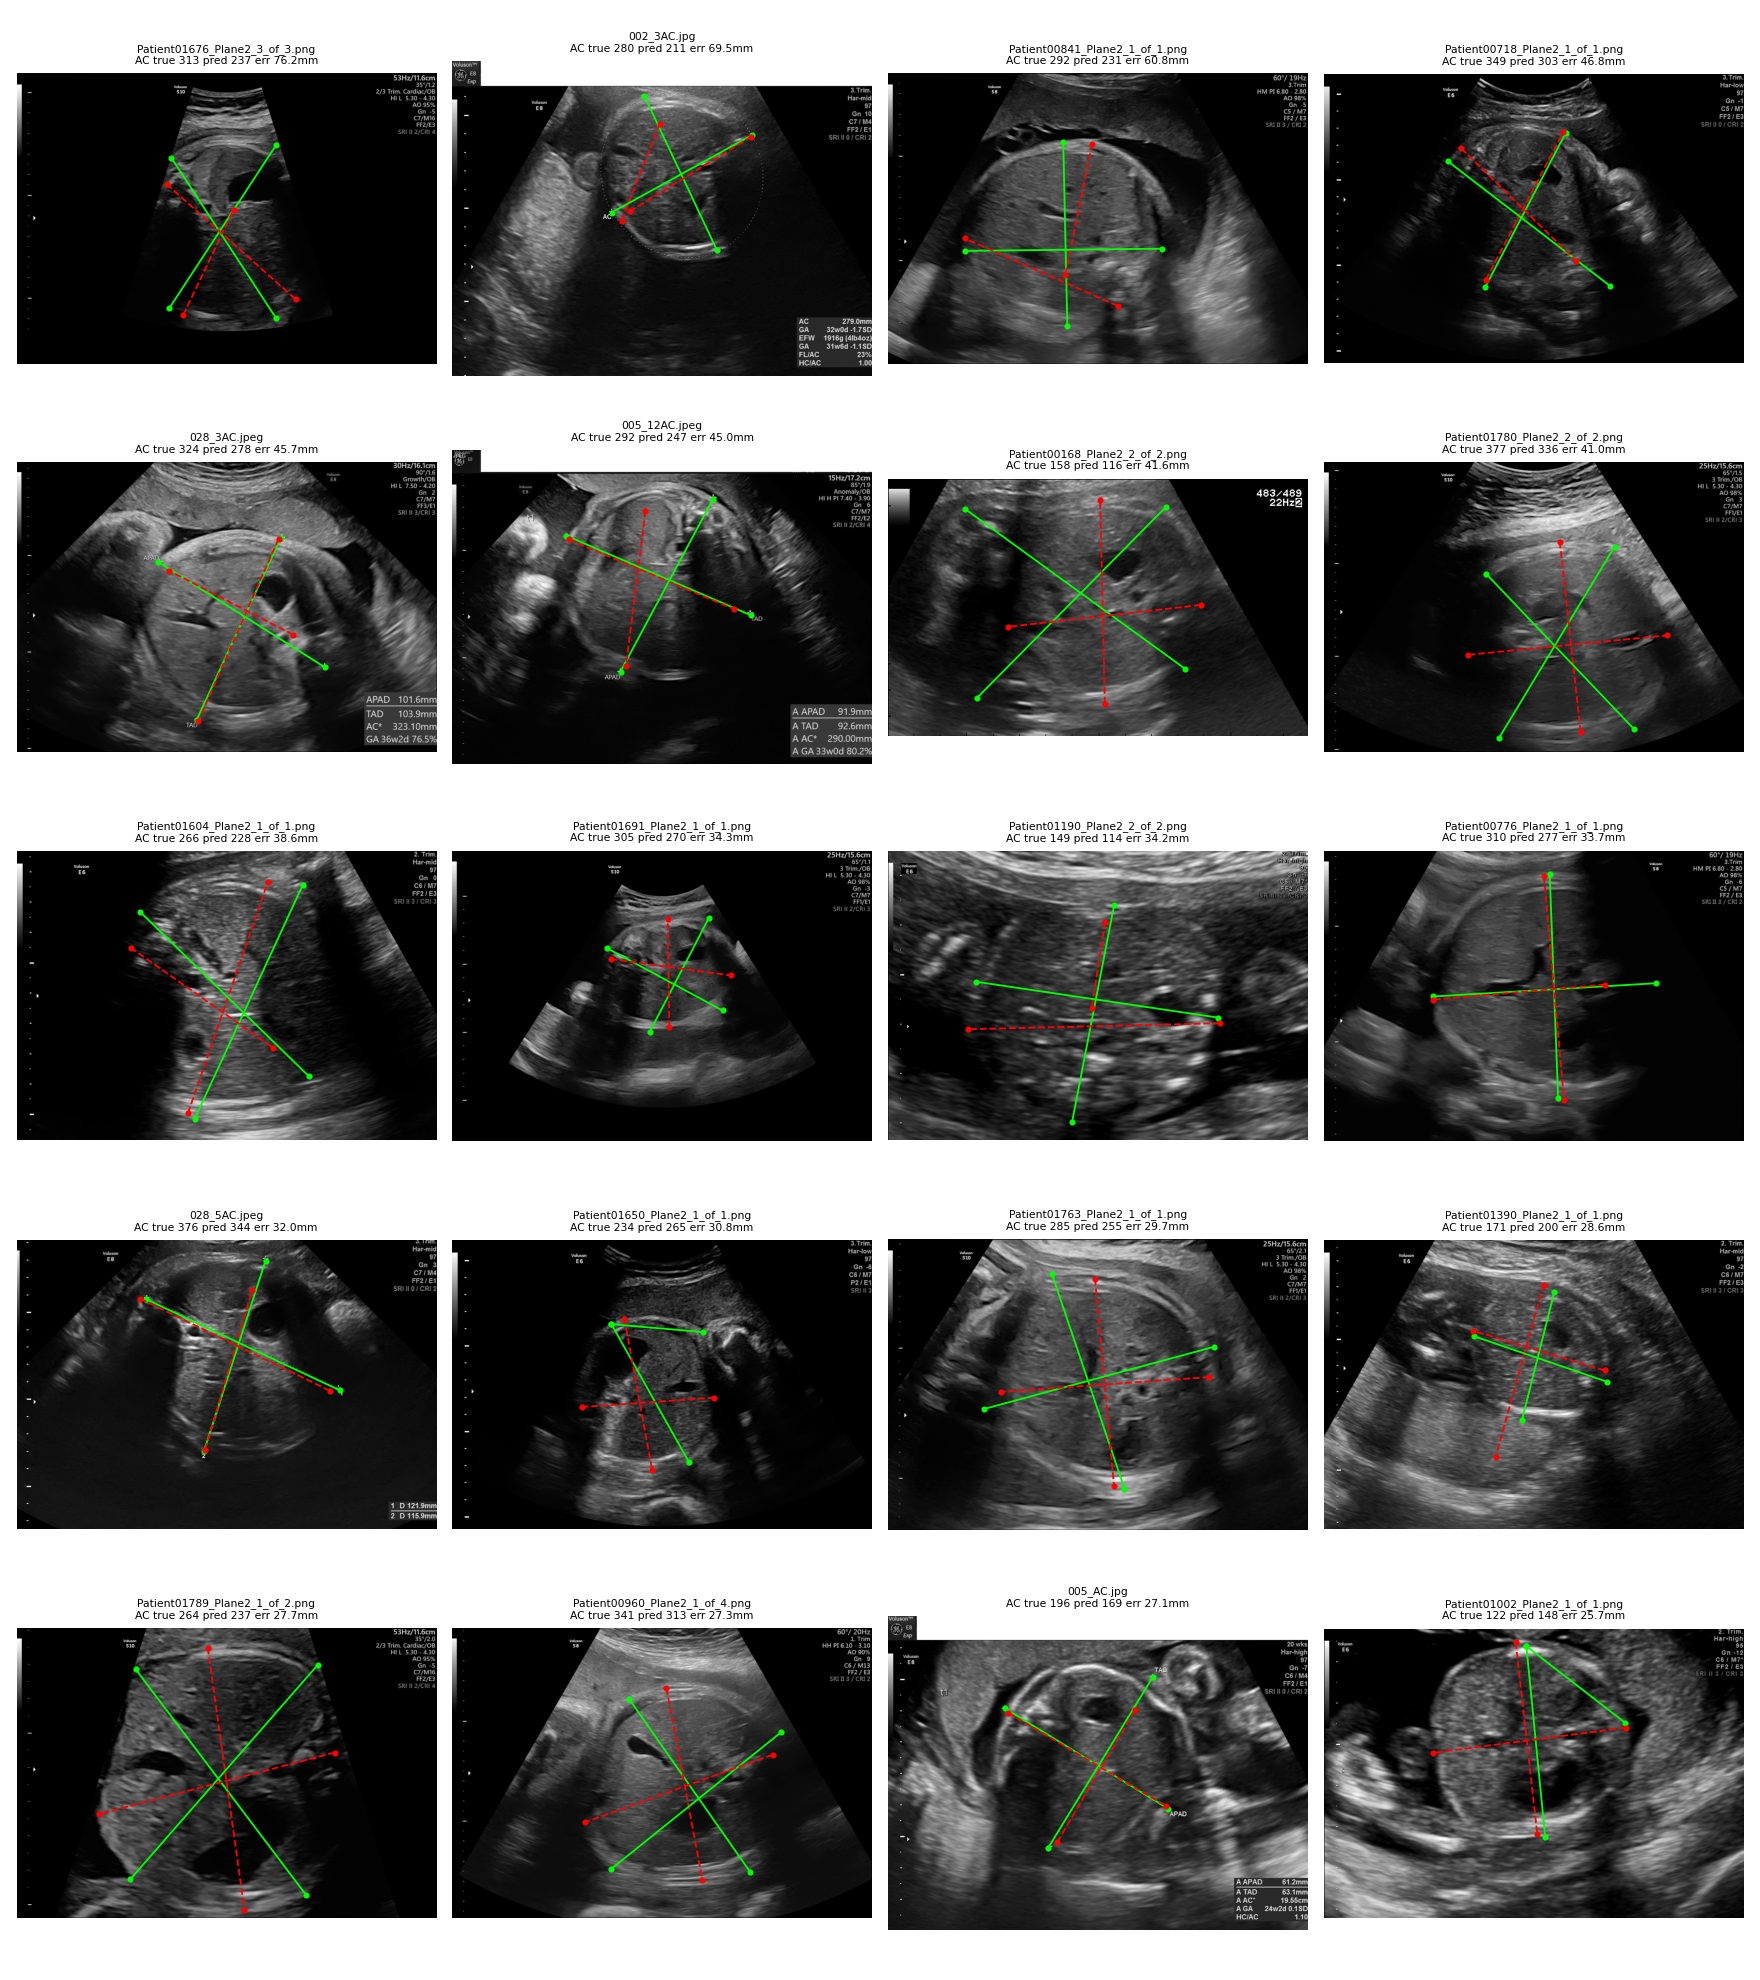


All consistency checks against the training log passed.
DONE. Send me the last ~40 lines of this output and worst20.png (green = annotation, red dashed = model).


In [ ]:
# AC diagnostics - reads the 5 trained fold models, trains NOTHING.
# Colab: run   !pip install -q segmentation-models-pytorch==0.5.0   in a cell first, then paste this whole file in one cell.
# Output: per-image errors (with image names), summaries, overlay pictures. Saved in <MODEL_DIR>/diagnostics.
import os, re, sys, time, math, warnings
import numpy as np
import pandas as pd
import cv2
import torch
from PIL import Image
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp
from sklearn.model_selection import GroupKFold

try:  # Colab only
    from google.colab import drive
    if not os.path.isdir("/content/drive/MyDrive"):
        drive.mount("/content/drive")
except Exception:
    pass

BASE = os.environ.get("DIAG_BASE", "/content/drive/MyDrive/fetal-health-project/data/raw/FETAL_BIOMETRY_ABDOMEN")
MODEL_DIR = os.environ.get("DIAG_MODELS", "/content/drive/MyDrive/fetal-health-project/models/ac_dsnt_full")
OUT_DIR = os.environ.get("DIAG_OUT", os.path.join(MODEL_DIR, "diagnostics"))
TEST_MODE = os.environ.get("DIAG_TEST") == "1"   # only used by my own sandbox test
os.makedirs(OUT_DIR, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N_FOLDS = 5
EXPECT = dict(images=789, patients=615, val_patients=[122, 123, 123, 124, 123], ac_mae=5.18, ac_tol=0.3)
LM = ["tad_1", "tad_2", "apad_1", "apad_2"]
COORD_COLS = [f"{n}_{a}" for n in LM for a in "xy"]
WARNINGS = []


def warn(msg):
    WARNINGS.append(msg)
    print("  !! WARNING:", msg)


print(f"device={DEVICE} | torch {torch.__version__} | smp {smp.__version__} | out={OUT_DIR}")
if smp.__version__ != "0.5.0":
    warn(f"smp version is {smp.__version__}, weights were trained with 0.5.0 -> pip install segmentation-models-pytorch==0.5.0")

# ----------------------------------------------------------------------------------------------
# 1. data (same files / same order as training)
# ----------------------------------------------------------------------------------------------

def read_names(path):
    if not os.path.isfile(path):
        return None
    d = pd.read_csv(path)
    col = "image_name" if "image_name" in d.columns else d.columns[0]
    return set(d[col].astype(str))


def load_source(src, ann_dir, img_dir):
    df = pd.read_csv(f"{ann_dir}/Abdomen.csv")
    print(f"  {src} csv columns: {list(df.columns)}")
    if src == "UCL":
        df = df[~df["image_name"].str.startswith("125_")]
    df = df.reset_index(drop=True)
    df["source"] = src
    df["image_path"] = df["image_name"].apply(lambda f: f"{img_dir}/{f}")
    if src == "FP":
        df["patient"] = df["image_name"].apply(lambda f: re.search(r"(Patient\d+)", f).group(1))
    else:
        df["patient"] = df["image_name"].apply(lambda f: re.match(r"(\d+)_", f).group(1))
    te, tr = read_names(f"{ann_dir}/Abdomen_Test.csv"), read_names(f"{ann_dir}/Abdomen_Train.csv")
    if te is not None:
        df["official_split"] = df["image_name"].astype(str).apply(lambda f: "test" if f in te else "train")
    elif tr is not None:
        df["official_split"] = df["image_name"].astype(str).apply(lambda f: "train" if f in tr else "test")
    else:
        df["official_split"] = "unknown"
    dev_cols = [c for c in df.columns if re.search(r"device|machine|scanner|system|manufact|probe", c, re.I)]
    df["device"] = df[dev_cols[0]].astype(str) if dev_cols else "NA"
    keep = ["image_name", "image_path", "source", "patient", "official_split", "device", "px_to_mm_rate"] + COORD_COLS
    return df[keep]


def build_data():
    fp = load_source("FP", f"{BASE}/FP/annotations", f"{BASE}/FP/images/Abdomen")
    ucl = load_source("UCL", f"{BASE}/UCL/annotations/px_to_mm", f"{BASE}/UCL/images/Abdomen")
    data = pd.concat([fp, ucl], ignore_index=True)
    missing = [p for p in data["image_path"] if not os.path.isfile(p)]
    assert not missing, f"{len(missing)} image files missing, e.g. {missing[:3]} - check BASE"
    assert data["px_to_mm_rate"].notna().all(), "rows without calibration"
    return data


def group_ids(df, scheme):
    fp = df["source"] == "FP"
    pre_fp = "FP_" if scheme in ("A", "D") else ""
    pre_ucl = "UCL_" if scheme in ("A", "C") else ""
    return np.where(fp, pre_fp + df["patient"], pre_ucl + df["patient"]).astype(str)


def legacy_group_kfold(groups, n, kind="quicksort"):
    uniq, inv = np.unique(groups, return_inverse=True)
    cnt = np.bincount(inv)
    order = np.argsort(cnt, kind=kind)[::-1]
    load = np.zeros(n)
    g2f = np.zeros(len(uniq), dtype=int)
    for g in order:
        k = int(np.argmin(load))
        load[k] += cnt[g]
        g2f[g] = k
    return g2f[inv]


def sk_group_kfold(groups, n):
    fold = np.full(len(groups), -1)
    for k, (_, va) in enumerate(GroupKFold(n_splits=n).split(np.arange(len(groups)), groups=groups)):
        fold[va] = k
    return fold


# ----------------------------------------------------------------------------------------------
# 2. image / model helpers
# ----------------------------------------------------------------------------------------------
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def letterbox(img, S):
    w, h = img.size
    scale = S / max(w, h)
    nw, nh = int(w * scale), int(h * scale)
    canvas = Image.new("RGB", (S, S), (0, 0, 0))
    px, py = (S - nw) // 2, (S - nh) // 2
    canvas.paste(img.resize((nw, nh)), (px, py))
    return canvas, scale, px, py


def to_tensor(canvas, norm):
    a = np.asarray(canvas, dtype=np.float32) / 255.0
    if norm == "imagenet":
        a = (a - MEAN) / STD
    return torch.from_numpy(np.ascontiguousarray(a.transpose(2, 0, 1)))


def decode(logits):
    """spatial softmax -> expected (x, y) in pixel-index units. logits (B,C,H,W) -> (B,C,2)"""
    B, C, H, W = logits.shape
    p = torch.softmax(logits.reshape(B, C, -1), dim=-1).reshape(B, C, H, W)
    xs = torch.arange(W, device=logits.device, dtype=torch.float32)
    ys = torch.arange(H, device=logits.device, dtype=torch.float32)
    x = (p.sum(2) * xs).sum(-1)
    y = (p.sum(3) * ys).sum(-1)
    return torch.stack([x, y], -1)


# the 8 allowed relabelings: swap ends inside a pair, swap the two pairs
PERMS = []
for sp in (0, 1):
    for s0 in (0, 1):
        for s1 in (0, 1):
            a = [1, 0] if s0 else [0, 1]
            b = [3, 2] if s1 else [2, 3]
            PERMS.append(b + a if sp else a + b)


def match(points, ref):
    best, best_d = None, 1e18
    for order in PERMS:
        d = np.linalg.norm(points[order] - ref, axis=1).mean()
        if d < best_d:
            best, best_d = points[order], d
    return best


def load_model(path):
    ck = torch.load(path, map_location="cpu", weights_only=False)
    cfg = ck.get("config", {}) if isinstance(ck, dict) else {}
    S = 384
    for key in ("IMG_SIZE", "img_size", "image_size", "size"):
        if key in cfg:
            S = int(cfg[key])
            break
    model = smp.Unet(encoder_name="efficientnet-b4", encoder_weights=None, in_channels=3, classes=4)
    model.load_state_dict(ck["model_state"])
    return model.to(DEVICE).eval(), ck, S


@torch.no_grad()
def predict(model, img, S, norm, tta=True):
    canvas, scale, px, py = letterbox(img, S)
    t = to_tensor(canvas, norm).unsqueeze(0).to(DEVICE)
    with torch.autocast(device_type=DEVICE, enabled=(DEVICE == "cuda")):
        lo0 = model(t)
        lo1 = model(torch.flip(t, dims=[3])) if tta else None
    p0 = decode(lo0.float())[0].cpu().numpy()
    p = p0
    if tta:
        p1 = decode(lo1.float())[0].cpu().numpy()
        p1[:, 0] = S - 1 - p1[:, 0]
        p = (p0 + match(p1, p0)) / 2.0
    return p0, p, scale, px, py


def ac_mm(tad, apad):
    a, b = tad / 2.0, apad / 2.0   # semi-axes
    return math.pi * (3 * (a + b) - math.sqrt((3 * a + b) * (a + 3 * b)))


def yellow_fraction(arr):
    hsv = cv2.cvtColor(arr, cv2.COLOR_RGB2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    return float(((h >= 18) & (h <= 38) & (s >= 100) & (v >= 120)).mean())


# ----------------------------------------------------------------------------------------------
# 3. per-image scoring
# ----------------------------------------------------------------------------------------------

def score_image(row, pred_native):
    gt = row[COORD_COLS].to_numpy(dtype=float).reshape(4, 2)
    pr = match(pred_native, gt)
    rate = float(row["px_to_mm_rate"])
    d = np.linalg.norm(pr - gt, axis=1)               # px error per landmark
    tad_t = np.linalg.norm(gt[1] - gt[0]); apad_t = np.linalg.norm(gt[3] - gt[2])
    tad_p = np.linalg.norm(pr[1] - pr[0]); apad_p = np.linalg.norm(pr[3] - pr[2])
    ac_t, ac_p = ac_mm(tad_t * rate, apad_t * rate), ac_mm(tad_p * rate, apad_p * rate)
    out = dict(
        tad_true_mm=tad_t * rate, tad_pred_mm=tad_p * rate, apad_true_mm=apad_t * rate, apad_pred_mm=apad_p * rate,
        ac_true_mm=ac_t, ac_pred_mm=ac_p, ac_err_mm=abs(ac_p - ac_t), ac_err_pct=100 * abs(ac_p - ac_t) / ac_t,
        tad_err_mm=abs(tad_p - tad_t) * rate, apad_err_mm=abs(apad_p - apad_t) * rate,
        tad_len_err_pct=100 * abs(tad_p - tad_t) / tad_t, apad_len_err_pct=100 * abs(apad_p - apad_t) / apad_t,
        lm_err_mm=float(d.mean() * rate), lm_err_px=float(d.mean()),
        nme_tad=float(d[:2].mean() / tad_t), nme_apad=float(d[2:].mean() / apad_t),
    )
    out["nme"] = (out["nme_tad"] + out["nme_apad"]) / 2
    for i, n in enumerate(LM):
        out[f"pr_{n}_x"], out[f"pr_{n}_y"] = float(pr[i, 0]), float(pr[i, 1])
    return out


def run_all(data, fold, models, sizes, norm):
    rows = []
    t0 = time.time()
    for i in range(len(data)):
        r = data.iloc[i]
        k = int(fold[i])
        img = Image.open(r["image_path"]).convert("RGB")
        arr = np.asarray(img)
        _, p, scale, px, py = predict(models[k], img, sizes[k], norm, tta=True)
        native = (p - np.array([px, py], dtype=np.float32)) / scale
        res = score_image(r, native)
        res.update(image_name=r["image_name"], source=r["source"], patient=r["patient"], fold=k + 1,
                   official_split=r["official_split"], device=r["device"], px_to_mm_rate=r["px_to_mm_rate"],
                   width=img.size[0], height=img.size[1], yellow_frac=yellow_fraction(arr),
                   image_path=r["image_path"])
        for c in COORD_COLS:
            res["gt_" + c] = float(r[c])
        rows.append(res)
        if (i + 1) % 100 == 0:
            print(f"  scored {i+1}/{len(data)} images ({time.time()-t0:.0f}s)")
    return pd.DataFrame(rows)


# ----------------------------------------------------------------------------------------------
# 4. summaries
# ----------------------------------------------------------------------------------------------

def stat_line(s):
    s = pd.Series(s).astype(float)
    return (f"n={len(s):4d} mean={s.mean():6.2f} median={s.median():6.2f} rmse={math.sqrt((s**2).mean()):6.2f} "
            f"p90={s.quantile(.9):6.2f} p95={s.quantile(.95):6.2f} p99={s.quantile(.99):6.2f} max={s.max():7.2f}")


def add_bins(df):
    df = df.copy()
    df["marker"] = np.where(df["yellow_frac"] > 5e-4, "yellow_marker", "no_marker")
    try:
        df["rate_group"] = pd.qcut(df["px_to_mm_rate"], 3, labels=["rate_low", "rate_mid", "rate_high"], duplicates="drop")
    except Exception:
        df["rate_group"] = "all"
    try:
        df["ac_bin"] = pd.qcut(df["ac_true_mm"], 4, duplicates="drop").astype(str)
    except Exception:
        df["ac_bin"] = "all"
    return df


def print_summary(df):
    print("\n" + "=" * 100)
    print("OVERALL (out-of-fold, flip-TTA, native resolution, mm)")
    for col, name in [("ac_err_mm", "AC  abs err mm"), ("tad_err_mm", "TAD abs err mm"), ("apad_err_mm", "APAD abs err mm"),
                      ("lm_err_mm", "landmark err mm"), ("ac_err_pct", "AC  err %")]:
        print(f"  {name:16s} {stat_line(df[col])}")
    n = len(df)
    for thr in (10, 20, 30):
        print(f"  AC error > {thr:2d} mm: {int((df.ac_err_mm > thr).sum()):4d} images ({100*(df.ac_err_mm>thr).mean():.1f}%)")
    k = max(1, math.ceil(0.05 * n))
    sq = np.sort(df.ac_err_mm.to_numpy() ** 2)[::-1]
    print(f"  worst 5% of images ({k}) carry {100*sq[:k].sum()/sq.sum():.1f}% of the squared AC error")
    ac_rmse = math.sqrt((df.ac_err_mm ** 2).mean())
    print(f"  AC MAE {df.ac_err_mm.mean():.2f} mm | RMSE {ac_rmse:.2f} mm | median {df.ac_err_mm.median():.2f} mm")
    print(f"  NME (landmark err / true diameter): TAD {df.nme_tad.mean():.4f} | APAD {df.nme_apad.mean():.4f} | mean {df.nme.mean():.4f}")
    print("  (paper's BiometryNet/HRNet baseline is roughly 0.07-0.08; split + exact formula differ, so only a rough guide)")
    d = add_bins(df)
    for col in ["source", "official_split", "device", "rate_group", "ac_bin", "marker", "fold"]:
        print("\n  -- by " + col)
        for key, g in d.groupby(col, observed=True):
            print(f"    {str(key):28s} AC mm: {stat_line(g.ac_err_mm)} | NME {g.nme.mean():.4f}")
    print("\n  yellow_frac quantiles:", {q: round(float(d.yellow_frac.quantile(q)), 5) for q in (.5, .9, .95, .99)})


def draw(ax, r):
    img = np.asarray(Image.open(r["image_path"]).convert("L"))
    ax.imshow(img, cmap="gray")
    for a, b in ((0, 1), (2, 3)):
        gx = [r[f"gt_{LM[a]}_x"], r[f"gt_{LM[b]}_x"]]; gy = [r[f"gt_{LM[a]}_y"], r[f"gt_{LM[b]}_y"]]
        px_ = [r[f"pr_{LM[a]}_x"], r[f"pr_{LM[b]}_x"]]; py_ = [r[f"pr_{LM[a]}_y"], r[f"pr_{LM[b]}_y"]]
        ax.plot(gx, gy, "-o", color="lime", ms=3, lw=1.2)
        ax.plot(px_, py_, "--o", color="red", ms=3, lw=1.2)
    ax.set_title(f"{r['image_name']}\nAC true {r['ac_true_mm']:.0f} pred {r['ac_pred_mm']:.0f} err {r['ac_err_mm']:.1f}mm", fontsize=7)
    ax.axis("off")


def make_sheet(rows, path, ncols=4):
    n = len(rows)
    nr = max(1, math.ceil(n / ncols))
    fig, axs = plt.subplots(nr, ncols, figsize=(4 * ncols, 3.6 * nr))
    axs = np.atleast_1d(axs).ravel()
    for ax in axs:
        ax.axis("off")
    for ax, (_, r) in zip(axs, rows.iterrows()):
        draw(ax, r)
    plt.tight_layout()
    fig.savefig(path, dpi=110)
    plt.close(fig)
    print("  saved", path)


# ----------------------------------------------------------------------------------------------
# 5. main
# ----------------------------------------------------------------------------------------------
if __name__ == "__main__" or True:
    print("\nLoading data ...")
    data = build_data()
    print(f"  {len(data)} images, {data['patient'].nunique()} patients ({data.groupby('source')['patient'].nunique().to_dict()})")
    if not TEST_MODE and len(data) != EXPECT["images"]:
        warn(f"expected {EXPECT['images']} images, got {len(data)}")

    print("\nLoading models ...")
    models, sizes, cks = [], [], []
    for k in range(1, N_FOLDS + 1):
        path = f"{MODEL_DIR}/fold{k}_final.pt"
        m, ck, S = load_model(path)
        models.append(m); sizes.append(S); cks.append(ck)
        flag = (ck.get("completed", None), ck.get("best_px", None))
        print(f"  fold {k}: size={S} completed/best_px={flag}")
        if k == 1:
            print("  config keys:", {kk: (vv if not isinstance(vv, (dict, list)) or len(str(vv)) < 80 else '...') for kk, vv in ck.get("config", {}).items()})
        if not TEST_MODE:
            if ck.get("completed") is not True:
                warn(f"fold {k} checkpoint is not marked completed")
            cfg = ck.get("config", {})
            if cfg.get("n_images", EXPECT["images"]) != EXPECT["images"]:
                warn(f"fold {k} trained on {cfg.get('n_images')} images, not {EXPECT['images']}")
            if cfg.get("smoke", False):
                warn(f"fold {k} is a SMOKE-TEST model")
    best_px = [float(ck.get("best_px", float("nan"))) for ck in cks]

    # ---- find the fold assignment + preprocessing that reproduces the training log -------------
    print("\nReproducing the training folds ...")
    cands = {}
    for scheme in "ABCD":
        g = group_ids(data, scheme)
        for algo, fn in (("sklearn", sk_group_kfold), ("legacy", legacy_group_kfold),
                         ("stable", lambda g, n: legacy_group_kfold(g, n, "stable"))):
            f = fn(g, N_FOLDS)
            cands.setdefault(tuple(f.tolist()), []).append(f"{scheme}/{algo}")
    cand_list = [(np.array(k), v) for k, v in cands.items()]
    print(f"  {len(cand_list)} distinct fold assignments from {sum(len(v) for _, v in cand_list)} id-scheme/algorithm variants (sklearn {__import__('sklearn').__version__})")

    def val_patients(f):
        return [int(data.loc[f == k, "patient"].nunique()) for k in range(N_FOLDS)]

    ok_cands = [(f, v) for f, v in cand_list if TEST_MODE or val_patients(f) == EXPECT["val_patients"]]
    if not ok_cands:
        warn("no fold assignment reproduces the logged validation patient counts [122,123,123,124,123] - using all candidates")
        ok_cands = cand_list
    print(f"  {len(ok_cands)} assignments match the logged patient counts")

    def fold_px(f, k, norm, limit=None):
        idx = np.where(f == k)[0][:limit]
        errs = []
        for i in idx:
            r = data.iloc[i]
            img = Image.open(r["image_path"]).convert("RGB")
            p0, _, scale, px, py = predict(models[k], img, sizes[k], norm, tta=False)
            gt = r[COORD_COLS].to_numpy(dtype=float).reshape(4, 2) * scale + np.array([px, py])
            errs.append(np.linalg.norm(match(p0, gt) - gt, axis=1).mean())
        return float(np.mean(errs))

    best = None
    for norm in ("imagenet", "none"):
        for f, names in ok_cands:
            e = fold_px(f, 0, norm)
            rel = abs(e - best_px[0]) / best_px[0] if best_px[0] == best_px[0] else 9
            print(f"  try norm={norm:8s} folds={names[0]:10s} -> fold-1 val landmark err {e:6.2f}px (log said {best_px[0]:.2f}) rel diff {rel:.2f}")
            if best is None or rel < best[0]:
                best = (rel, f, names, norm)
        if best[0] < 0.25:
            break
    rel, fold, names, NORM = best
    print(f"  -> using folds from {names}, normalisation={NORM} (rel diff on fold-1 val: {rel:.2f})")
    if rel > 0.25 and not TEST_MODE:
        warn("could not reproduce fold-1 landmark error from the training log (decode/preprocessing/folds differ) - results below may be unreliable")

    print("\nPer-fold check against the training log (no TTA, model space px):")
    for k in range(N_FOLDS):
        e = fold_px(fold, k, NORM)
        print(f"  fold {k+1}: recomputed {e:6.2f}px | training log best {best_px[k]:6.2f}px")
        if not TEST_MODE and abs(e - best_px[k]) / best_px[k] > 0.12:
            warn(f"fold {k+1} landmark error differs >12% from the training log")

    print("\nLeakage check (a truly held-out fold must have HIGHER error than images the model trained on):")
    rs = np.random.RandomState(0)
    for k in range(N_FOLDS):
        tr_idx = (lambda a: rs.choice(a, min(60, len(a)), replace=False))(np.where(fold != k)[0])
        errs = []
        for i in tr_idx:
            r = data.iloc[i]
            img = Image.open(r["image_path"]).convert("RGB")
            p0, _, scale, px, py = predict(models[k], img, sizes[k], NORM, tta=False)
            gt = r[COORD_COLS].to_numpy(dtype=float).reshape(4, 2) * scale + np.array([px, py])
            errs.append(np.linalg.norm(match(p0, gt) - gt, axis=1).mean())
        print(f"  fold {k+1}: error on 60 training-side images {np.mean(errs):6.2f}px")

    print("\nScoring every image with its held-out fold model (flip-TTA) ...")
    df = run_all(data, fold, models, sizes, NORM)
    df.to_csv(f"{OUT_DIR}/oof_diagnostics.csv", index=False)
    print("  saved", f"{OUT_DIR}/oof_diagnostics.csv")

    if not TEST_MODE and abs(df.ac_err_mm.mean() - EXPECT["ac_mae"]) > EXPECT["ac_tol"]:
        warn(f"AC MAE {df.ac_err_mm.mean():.2f} differs from the logged {EXPECT['ac_mae']} by more than {EXPECT['ac_tol']}")

    print_summary(df)

    srt = df.sort_values("ac_err_mm", ascending=False)
    print("\nWORST 10 images:")
    cols = ["image_name", "source", "fold", "ac_true_mm", "ac_pred_mm", "ac_err_mm", "lm_err_mm", "yellow_frac"]
    print(srt[cols].head(10).round(3).to_string(index=False))

    make_sheet(srt.head(20), f"{OUT_DIR}/worst20.png")
    make_sheet(df.sample(n=min(10, len(df)), random_state=0), f"{OUT_DIR}/random10.png")
    try:
        from IPython.display import display, Image as IPImage
        display(IPImage(f"{OUT_DIR}/worst20.png"))
    except Exception:
        pass

    print("\n" + "=" * 100)
    if WARNINGS:
        print("WARNINGS:")
        for w in WARNINGS:
            print("  -", w)
    else:
        print("All consistency checks against the training log passed.")
    print("DONE. Send me the last ~40 lines of this output and worst20.png (green = annotation, red dashed = model).")

#Code for test B4U efficient technic in abdomen dataset

In [ ]:
# AC v3 - overnight round 2: 5 seeds of the winning recipe (each with a DIFFERENT dev hold-out), one 512-px run,
# then the 5-model ensemble on the official test set. Needs ac_v3.py in the SAME folder (it imports it; change nothing in it).
# Reports mean +- SD over seeds (honest run-to-run spread), the ensemble, and per-diameter NME as mean +- SD
# (the format used in the multicentre benchmark paper, FP->FP: TAD 0.08+-0.06, APAD 0.08+-0.06; M-C->M-C: 0.08 / 0.07).
# Resumable: stop it any time, run it again.
#   python -u ac_v3_ens.py 2>&1 | ForEach-Object { "$_" } | Tee-Object -FilePath ens_log.txt -Append
import os, json, time, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import ac_v3 as A

OUT_ENS = A.OUT + "_ens"
SEEDS = [1, 2] if A.SMOKE else [1, 2, 3, 4, 5]
RECIPE = dict(img=128 if A.SMOKE else 384, diam_w=1.0, strong_aug=True, inpaint=True)
CFGS = [dict(name=f"s{s}", seed=s, batch=A.BATCH, **RECIPE) for s in SEEDS]
CFG_512 = dict(name="res512", seed=1, batch=2, img=160 if A.SMOKE else 512, diam_w=1.0, strong_aug=True, inpaint=True)


def split_seed(data, seed):
    train_all = data[data.official_split == "train"]
    pats = np.array(sorted(train_all.patient.unique()))
    rng = np.random.RandomState(seed)
    dev_p = set(rng.permutation(pats)[: max(1, int(round(A.DEV_FRACTION * len(pats))))])
    tr = train_all[~train_all.patient.isin(dev_p)].reset_index(drop=True)
    dv = train_all[train_all.patient.isin(dev_p)].reset_index(drop=True)
    te = data[data.official_split == "test"].reset_index(drop=True)
    assert not (set(tr.patient) & set(dv.patient)) and not (set(tr.patient) & set(te.patient)), "patient overlap!"
    return tr, dv, te


def train_one(cfg, data):
    d = f"{OUT_ENS}/{cfg['name']}"
    os.makedirs(d, exist_ok=True)
    if os.path.isfile(f"{d}/DONE"):
        print(f"[{cfg['name']}] finished earlier -> skipping")
        return d
    S, seed = cfg["img"], cfg["seed"]
    tr, dv, _ = split_seed(data, seed)
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    model = A.build_model().to(A.DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=A.LR, weight_decay=0.01)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=4)
    scaler = torch.amp.GradScaler(A.DEVICE, enabled=(A.DEVICE == "cuda"))
    start, best, bad = 0, float("inf"), 0
    last = f"{d}/last.pt"
    if os.path.isfile(last):
        ck = torch.load(last, map_location=A.DEVICE, weights_only=False)
        assert ck["cfg"] == cfg, f"checkpoint config differs - delete {d} to start over"
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
        scaler.load_state_dict(ck["scaler"]); start, best, bad = ck["epoch"] + 1, ck["best"], ck["bad"]
        print(f"[{cfg['name']}] resumed at epoch {start}, best dev score {best:.3f}")
    trd = tr.head(24) if A.SMOKE else tr
    dl = DataLoader(A.AbdomenDS(trd, S, True, cfg["strong_aug"], cfg["inpaint"]), batch_size=cfg["batch"], shuffle=True,
                    num_workers=A.NUM_WORKERS, drop_last=True)
    for ep in range(start, A.MAX_EPOCHS):
        t0 = time.time()
        model.train()
        tl = 0.0
        for x, gt, mmpp, _ in dl:
            x, gt, mmpp = x.to(A.DEVICE), gt.to(A.DEVICE), mmpp.to(A.DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=A.DEVICE, enabled=(A.DEVICE == "cuda")):
                logits = model(x)
            loss, _ = A.compute_loss(logits, gt, mmpp, S, cfg["diam_w"])
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt); scaler.update()
            tl += loss.item()
        s = A.summarize(A.run_eval(model, dv.head(16) if A.SMOKE else dv, cfg, tta=False))
        score = s["ac_mae"] + s["lm_mm"]
        sched.step(score)
        improved = score < best
        if improved:
            best, bad = score, 0
            A.atomic_save(model.state_dict(), f"{d}/best.pt")
        else:
            bad += 1
        print(f"[{cfg['name']}] ep {ep+1:3d}/{A.MAX_EPOCHS} loss={tl/len(dl):.4f} | dev AC MAE {s['ac_mae']:.2f}mm lm {s['lm_mm']:.2f}mm "
              f"| score {score:.3f}{' *' if improved else ''} | {time.time()-t0:.0f}s | bad={bad}", flush=True)
        A.atomic_save(dict(cfg=cfg, model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                           scaler=scaler.state_dict(), epoch=ep, best=best, bad=bad), last)
        if bad >= A.PATIENCE:
            print(f"[{cfg['name']}] early stop")
            break
    open(f"{d}/DONE", "w").write("ok")
    return d


@torch.no_grad()
def eval_models(dirs, S, te, inpaint, agg="mean"):
    models = []
    for d in dirs:
        m = A.build_model().to(A.DEVICE)
        m.load_state_dict(torch.load(f"{d}/best.pt", map_location=A.DEVICE))
        models.append(m.eval())
    ds = A.AbdomenDS(te, S, False, False, inpaint)
    dl = DataLoader(ds, batch_size=8, shuffle=False, num_workers=A.NUM_WORKERS)
    rows = []
    for x, gt, mmpp, idx in dl:
        x, gt, mmpp = x.to(A.DEVICE), gt.to(A.DEVICE), mmpp.to(A.DEVICE)
        preds = [A.predict_batch(m, x, True) for m in models]
        ref = preds[0]
        stack = torch.stack([ref] + [A.match(p, ref)[0] for p in preds[1:]])
        pred = stack.mean(0) if agg == "mean" else stack.median(0).values
        m_ = A.metrics_rows(pred, gt, mmpp)
        pm, _ = A.match(pred, gt)
        dd = (pm - gt).norm(dim=-1)
        tl, al = (gt[:, 1] - gt[:, 0]).norm(dim=-1), (gt[:, 3] - gt[:, 2]).norm(dim=-1)
        m_["nme_tad"], m_["nme_apad"] = dd[:, :2].mean(-1) / tl, dd[:, 2:].mean(-1) / al
        for j in range(len(idx)):
            r = te.iloc[int(idx[j])]
            rows.append({k: float(v[j]) for k, v in m_.items()} | {"image_name": r["image_name"], "source": r["source"]})
    return pd.DataFrame(rows)


def summ(r):
    s = A.summarize(r)
    s |= dict(tad_nme=r.nme_tad.mean(), tad_nme_sd=r.nme_tad.std(), apad_nme=r.nme_apad.mean(), apad_nme_sd=r.nme_apad.std(),
              ac_pct=float((100 * r.ac_err / r.ac_true).mean()))
    return s


def main():
    os.makedirs(OUT_ENS, exist_ok=True)
    print(f"device={A.DEVICE} | out={OUT_ENS} | seeds={SEEDS} | smoke={A.SMOKE}")
    data = A.build_data()
    _, _, te = split_seed(data, 1)
    te_use = te.head(16) if A.SMOKE else te
    print(f"official test: {len(te)} images ({te.patient.nunique()} patients)")
    dirs = [train_one(c, data) for c in CFGS]
    d512 = train_one(CFG_512, data)

    res = {}
    for c, d in zip(CFGS, dirs):
        res[c["name"]] = summ(eval_models([d], c["img"], te_use, True))
    res["res512"] = summ(eval_models([d512], CFG_512["img"], te_use, True))
    r_mean = eval_models(dirs, RECIPE["img"], te_use, True, "mean")
    r_med = eval_models(dirs, RECIPE["img"], te_use, True, "median")
    res["ENS_mean"], res["ENS_median"] = summ(r_mean), summ(r_med)
    r_mean.to_csv(f"{OUT_ENS}/ensemble_test_predictions.csv", index=False)
    json.dump(res, open(f"{OUT_ENS}/results.json", "w"), indent=1, default=float)

    print("\n" + "=" * 118 + "\nOFFICIAL TEST SET, flip-TTA, mm (lower is better)")
    print(f"{'model':11s} {'AC MAE':>7s} {'RMSE':>6s} {'median':>7s} {'bias':>7s} {'AC %':>6s} {'>10mm':>6s} | {'TAD NME':>13s} {'APAD NME':>13s}")
    for k, s in res.items():
        print(f"{k:11s} {s['ac_mae']:7.2f} {s['ac_rmse']:6.2f} {s['ac_median']:7.2f} {s['ac_bias']:+7.2f} {s['ac_pct']:6.2f} "
              f"{100*s['over10']:5.1f}% | {s['tad_nme']:.3f}+-{s['tad_nme_sd']:.3f} {s['apad_nme']:.3f}+-{s['apad_nme_sd']:.3f}")
    mae = np.array([res[c['name']]['ac_mae'] for c in CFGS])
    print(f"\nsingle 384-px seeds: AC MAE {mae.mean():.2f} +- {mae.std(ddof=1) if len(mae) > 1 else float('nan'):.2f} mm "
          f"(min {mae.min():.2f}, max {mae.max():.2f})")
    print("paper (BiometryNet/HRNet-W18, NME mean+-SD): FP->FP TAD 0.08+-0.06 APAD 0.08+-0.06 | M-C->M-C TAD 0.08+-0.08 APAD 0.07+-0.08")
    print("DONE. Send me this table.")


if __name__ == "__main__":
    main()

##Result are saved in locally file as s1  - s5